# Exact Diagonalization and Quantum Chaos in an XXZ Spin Chain

## 1. Definition of the system

We study a one-dimensional spin-$1/2$ XXZ chain with open boundary conditions and an additional next-nearest-neighbour interaction.

The Hamiltonian is

$$
H(\lambda)=H_{\mathrm{NN}}+\lambda H_{\mathrm{NNN}},
$$

where

$$
H_{\mathrm{NN}}
=
J\sum_{i=1}^{L-1}
\left(
S_i^x S_{i+1}^x
+
S_i^y S_{i+1}^y
+
\Delta S_i^z S_{i+1}^z
\right),
$$

and

$$
H_{\mathrm{NNN}}
=
J\sum_{i=1}^{L-2}
\left(
S_i^x S_{i+2}^x
+
S_i^y S_{i+2}^y
+
\Delta S_i^z S_{i+2}^z
\right).
$$

We use units such that

$$
\hbar = J = 1.
$$

Unless otherwise stated, we choose

$$
\Delta = 0.7.
$$

For $\lambda=0$, the model reduces to the integrable XXZ chain.

For finite $\lambda$, the next-nearest-neighbour interaction generically breaks integrability.

In [194]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from scipy.linalg import eigh
from math import comb

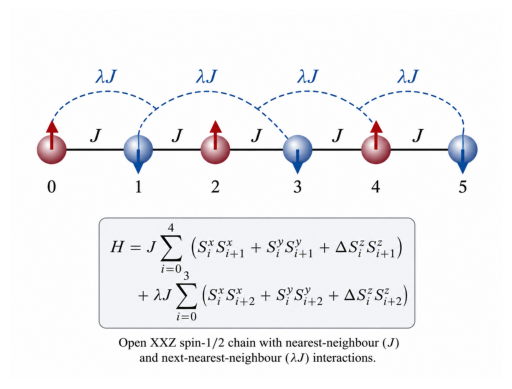

In [195]:
img = mpimg.imread(r"C:\Users\rujao\OneDrive\Documentos\Quantic papers\Cadena_abierta_sìnes.png")

plt.imshow(img)
plt.axis('off') 
plt.show()


## 1.1 Local Spin Operators

Each site of the chain contains a spin-$1/2$ degree of freedom whose local Hilbert space is

$$
\mathcal{H}_i \simeq \mathbb{C}^2.
$$

In units where

$$
\hbar = 1,
$$

the spin operators are related to the Pauli matrices through

$$
S^\alpha = \frac{1}{2}\sigma^\alpha,
\qquad
\alpha \in \{x,y,z\}.
$$

The Pauli matrices are

$$
\sigma_x =
\begin{pmatrix}
0 & 1\\
1 & 0
\end{pmatrix},
\qquad
\sigma_y =
\begin{pmatrix}
0 & -i\\
i & 0
\end{pmatrix},
\qquad
\sigma_z =
\begin{pmatrix}
1 & 0\\
0 & -1
\end{pmatrix}.
$$

Therefore,

$$
S^x = \frac{\sigma_x}{2},
\qquad
S^y = \frac{\sigma_y}{2},
\qquad
S^z = \frac{\sigma_z}{2}.
$$

These local $2\times2$ matrices constitute the elementary building blocks from which the many-body operators and the XXZ Hamiltonian will be constructed.

In [196]:
I2 = np.eye(2, dtype=complex)

sigmax = np.array([
    [0,1],
    [1,0] 
], dtype=complex)

sigmay = np.array([
    [0, -1j],
    [1j, 0]
], dtype=complex)

sigmaz = np.array([
    [1, 0],
    [0,-1]
], dtype=complex)

Sx = 0.5*sigmax
Sy = 0.5*sigmay
Sz = 0.5*sigmaz

## 1.2 Local Basis and Spin Algebra

We work in the eigenbasis of $S^z$,

$$
|\uparrow\rangle =
\begin{pmatrix}
1\\
0
\end{pmatrix},
\qquad
|\downarrow\rangle =
\begin{pmatrix}
0\\
1
\end{pmatrix}.
$$

These states satisfy

$$
S^z|\uparrow\rangle
=
+\frac{1}{2}|\uparrow\rangle,
$$

and

$$
S^z|\downarrow\rangle
=
-\frac{1}{2}|\downarrow\rangle.
$$

The spin operators obey the angular-momentum algebra, and therefore prove that the spin follows the algebra the Lie of the group of rotations $SU(2)$.

$$
[S^\alpha,S^\beta]
=
i\epsilon_{\alpha\beta\gamma}S^\gamma.
$$

In particular,

$$
[S^x,S^y]
=
iS^z.
$$

Before constructing the many-body Hamiltonian, we verify numerically that the matrix representation of the spin operators satisfies this algebra.

This provides a simple but important consistency test for the local operator definitions.

In [197]:
commutator_xy = Sx@Sy - Sy@Sx
print(commutator_xy)
print(1j*Sz)
print("Commmutation relation correct:" ,
    np.allclose(commutator_xy, 1j*Sz)
)

[[0.+0.5j 0.+0.j ]
 [0.+0.j  0.-0.5j]]
[[ 0.+0.5j  0.+0.j ]
 [ 0.+0.j  -0.-0.5j]]
Commmutation relation correct: True


## 1.3 Embedding Local Operators into the Many-Body Hilbert Space

For a chain containing $L$ spins, the total Hilbert space is

$$
\mathcal{H}
=
\bigotimes_{i=0}^{L-1}\mathcal{H}_i
=
(\mathbb{C}^2)^{\otimes L}.
$$

Its dimension is therefore

$$
D = 2^L.
$$

A local operator acting on a single lattice site must be embedded into this many-body Hilbert space.

For example, for a three-site chain, an operator $S^z$ acting on the first site is represented by

$$
S_0^z
=
S^z\otimes I\otimes I,
$$

whereas the same operator acting on the second site is

$$
S_1^z
=
I\otimes S^z\otimes I.
$$

In general,

$$
S_i^\alpha
=
I\otimes\cdots\otimes
S^\alpha
\otimes\cdots\otimes I,
$$

where $S^\alpha$ occupies the tensor-product position associated with site $i$.

The following numerical implementation performs this embedding using repeated Kronecker products.

Although this construction is computationally expensive for large $L$, it provides a transparent implementation of the many-body operator structure and will later serve as an independent reference for validating a more efficient binary implementation.

In [198]:
def local_operator(
    operator: np.ndarray,
    site: int,
    L: int
) -> np.ndarray:
    """
    Embed a single-spin operator into an L-spin Hilbert space.

    Parameters
    ----------
    operator:
        2x2 single-spin operator.
    site:
        Site where the operator acts, using zero-based indexing.
    L:
        Number of spins.

    Returns
    -------
    np.ndarray
        Full 2**L x 2**L many-body operator.
    """
    operators = [I2 for _ in range(L)]
    operators[site] = operator

    result = operators[0]

    for op in operators[1:]:
        result = np.kron(result, op)

    return result

### Many-Body Operator Dimensions

For $L$ spin-$1/2$ sites, every many-body operator is represented by a matrix of dimension

$$
2^L\times2^L.
$$

For the initial test case

$$
L=4,
$$

the Hilbert-space dimension is

$$
D=2^4=16,
$$

and therefore each embedded spin operator is represented by a

$$
16\times16
$$

matrix.

This small system size allows us to inspect the full matrices explicitly while developing and validating the numerical implementation.

Larger values of $L$ will rapidly become computationally expensive because the Hilbert-space dimension grows exponentially.

In [199]:
L = 4

Sx_ops = [local_operator(Sx,i,L) for i in range(L)]
Sy_ops = [local_operator(Sy,i,L) for i in range(L)]
Sz_ops = [local_operator(Sz,i,L) for i in range(L)]

print("we check out that this operators has dimension 16: ", Sx_ops[0].shape)

we check out that this operators has dimension 16:  (16, 16)


## 1.4 Algebra of Local Many-Body Operators

Operators acting on different tensor factors commute.

For two different lattice sites,

$$
i\neq j,
$$

we therefore expect

$$
[S_i^\alpha,S_j^\beta]=0.
$$

At the same site, the original spin algebra must be recovered,

$$
[S_i^\alpha,S_i^\beta]
=
i\epsilon_{\alpha\beta\gamma}S_i^\gamma.
$$

Both properties can be combined into the many-body commutation relation

$$
[S_i^\alpha,S_j^\beta]
=
i\delta_{ij}
\epsilon_{\alpha\beta\gamma}
S_i^\gamma.
$$

The numerical checks below verify that the tensor-product construction preserves the correct local spin algebra.

These tests are useful because they confirm that the many-body operators retain the algebraic structure of the original single-spin operators.

In [200]:
commutator = Sx_ops[0] @ Sy_ops[1] - Sy_ops[1]@Sx_ops[0]

print(np.linalg.norm(commutator))



0.0


In [201]:
commutator = Sx_ops[0]@ Sy_ops[0] - Sy_ops[0]@ Sx_ops[0]
difference = commutator - 1j*Sz_ops[0]
print(np.linalg.norm(commutator), "and" , np.linalg.norm(difference))

2.0 and 0.0


We are already proving that: $ [S_i^x , S_j^y] = i\delta_{ij}\epsilon_{\alpha \beta \gamma} S_i^{\gamma}$

We can create now the total magnetic operator, $S_{tot}^z = \sum_{i=0}^{L} S_i^z$


## 1.5 Total Magnetization

An important observable for the XXZ chain is the total magnetization along the $z$-direction,

$$
S_{\mathrm{tot}}^z
=
\sum_{i=0}^{L-1}S_i^z.
$$

A computational-basis state containing $N_\uparrow$ up spins and $N_\downarrow$ down spins has total magnetization

$$
M
=
\frac{1}{2}
\left(
N_\uparrow-N_\downarrow
\right),
$$

with

$$
N_\uparrow+N_\downarrow=L.
$$

Therefore,

$$
M
=
N_\uparrow-\frac{L}{2}.
$$

For $L=4$, the possible magnetizations are

$$
M=-2,-1,0,1,2.
$$

Different spin configurations may have the same value of $M$, leading to degeneracies in the spectrum of $S_{\mathrm{tot}}^z$.

The degeneracy associated with a fixed number $N_\uparrow$ of up spins is

$$
g(N_\uparrow)
=
\binom{L}{N_\uparrow}.
$$

For $L=4$, the dimensions of the magnetization sectors are therefore

$$
1,\;4,\;6,\;4,\;1.
$$

This structure will later allow the Hamiltonian to be decomposed into independent symmetry sectors.

In [202]:
Sz_total = sum(Sz_ops)
magnetizations = np.linalg.eigvalsh(Sz_total)
print(magnetizations)

[-2. -1. -1. -1. -1.  0.  0.  0.  0.  0.  0.  1.  1.  1.  1.  2.]


The reason why we found this degeneration in the different values of the magnetization is because: 
$$
dim \mathcal{H} = \begin{pmatrix} 4 \\ N_{\uparrow} \\ \end{pmatrix}
$$

## 1.6 Construction of the XXZ Hamiltonian

We now construct the many-body Hamiltonian introduced at the beginning of the notebook,

$$
H(\lambda)
=
H_{\mathrm{NN}}
+
\lambda H_{\mathrm{NNN}}.
$$

For open boundary conditions, the nearest-neighbour contribution is

$$
H_{\mathrm{NN}}
=
J
\sum_{i=0}^{L-2}
\left(
S_i^xS_{i+1}^x
+
S_i^yS_{i+1}^y
+
\Delta S_i^zS_{i+1}^z
\right),
$$

while the next-nearest-neighbour contribution is

$$
H_{\mathrm{NNN}}
=
J
\sum_{i=0}^{L-3}
\left(
S_i^xS_{i+2}^x
+
S_i^yS_{i+2}^y
+
\Delta S_i^zS_{i+2}^z
\right).
$$

The parameter $J$ sets the overall energy scale and will be fixed to

$$
J=1.
$$

The anisotropy parameter $\Delta$ controls the relative strength of the longitudinal interaction

$$
S_i^zS_j^z
$$

with respect to the transverse exchange interaction

$$
S_i^xS_j^x+S_i^yS_j^y.
$$

The parameter $\lambda$ controls the strength of the next-nearest-neighbour interaction.

For

$$
\lambda=0,
$$

the model reduces to the integrable nearest-neighbour XXZ chain.

For generic non-zero $\lambda$, the additional interaction breaks integrability while preserving total $S^z$, providing a convenient setting in which to study the crossover from integrable to quantum-chaotic behaviour.

The first implementation constructs the Hamiltonian explicitly using dense Kronecker-product operators.

This approach is not scalable but provides a transparent reference implementation for small systems.

In [203]:
def build_xxz_hamiltonian(
    L: int,
    J: float = 1.0,
    Delta: float = 0.7,
    lam: float = 0.0
) -> np.ndarray:

    Sx_ops = [local_operator(Sx, i, L) for i in range(L)]
    Sy_ops = [local_operator(Sy, i, L) for i in range(L)]
    Sz_ops = [local_operator(Sz, i, L) for i in range(L)]

    dim = 2**L
    H = np.zeros((dim, dim), dtype=complex)

    # Nearest-neighbour XXZ term
    for i in range(L - 1):
        H += J * (
            Sx_ops[i] @ Sx_ops[i + 1]
            + Sy_ops[i] @ Sy_ops[i + 1]
            + Delta * Sz_ops[i] @ Sz_ops[i + 1]
        )

    # Next-nearest-neighbour perturbation
    for i in range(L - 2):
        H += lam * J * (
            Sx_ops[i] @ Sx_ops[i + 2]
            + Sy_ops[i] @ Sy_ops[i + 2]
            + Delta * Sz_ops[i] @ Sz_ops[i + 2]
        )

    return H

## 1.7 First Numerical Hamiltonian

We begin with a small chain,

$$
L=4,
$$

using

$$
J=1,
\qquad
\Delta=0.7,
\qquad
\lambda=0.
$$

The Hilbert-space dimension is

$$
D=2^4=16,
$$

so the Hamiltonian is represented by a

$$
16\times16
$$

matrix.

This system is too small to provide meaningful quantum-chaos statistics, but it is ideal for validating the implementation.

At this stage, the goal is not to extract physical conclusions about quantum chaos.

Instead, we verify fundamental algebraic and numerical properties of the constructed Hamiltonian before moving to larger systems and symmetry-resolved sectors.

In [204]:
L = 4
Delta = 0.7
lam = 0.0

H = build_xxz_hamiltonian(L = L,J = 1.0,Delta=Delta,lam=lam)

### Hermiticity Check

A physical Hamiltonian representing a closed quantum system must be Hermitian,

$$
H=H^\dagger.
$$

Hermiticity guarantees that the energy eigenvalues are real and that the corresponding quantum time evolution is unitary.

The first consistency test of the numerical Hamiltonian is therefore

$$
\left\|
H-H^\dagger
\right\|
\approx0.
$$

Numerically, this condition should hold up to floating-point precision.

In [205]:
#First test is if is equal to the hamiltonian conjugated

print("Hermitian: ", 
      np.allclose(H, H.conj().T)
)

Hermitian:  True


### Conservation of Total Magnetization

The XXZ Hamiltonian possesses a continuous $U(1)$ spin-rotation symmetry around the $z$-axis.

As a consequence, the total magnetization

$$
S_{\mathrm{tot}}^z
=
\sum_i S_i^z
$$

is conserved,

$$
[H,S_{\mathrm{tot}}^z]=0.
$$

Numerically, this symmetry can be verified by computing the matrix commutator and evaluating its norm,

$$
\left\|
[H,S_{\mathrm{tot}}^z]
\right\|.
$$

A value close to machine precision confirms that the implemented Hamiltonian preserves the expected magnetization symmetry.

This conservation law will later allow us to block-diagonalize the Hamiltonian and perform exact diagonalization separately within fixed-magnetization sectors.

In [206]:
Sz_ops = [local_operator(Sz, i, L) for i in range(L)]
Sz_total = sum(Sz_ops)

commutator = H @ Sz_total - Sz_total @ H
print(
    "||[H, Sz_total]|| =",
    np.linalg.norm(commutator)
)

||[H, Sz_total]|| = 0.0


## 1.8 Exact Diagonalization of the Full Hamiltonian

For the small system considered here, the complete Hamiltonian can be diagonalized using a dense Hermitian eigensolver.

We solve the eigenvalue problem

$$
H|\psi_n\rangle
=
E_n|\psi_n\rangle,
$$

where $E_n$ are the energy eigenvalues and $|\psi_n\rangle$ are the corresponding many-body eigenstates.

Because

$$
H=H^\dagger,
$$

all eigenvalues are real and the eigenvectors form an orthonormal basis.

For

$$
L=4,
$$

the Hilbert-space dimension is

$$
D=16,
$$

so complete diagonalization is computationally trivial.

The resulting spectrum provides our first numerical representation of the many-body energy levels.

However, the complete spectrum must not yet be used for level-spacing statistics because it contains states belonging to several independent symmetry sectors.

In [207]:
eigenvalues, eigenvectors = eigh(H)

print(eigenvalues)

[-1.458 -0.906 -0.906 -0.785 -0.256 -0.256 -0.175  0.094  0.406  0.406
  0.435  0.525  0.525  0.756  0.756  0.838]


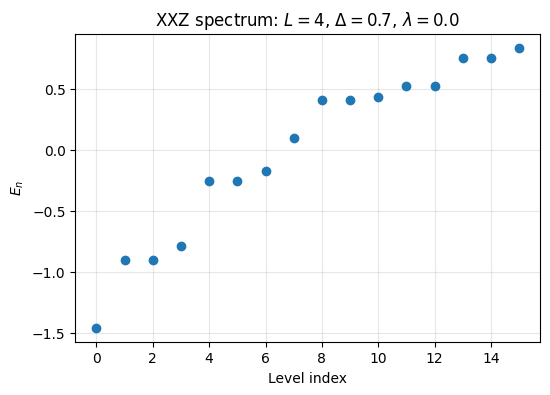

In [208]:
plt.figure(figsize=(6, 4))

plt.plot(
    np.arange(len(eigenvalues)),
    eigenvalues,
    "o"
)

plt.xlabel("Level index")
plt.ylabel(r"$E_n$")
plt.title(
    rf"XXZ spectrum: $L={L}$, "
    rf"$\Delta={Delta}$, $\lambda={lam}$"
)

plt.grid(alpha=0.3)
plt.show()

### Initial Spectral Observation

The plot above displays the ordered many-body energy eigenvalues of the $L=4$ XXZ chain.

At this stage, the spectrum should be interpreted only as a validation and visualization of the diagonalization procedure.

In particular, the presence or absence of quantum chaos cannot be inferred simply from the appearance of the energy levels.

Spectral signatures of quantum chaos require statistical quantities such as nearest-neighbour level spacings or adjacent-gap ratios, computed after all relevant symmetries have been resolved.

The raw spectrum therefore provides useful qualitative information, but it is not by itself a reliable diagnostic of integrability or quantum chaos.

## 1.9 Introducing an Integrability-Breaking Perturbation

The parameter $\lambda$ controls the strength of the next-nearest-neighbour interaction.

At

$$
\lambda=0,
$$

the system reduces to the nearest-neighbour XXZ chain, which is integrable.

We now compare this limit with a perturbed Hamiltonian at

$$
\lambda=0.5.
$$

The purpose of this preliminary calculation is to observe how the energy spectrum changes when the integrability-breaking interaction is introduced.

However, the raw spectrum alone is not a reliable diagnostic of quantum chaos.

In particular, the full spectrum contains several magnetization and spatial-symmetry sectors.

Levels belonging to different symmetry sectors are statistically independent and may cross without exhibiting level repulsion.

A meaningful comparison between the integrable and chaotic regimes will therefore require the sequence

$$
\text{symmetry resolution}
\rightarrow
\text{spectral statistics}
\rightarrow
\text{Poisson/GOE comparison}.
$$

The present calculation should consequently be regarded as an exploratory visualization rather than as direct evidence of quantum chaos.

In [209]:
H_integrable = build_xxz_hamiltonian(
    L=4,
    Delta=0.7,
    lam=0.0
)

H_perturbed = build_xxz_hamiltonian(
    L=4,
    Delta=0.7,
    lam=0.5
)

E_integrable = np.linalg.eigvalsh(H_integrable)
E_perturbed = np.linalg.eigvalsh(H_perturbed)

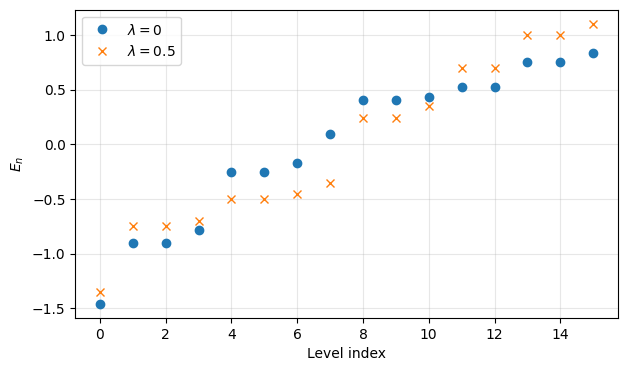

In [210]:
plt.figure(figsize=(7, 4))

plt.plot(
    E_integrable,
    "o",
    label=r"$\lambda=0$"
)

plt.plot(
    E_perturbed,
    "x",
    label=r"$\lambda=0.5$"
)

plt.xlabel("Level index")
plt.ylabel(r"$E_n$")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 1.10 Validation of the Full-Space Implementation

The first stage of the numerical implementation provides several consistency checks.

For

$$
L=4,
$$

the Hilbert-space dimension is

$$
D=2^4=16,
$$

in agreement with the expected dimension of a system containing four spin-$1/2$ degrees of freedom.

The constructed Hamiltonian satisfies

$$
H=H^\dagger
$$

within numerical precision, confirming that the implementation represents a valid Hermitian quantum Hamiltonian.

Furthermore, the numerical commutator satisfies

$$
\left\|
[H,S_{\mathrm{tot}}^z]
\right\|
\approx0,
$$

confirming conservation of the total magnetization.

The Hamiltonian can therefore be decomposed into independent sectors labelled by the eigenvalue of $S_{\mathrm{tot}}^z$.

This observation motivates the next stage of the numerical procedure.

Instead of working with the complete Hilbert space,

$$
\dim(\mathcal H)=2^L,
$$

we will exploit magnetization conservation to construct and diagonalize the Hamiltonian directly within a fixed-$N_\uparrow$ sector.

This reduction is required both for computational efficiency and for a physically meaningful analysis of spectral statistics.

# 2. Symmetry Reduction and Binary Representation

The full Hilbert space of an $L$-site spin-$1/2$ chain has dimension

$$
D=2^L,
$$

which grows exponentially with system size.

The purpose of this section is to reduce the computational complexity of the problem by exploiting the conservation of the total magnetization,

$$
[H,S_{\mathrm{tot}}^z]=0.
$$

This symmetry allows the full Hilbert space to be decomposed into independent sectors characterized by a fixed number of up spins $N_\uparrow$.

We will then introduce a binary representation of the computational basis and use it to construct the Hamiltonian directly within a fixed-magnetization sector.

The numerical strategy developed in this section can be summarized as

$$
\text{full Hilbert space}
\rightarrow
\text{symmetry sector}
\rightarrow
\text{binary basis}
\rightarrow
\text{direct reduced Hamiltonian}.
$$

The first implementation based on Kronecker products will be retained as an independent reference calculation. This will allow the reduced binary implementation to be validated by comparing both Hamiltonians and their spectra.

This transition represents the first major step from a pedagogical exact-diagonalization implementation toward a computationally efficient many-body calculation.

## 2.1 Reduction to a Fixed-Magnetization Sector

The Hilbert space of a chain of \(L\) spin-\(1/2\) particles is

$$
\mathcal{H}
=
\bigotimes_{i=1}^{L} \mathbb{C}^2,
$$

and therefore its total dimension is

$$
\dim(\mathcal{H}) = 2^L.
$$

Although this exponential growth is manageable for small system sizes, it rapidly becomes the main computational limitation of exact diagonalization methods. A substantial reduction of the Hilbert-space dimension can be achieved by exploiting the symmetries of the Hamiltonian.

For the XXZ Hamiltonian considered here, the total magnetization along the \(z\)-direction,

$$
S_{\mathrm{tot}}^z
=
\sum_{i=1}^{L} S_i^z,
$$

is a conserved quantity. In particular,

$$
[H,S_{\mathrm{tot}}^z]=0.
$$

Consequently, the Hamiltonian does not couple states with different eigenvalues of \(S_{\mathrm{tot}}^z\), and the full Hilbert space can be decomposed into independent magnetization sectors,

$$
\mathcal{H}
=
\bigoplus_M \mathcal{H}_M.
$$

For a spin-\(1/2\) chain, the magnetization of a computational basis state can be expressed in terms of the number of up and down spins. If \(N_\uparrow\) and \(N_\downarrow\) denote the corresponding occupation numbers, then

$$
N_\uparrow + N_\downarrow = L,
$$

and

$$
M
=
\frac{1}{2}
\left(
N_\uparrow-N_\downarrow
\right).
$$

Using \(N_\downarrow=L-N_\uparrow\), this becomes

$$
M=N_\uparrow-\frac{L}{2}.
$$

Therefore, fixing the total magnetization is equivalent to fixing the number of up spins.

The number of computational basis states belonging to a sector with fixed \(N_\uparrow\) is purely combinatorial,

$$
\dim\left(\mathcal{H}_{N_\uparrow}\right)
=
\binom{L}{N_\uparrow}.
$$

For example, for a chain of \(L=4\) spins and \(N_\uparrow=2\),

$$
\dim\left(\mathcal{H}_{N_\uparrow=2}\right)
=
\binom{4}{2}
=
6,
$$

whereas the dimension of the complete Hilbert space is

$$
2^4=16.
$$

More generally,

$$
2^L
=
\sum_{N_\uparrow=0}^{L}
\binom{L}{N_\uparrow},
$$

which explicitly shows that the complete Hilbert space is the direct sum of all fixed-magnetization sectors.

From a numerical point of view, this symmetry reduction is crucial. Instead of constructing and diagonalizing a \(2^L\times2^L\) Hamiltonian, one can construct the Hamiltonian directly inside a single symmetry sector of dimension

$$
D_{N_\uparrow}
=
\binom{L}{N_\uparrow}.
$$

This significantly reduces both memory requirements and computational cost.

Furthermore, resolving all relevant symmetries is essential for the subsequent study of spectral statistics. Energy levels belonging to different symmetry sectors are statistically independent and should not be mixed when investigating level repulsion or signatures of quantum chaos.

## 2.2 Binary Representation of the Computational Basis

A convenient way of representing many-body spin configurations computationally is to associate each spin state with a binary digit.

Throughout this work, we use the convention

$$
|\uparrow\rangle
\longleftrightarrow
0,
\qquad
|\downarrow\rangle
\longleftrightarrow
1.
$$

This convention is consistent with the single-spin basis

$$
|\uparrow\rangle
=
\begin{pmatrix}
1\\
0
\end{pmatrix},
\qquad
|\downarrow\rangle
=
\begin{pmatrix}
0\\
1
\end{pmatrix},
$$

and with the ordering of tensor-product basis states used in the explicit Kronecker-product implementation.

A many-body basis state can therefore be represented as a binary string. For example,

$$
|\uparrow\downarrow\uparrow\downarrow\rangle
\longleftrightarrow
0101_2.
$$

Since every binary string can also be interpreted as an integer,

$$
0101_2 = 5,
$$

the complete many-body state may be stored using a single integer.

For a system of \(L\) spins, the integers

$$
n=0,1,\ldots,2^L-1
$$

provide a one-to-one representation of all computational basis states.

This representation is particularly useful because information about individual spins can be extracted using elementary bit operations. Moreover, local spin operators can be implemented through bit manipulations rather than through explicit tensor products of large matrices.

With the convention adopted above, the number of set bits in the integer representation corresponds to the number of down spins,

$$
N_\downarrow
=
\operatorname{popcount}(n).
$$

Consequently,

$$
N_\uparrow
=
L-\operatorname{popcount}(n).
$$

A basis with fixed \(N_\uparrow\) can therefore be generated by selecting only the integers satisfying

$$
L-\operatorname{popcount}(n)
=
N_\uparrow.
$$

For example, for

$$
L=4,
\qquad
N_\uparrow=2,
$$

the allowed basis configurations are

$$
0011,
\quad
0101,
\quad
0110,
\quad
1001,
\quad
1010,
\quad
1100.
$$

In spin notation, these correspond to

$$
|\uparrow\uparrow\downarrow\downarrow\rangle,
$$

$$
|\uparrow\downarrow\uparrow\downarrow\rangle,
$$

$$
|\uparrow\downarrow\downarrow\uparrow\rangle,
$$

$$
|\downarrow\uparrow\uparrow\downarrow\rangle,
$$

$$
|\downarrow\uparrow\downarrow\uparrow\rangle,
$$

and

$$
|\downarrow\downarrow\uparrow\uparrow\rangle.
$$

The number of such states is

$$
6
=
\binom{4}{2},
$$

as expected from the combinatorial dimension of the corresponding magnetization sector.

The binary representation provides two major computational advantages. First, it allows the symmetry-reduced basis to be generated directly, without constructing the full \(2^L\)-dimensional Hilbert space. Second, the action of local spin operators can be translated into efficient bitwise operations.

In particular, the diagonal interaction

$$
S_i^zS_j^z
$$

can be evaluated by inspecting the values of the bits at sites \(i\) and \(j\), while the transverse contribution

$$
S_i^xS_j^x+S_i^yS_j^y
=
\frac{1}{2}
\left(
S_i^+S_j^-
+
S_i^-S_j^+
\right)
$$

acts by exchanging two oppositely oriented spins. In the binary representation, this operation can be implemented by flipping the corresponding two bits.

This representation will therefore allow us to construct the Hamiltonian directly inside a fixed-magnetization sector, without ever constructing the full \(2^L\times2^L\) matrix.

In [211]:
def fixed_magnetization_basis(L: int, N_up: int) -> np.ndarray:
    """
    Generate the computational basis with fixed number of up spins.

    Convention:
        0 -> spin up
        1 -> spin down
    """
    basis = []

    for state in range(2**L):
        N_down = state.bit_count()

        if L - N_down == N_up:
            basis.append(state)

    return np.array(basis, dtype=int)

## 2.3 Generation of the Symmetry-Reduced Basis

Since the XXZ Hamiltonian conserves the total magnetization, it is unnecessary to retain basis states belonging to different values of \(N_\uparrow\).

Using the binary representation introduced above, the number of down spins in a state \(n\) is

$$
N_\downarrow
=
\operatorname{popcount}(n).
$$

Therefore,

$$
N_\uparrow
=
L-\operatorname{popcount}(n).
$$

A basis state belongs to the desired magnetization sector if and only if

$$
L-\operatorname{popcount}(n)
=
N_\uparrow.
$$

The symmetry-reduced basis can therefore be constructed by iterating over the integers

$$
n=0,1,\ldots,2^L-1
$$

and retaining only those satisfying the fixed-\(N_\uparrow\) constraint.

The number of states obtained in this procedure must agree with the combinatorial prediction

$$
D
=
\binom{L}{N_\uparrow}.
$$

This equality provides our first direct numerical consistency check of the reduced-basis construction.

In [212]:
L = 4
N_up = 2

basis = fixed_magnetization_basis(L=L, N_up=N_up)
print(basis)

[ 3  5  6  9 10 12]


In [213]:
from math import comb

print(len(basis))
print(comb(L, N_up))

6
6


## 2.4 From Integer States to Spin Configurations

The integer representation is efficient for numerical calculations but is not particularly convenient for human inspection.

For debugging and physical interpretation, it is therefore useful to convert an integer state back into its binary and spin representations.

Using the convention

$$
0\equiv\uparrow,
\qquad
1\equiv\downarrow,
$$

a binary configuration such as

$$
0011
$$

corresponds to

$$
|\uparrow\uparrow\downarrow\downarrow\rangle.
$$

For the case

$$
L=4,
\qquad
N_\uparrow=2,
$$

the reduced basis contains the six configurations

$$
0011,
\quad
0101,
\quad
0110,
\quad
1001,
\quad
1010,
\quad
1100.
$$

The number of configurations is

$$
6=\binom{4}{2},
$$

as expected.

Although this human-readable representation is not required by the numerical algorithm itself, it is extremely useful for validating the basis and interpreting the action of local spin operators.

In [214]:
def state_to_string(state: int, L: int) -> str:
    bits = format(state, f"0{L}b")

    return "".join(
        "↑" if bit == "0" else "↓"
        for bit in bits
    )

In [215]:
for state in basis:
    print(
        state,
        format(state, f"0{L}b"),
        state_to_string(state, L)
    )

3 0011 ↑↑↓↓
5 0101 ↑↓↑↓
6 0110 ↑↓↓↑
9 1001 ↓↑↑↓
10 1010 ↓↑↓↑
12 1100 ↓↓↑↑


## 2.5 Hilbert-Space Decomposition

The conservation of total magnetization implies that the complete Hilbert space decomposes into independent subspaces labelled by \(N_\uparrow\),

$$
\mathcal{H}
=
\mathcal{H}_{N_\uparrow=0}
\oplus
\mathcal{H}_{N_\uparrow=1}
\oplus
\cdots
\oplus
\mathcal{H}_{N_\uparrow=L}.
$$

Each subspace has dimension

$$
\dim\left(\mathcal{H}_{N_\uparrow}\right)
=
\binom{L}{N_\uparrow}.
$$

For example, for \(L=4\),

$$
\dim(\mathcal H_0)=1,
$$

$$
\dim(\mathcal H_1)=4,
$$

$$
\dim(\mathcal H_2)=6,
$$

$$
\dim(\mathcal H_3)=4,
$$

and

$$
\dim(\mathcal H_4)=1.
$$

Therefore,

$$
16=1+4+6+4+1.
$$

More generally,

$$
2^L
=
\sum_{k=0}^{L}
\binom{L}{k},
$$

which follows directly from the binomial identity

$$
(1+1)^L
=
\sum_{k=0}^{L}
\binom{L}{k}.
$$

This identity has a direct physical interpretation: the complete many-body Hilbert space is exactly reconstructed by combining all fixed-magnetization sectors.

In [216]:
L = 4

total_dimension = 0

for N_up in range(L + 1):
    dimension = comb(L, N_up)
    total_dimension += dimension

    print(
        f"N_up = {N_up}: "
        f"dimension = {dimension}"
    )

print()
print("Sum of sector dimensions:", total_dimension)
print("Full Hilbert-space dimension:", 2**L)

assert total_dimension == 2**L

N_up = 0: dimension = 1
N_up = 1: dimension = 4
N_up = 2: dimension = 6
N_up = 3: dimension = 4
N_up = 4: dimension = 1

Sum of sector dimensions: 16
Full Hilbert-space dimension: 16


## 2.6 Projection of the Full Hamiltonian onto a Magnetization Sector

The Hamiltonian constructed previously using explicit Kronecker products acts on the complete \(2^L\)-dimensional Hilbert space.

Because

$$
[H,S_{\mathrm{tot}}^z]=0,
$$

the Hamiltonian does not couple states belonging to different magnetization sectors.

If the basis were explicitly reordered according to $N_{\uparrow}$, the Hamiltonian would take a block-diagonal form,

$$
H
=
H_0
\oplus
H_1
\oplus
\cdots
\oplus
H_L.
$$

Each block $H_{N_\uparrow}$ acts exclusively inside a fixed-magnetization subspace.

With the binary convention used in this notebook, the integer representation of a state corresponds to its position in the full computational basis generated by the Kronecker-product construction.

Therefore, if the array `basis` contains the integer states belonging to a particular symmetry sector, the corresponding Hamiltonian block can be obtained by selecting the associated rows and columns.

For

$$
L=4,
\qquad
N_\uparrow=2,
$$

this reduces the original matrix from

$$
16\times16
$$

to

$$
6\times6.
$$

At this stage, the reduced Hamiltonian is obtained by projection from the full matrix. This is useful for validating the symmetry reduction, although it will not be our final computational strategy.

In [217]:
L = 4
N_up = 2
Delta = 0.7
lam = 0.0
J = 1.0

basis = fixed_magnetization_basis(L,N_up)
H = build_xxz_hamiltonian(L=L, J=J, Delta=Delta, lam=lam)

H_sector = H[np.ix_(basis,basis)]

print("Full hamiltonian shape: ", H.shape)
print("Reduced hamiltonian shape: ", H_sector.shape)

Full hamiltonian shape:  (16, 16)
Reduced hamiltonian shape:  (6, 6)


## 2.7 Consistency Checks of the Reduced Hamiltonian

Before interpreting any numerical results, the projected Hamiltonian must satisfy several consistency conditions.

First, since the full Hamiltonian is Hermitian,

$$
H=H^\dagger,
$$

every diagonal block must also be Hermitian:

$$
H_{\mathrm{sector}}
=
H_{\mathrm{sector}}^\dagger.
$$

Numerically, this condition should hold within floating-point precision.

Second, the dimension of the reduced Hamiltonian must agree with the dimension of the selected symmetry sector,

$$
\dim(H_{\mathrm{sector}})
=
\binom{L}{N_\uparrow}.
$$

Third, the Hamiltonian contains a large number of zero matrix elements. This is a consequence of locality: a local spin interaction only connects a given basis state with a relatively small number of other configurations.

Thus, even after symmetry reduction,

$$
N_{\mathrm{nz}}
\ll D^2,
$$

where $N_{\mathrm{nz}}$ is the number of non-zero matrix elements and

$$
D=\binom{L}{N_\uparrow}.
$$

This observation anticipates an important numerical improvement that will be introduced later: sparse-matrix representations.

In [218]:
np.set_printoptions(
    precision=3,
    suppress=True
)

print("Reduced hamiltonian: ")
print(H_sector)

is_hermitian = np.allclose(H_sector, H_sector.conj().T)

print("Hermitian: ", is_hermitian)
print("Matrix Norm: ", np.linalg.norm(H_sector))

tol = 1e-12

nnz = np.count_nonzero(np.abs(H_sector) > tol)

density2 = nnz / np.size(H_sector)

print("Non-zero elements:", nnz)
print("Total elements:", H_sector.size)
print(f"Matrix density: {density2:.4f}")

Reduced hamiltonian: 
[[ 0.175+0.j  0.5  +0.j  0.   +0.j  0.   +0.j  0.   +0.j  0.   +0.j]
 [ 0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j  0.   +0.j  0.   +0.j]
 [ 0.   +0.j  0.5  +0.j -0.175+0.j  0.   +0.j  0.5  +0.j  0.   +0.j]
 [ 0.   +0.j  0.5  +0.j  0.   +0.j -0.175+0.j  0.5  +0.j  0.   +0.j]
 [ 0.   +0.j  0.   +0.j  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j]
 [ 0.   +0.j  0.   +0.j  0.   +0.j  0.   +0.j  0.5  +0.j  0.175+0.j]]
Hermitian:  True
Matrix Norm:  1.9167028982082746
Non-zero elements: 18
Total elements: 36
Matrix density: 0.5000


## 2.8 Exact Diagonalization within a Symmetry Sector

Once the Hamiltonian has been restricted to a fixed-magnetization sector, we solve the eigenvalue problem

$$
H_{\mathrm{sector}}
|\psi_n\rangle
=
E_n|\psi_n\rangle.
$$

The important difference with respect to the previous full-space calculation is that the eigenvectors now belong to the reduced Hilbert space

$$
|\psi_n\rangle
\in
\mathbb{C}^{D},
$$

where

$$
D
=
\binom{L}{N_\uparrow},
$$

instead of

$$
\mathbb{C}^{2^L}.
$$

For

$$
L=4,
\qquad
N_\uparrow=2,
$$

the eigenvectors have dimension

$$
D=6
$$

instead of

$$
2^4=16.
$$

The resulting eigenvalues correspond exclusively to the chosen magnetization sector.

This distinction is essential for the later analysis of spectral statistics, since level correlations must be studied only after resolving the relevant symmetries of the Hamiltonian.

In [219]:
E_sector, V_sector = eigh(H_sector)

print("Eigenvalues:")
print(E_sector)

print()
print("Eigenvector matrix shape:", V_sector.shape)
print("Dimension of one eigenvector: ", V_sector[0].shape)

print()
print(
    "Expected reduced dimension:",
    comb(L, N_up)
)

ground_state = V_sector[: , 0]
print("Ground state vector: ", V_sector[:, 0])
print("Ground state normalization: ", np.vdot(ground_state, ground_state))

Eigenvalues:
[-1.458 -0.785 -0.175  0.094  0.435  0.838]

Eigenvector matrix shape: (6, 6)
Dimension of one eigenvector:  (6,)

Expected reduced dimension: 6
Ground state vector:  [-0.166-0.j  0.542-0.j -0.423+0.j -0.423+0.j  0.542+0.j -0.166+0.j]
Ground state normalization:  (1+0j)


## 2.9 Relation between the Reduced and Full Spectrum

Since the full Hamiltonian decomposes into independent symmetry blocks,

$$
H
=
H_0
\oplus
H_1
\oplus
\cdots
\oplus
H_L,
$$

its complete spectrum is the union of the spectrum of all magnetization sectors:

$$
\operatorname{Spec}(H)
=
\bigcup_{N_\uparrow=0}^{L}
\operatorname{Spec}(H_{N_\uparrow}).
$$

Consequently,

$$
\operatorname{Spec}(H_{N_\uparrow})
\subset
\operatorname{Spec}(H).
$$

The eigenvalues obtained from the reduced Hamiltonian must therefore also appear among the eigenvalues of the full Hamiltonian.

Different symmetry sectors may contain equal or nearly equal eigenvalues. These levels are allowed to cross because states belonging to different symmetry sectors do not hybridize.

This observation is particularly important in quantum-chaos studies. If spectra from several independent sectors are mixed, the resulting sequence contains crossings that are not suppressed by level repulsion. Such mixing can therefore make a chaotic Hamiltonian appear artificially closer to Poisson statistics.

In [220]:
E_full = np.linalg.eigvalsh(H)

print("Full spectrum: ", E_full)
print("Spectrum in the selected space N_up: ", E_sector)

Full spectrum:  [-1.458 -0.906 -0.906 -0.785 -0.256 -0.256 -0.175  0.094  0.406  0.406
  0.435  0.525  0.525  0.756  0.756  0.838]
Spectrum in the selected space N_up:  [-1.458 -0.785 -0.175  0.094  0.435  0.838]


In [221]:
distances = []

for energy in E_sector:
    minimum_distances = np.min(np.abs(E_full - energy))
    distances.append(minimum_distances)

print("Largest mismatch: ", max(distances))

Largest mismatch:  3.3306690738754696e-15


## 2.10 Visualizing the Structure of the Hamiltonian

The structure of the Hamiltonian can be visualized by plotting the absolute values of its matrix elements,

$$
|H_{ij}|.
$$

This representation provides useful information about both the symmetries and the locality of the model.

The XXZ Hamiltonian contains only local two-spin interactions. As a consequence, a given computational basis state is connected only to configurations that differ locally.

Therefore, the Hamiltonian is sparse: most matrix elements vanish,

$$
H_{ij}=0
$$

for the majority of pairs $(i,j)$.

The same property remains true after restricting the Hamiltonian to a fixed-magnetization sector.

In the original integer ordering of the computational basis, states belonging to the same magnetization sector are not necessarily stored consecutively. Therefore, the block structure associated with $S_{\mathrm{tot}}^z$ may not be visually obvious in the full Hamiltonian.

If the basis were reordered according to magnetization, the block-diagonal decomposition would become explicit.

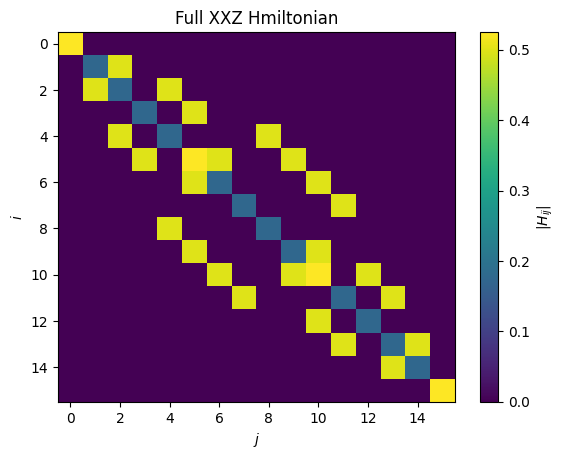

In [222]:
plt.Figure(figsize=(6,5))

plt.imshow(
    np.abs(H),
    aspect="auto",
    interpolation="None"
)

plt.colorbar(
    label= r"$|H_{ij}|$"
)

plt.xlabel(r"$j$")
plt.ylabel(r"$i$")
plt.title("Full XXZ Hmiltonian")

plt.show()


Text(0.5, 1.0, 'Reduced Hamiltonian: $L=4$, $N_up = 2$')

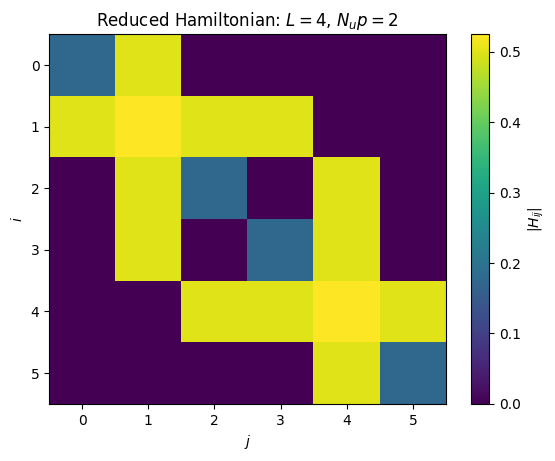

In [223]:
plt.Figure(figsize=(6,5))

plt.imshow(
    np.abs(H_sector),
    aspect="auto",
    interpolation="None"
)

plt.colorbar(
    label=r"$|H_{ij}|$"
)


plt.xlabel(r"$j$")
plt.ylabel(r"$i$")
plt.title(rf"Reduced Hamiltonian: "
          rf"$L={L}$, $N_up = {N_up}$")


## 2.11 Why Constructing the Full Hamiltonian First Is Inefficient

The procedure used so far can be summarized as

$$
H_{\mathrm{full}}
\longrightarrow
H_{N_\uparrow}.
$$

That is, the complete Hamiltonian is first constructed in a Hilbert space of dimension

$$
2^L,
$$

and only afterwards is the desired symmetry block extracted.

Although this procedure is extremely useful for validating our implementation, it does not provide the computational advantage we ultimately seek.

Constructing the full Hamiltonian still requires dealing with a matrix of dimension

$$
2^L\times2^L,
$$

even if only a much smaller block is needed afterwards.

The correct strategy for larger systems is therefore

$$
\boxed{
\text{construct the reduced basis first}
}
$$

followed by

$$
\boxed{
\text{construct }H_{N_\uparrow}\text{ directly inside that basis}.
}
$$

In other words,

$$
\text{Reduced basis}
\longrightarrow
H_{N_\uparrow},
$$

without ever creating $H_{\mathrm{full}}$.

It is important to note that symmetry reduction does not eliminate the exponential complexity of the many-body problem.

Near half filling,

$$
N_\uparrow\approx\frac{L}{2},
$$

the largest sector has dimension

$$
D_{\mathrm{max}}
=
\binom{L}{L/2}.
$$

For large \(L\),

$$
\binom{L}{L/2}
\sim
\frac{2^L}{\sqrt{\pi L/2}}.
$$

Thus, the reduced Hilbert space still grows exponentially with system size, although considerably more slowly than the complete space.

In [224]:
L = 4
N_up = 2

basis = fixed_magnetization_basis(L,N_up)

state_to_index = {
    int(state): index
    for index, state in enumerate(basis)
} 

for state, index in state_to_index.items():
    print(
        f"{state_to_string(state,L):6s}"
        f"{format(state, f'0{L}b')}"
        f"-> matrix index {index}"
    )

↑↑↓↓  0011-> matrix index 0
↑↓↑↓  0101-> matrix index 1
↑↓↓↑  0110-> matrix index 2
↓↑↑↓  1001-> matrix index 3
↓↑↓↑  1010-> matrix index 4
↓↓↑↑  1100-> matrix index 5


## 2.12 Direct Construction of the XXZ Hamiltonian in the Reduced Basis

We now construct the XXZ Hamiltonian directly inside a fixed-magnetization sector, without generating the full $2^L$-dimensional Hilbert space.

The nearest-neighbour XXZ Hamiltonian is

$$
H_{\mathrm{NN}}
=
J
\sum_{i=1}^{L-1}
\left(
S_i^xS_{i+1}^x
+
S_i^yS_{i+1}^y
+
\Delta S_i^zS_{i+1}^z
\right).
$$

The next-nearest-neighbour perturbation is

$$
H_{\mathrm{NNN}}
=
J
\sum_{i=1}^{L-2}
\left(
S_i^xS_{i+2}^x
+
S_i^yS_{i+2}^y
+
\Delta S_i^zS_{i+2}^z
\right),
$$

such that

$$
H(\lambda)
=
H_{\mathrm{NN}}
+
\lambda H_{\mathrm{NNN}}.
$$

The transverse part can be rewritten using ladder operators,

$$
S^\pm
=
S^x\pm iS^y.
$$

This gives

$$
S_i^xS_j^x
+
S_i^yS_j^y
=
\frac{1}{2}
\left(
S_i^+S_j^-
+
S_i^-S_j^+
\right).
$$

This representation naturally separates the Hamiltonian into diagonal and off-diagonal contributions.

### Diagonal contribution

The term

$$
\Delta S_i^zS_j^z
$$

is diagonal in the computational basis.

For a single spin,

$$
S^z|\uparrow\rangle
=
+\frac{1}{2}
|\uparrow\rangle,
$$

whereas

$$
S^z|\downarrow\rangle
=
-\frac{1}{2}
|\downarrow\rangle.
$$

Therefore, if the two spins have the same orientation,

$$
S_i^zS_j^z
=
+\frac{1}{4},
$$

while for opposite orientations,

$$
S_i^zS_j^z
=
-\frac{1}{4}.
$$

The diagonal matrix element generated by a bond $(i,j)$ is consequently

$$
+\frac{J\Delta}{4}
$$

for parallel spins and

$$
-\frac{J\Delta}{4}
$$

for antiparallel spins.

For next-nearest-neighbour bonds, the entire contribution is additionally multiplied by $\lambda$.

### Off-diagonal contribution

The transverse part is

$$
\frac{J}{2}
\left(
S_i^+S_j^-
+
S_i^-S_j^+
\right).
$$

These operators act only when the two spins are oppositely oriented.

In particular,

$$
|\uparrow_i\downarrow_j\rangle
\longrightarrow
|\downarrow_i\uparrow_j\rangle,
$$

and

$$
|\downarrow_i\uparrow_j\rangle
\longrightarrow
|\uparrow_i\downarrow_j\rangle.
$$

The corresponding matrix element is

$$
\frac{J}{2}.
$$

If both spins are parallel, the transverse contribution vanishes.

Thus, the off-diagonal interaction simply exchanges two opposite spins while preserving the total magnetization.

This makes the conservation law

$$
[H,S_{\mathrm{tot}}^z]=0
$$

explicit at the level of the numerical algorithm.

### Bit representation of the interaction

In the binary representation, exchanging

$$
|\uparrow_i\downarrow_j\rangle
\leftrightarrow
|\downarrow_i\uparrow_j\rangle
$$

corresponds to flipping both bits $i$ and $j$.

The operation can be implemented efficiently using the bitwise XOR operator.

If $p_i$ and $p_j$ denote the binary positions associated with lattice sites $i$ and $j$, we construct the mask

$$
m
=
2^{p_i}+2^{p_j}.
$$

The new state is then

$$
n'
=
n\oplus m,
$$

where $\oplus$ denotes XOR.

Because our tensor-product convention assigns `site = 0` to the leftmost spin, while standard binary operations label the rightmost bit as position zero, the relation between a lattice site $i$ and its binary position is

$$
p_i=L-1-i.
$$

This convention must be used consistently throughout the implementation.

### Direct reduced-space construction

The numerical procedure for each basis state $|n\rangle$ is therefore:

1. Inspect the two spins associated with each interacting bond.

2. Add the diagonal contribution from

$$
\Delta S_i^zS_j^z.
$$

3. If the two spins are opposite, flip both bits to obtain the connected state

$$
|n'\rangle.
$$

4. Use the state-to-index mapping to locate $|n'\rangle$ inside the reduced basis.

5. Insert the off-diagonal matrix element

$$
\frac{J}{2}.
$$

Since the exchange of two opposite spins preserves $N_\uparrow$, the new state always remains inside the same magnetization sector.

The reduced Hamiltonian therefore has dimension

$$
D
=
\binom{L}{N_\uparrow}
$$

from the beginning of the calculation.

No $2^L\times2^L$ Hamiltonian is ever constructed.

### Validation

A crucial test is to compare this direct implementation with the symmetry block obtained previously from the full Kronecker-product Hamiltonian.

The two independent constructions should satisfy

$$
H_{\mathrm{direct}}
=
H_{\mathrm{projected}}
$$

within numerical precision.

Equivalently,

$$
\left\|
H_{\mathrm{direct}}
-
H_{\mathrm{projected}}
\right\|
\approx0.
$$

Their spectra must also agree,

$$
E_n^{\mathrm{direct}}
=
E_n^{\mathrm{projected}}.
$$

This constitutes a particularly strong validation test because the same physical Hamiltonian has been constructed using two fundamentally different numerical approaches:

$$
\text{Kronecker products + symmetry projection}
$$

and

$$
\text{binary basis + direct construction}.
$$

Agreement between both methods provides strong evidence that the reduced-basis implementation is correct.

In [225]:
def bit_position(site: int, L: int) -> int:
    "Convert a lattice-site index into his binary bit position. site = 0 is the leftmost spin position"
    return L - 1 - site

def get_bit(state: int, site: int, L: int) -> int:
    "return the binary value associented with the lattice site"
    position = bit_position(site,L)

    return(
        state >> position
    ) & 1

In [226]:
state = 5
L = 4

for site in range(L):
    print(
        f"site {site}: bit = "
        f"{get_bit(state, site, L)}"
    )

site 0: bit = 0
site 1: bit = 1
site 2: bit = 0
site 3: bit = 1


In [227]:
def flip_two_spins(
    state: int,
    site_i: int,
    site_j: int,
    L: int
) -> int:
    """
    Flip the bits corresponding to two lattice sites.
    """
    p_i = bit_position(
        site_i,
        L
    )

    p_j = bit_position(
        site_j,
        L
    )

    mask = (
        (1 << p_i)
        |
        (1 << p_j)
    )

    return int(state) ^ mask

In [228]:
state = 5  # 0101

new_state = flip_two_spins(
    state,
    site_i=0,
    site_j=1,
    L=4
)

print(
    "Initial:",
    format(state, "04b")
)

print(
    "Final:  ",
    format(new_state, "04b")
)

Initial: 0101
Final:   1001


In [229]:
def build_xxz_reduced(
        L: int,
        N_up: int,
        Delta: float = 1.0,
        lam: float = 0.0,
        J: float = 1.0
) -> tuple[np.ndarray, np.ndarray]:
    """
    Construct the XXZ Hamiltonian directly inside a fixed-N_up sector.

    The model contains nearest-neighbour and next-nearest-neighbour
    interactions with open boundary conditions.

    Returns
    -------
    basis:
        Integer representation of the reduced basis.

    H_reduced:
        Dense Hamiltonian matrix in the reduced basis.
    """

    basis = fixed_magnetization_basis(L,N_up)

    dimension = len(basis)

    state_to_index = {
        int(state): int(index)
        for index, state in enumerate(basis)
    }

    H_reduced = np.zeros((dimension,dimension), dtype=complex)

    def add_bond(
            site_i: int,
            site_j: int,
            coupling: float
    ) -> None:
        for column, state_raw in enumerate(basis):

            state = int(state_raw)
            bit_i = get_bit(state,site_i,L)
            bit_j = get_bit(state,site_j,L)

            if bit_i == bit_j:
                sz_product = 0.25
            else:
                sz_product = -0.25

            H_reduced[
                column,
                column
            ] += (
                coupling*Delta*sz_product
            )  

            if bit_i != bit_j:

                new_state = flip_two_spins(state, site_i, site_j, L)
                row = state_to_index[new_state]

                H_reduced[
                    row,
                    column
                    ] += (
                        coupling*0.5
                    )
    # =====================================
    # Nearest-neighbour interactions
    # =====================================

    for i in range(L - 1):
        add_bond(
            i,
            i + 1,
            J
        )

    # =====================================
    # Next-nearest-neighbour interactions
    # =====================================

    for i in range(L - 2):
        add_bond(
            i,
            i + 2,
            lam * J
        )
    return basis, H_reduced


In [230]:
L = 4
N_up = 2
J = 1.0
Delta = 0.7
lam = 0.0

basis_direct, H_direct = build_xxz_reduced(
    L=L,
    N_up=N_up,
    Delta=Delta,
    lam=lam,
    J = J
)

print(
    "Reduced dimension:",
    len(basis_direct)
)

print()
print("Direct Hamiltonian:")
print(H_direct)

Reduced dimension: 6

Direct Hamiltonian:
[[ 0.175+0.j  0.5  +0.j  0.   +0.j  0.   +0.j  0.   +0.j  0.   +0.j]
 [ 0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j  0.   +0.j  0.   +0.j]
 [ 0.   +0.j  0.5  +0.j -0.175+0.j  0.   +0.j  0.5  +0.j  0.   +0.j]
 [ 0.   +0.j  0.5  +0.j  0.   +0.j -0.175+0.j  0.5  +0.j  0.   +0.j]
 [ 0.   +0.j  0.   +0.j  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j]
 [ 0.   +0.j  0.   +0.j  0.   +0.j  0.   +0.j  0.5  +0.j  0.175+0.j]]


In [231]:
print("Same basis ordering: ",
    np.array_equal(
        basis, basis_direct
    )
)

Same basis ordering:  True


In [232]:
print(
    "Hamiltonians equal ",
    np.allclose(
        H_direct, H_sector
    )
)

print(
    "difference ||H_direct - H_sector|| = ",
    np.linalg.norm(H_direct - H_sector)
)

Hamiltonians equal  True
difference ||H_direct - H_sector|| =  0.0


In [233]:
E_direct = np.linalg.eigvalsh(H_direct)
E_sector = np.linalg.eigvalsh(H_sector)

print(
    "Proyected spectrum: ",
    E_sector
)

print(
    "Direct spectrum: ",
    E_direct
)

print(
    "Spectrum equal: ",
    np.allclose(E_sector,E_direct)
)

Proyected spectrum:  [-1.458 -0.785 -0.175  0.094  0.435  0.838]
Direct spectrum:  [-1.458 -0.785 -0.175  0.094  0.435  0.838]
Spectrum equal:  True


## 2.13 Summary of the Symmetry-Reduction Procedure

In this section, the representation of the many-body problem has been transformed from the complete Hilbert space,

$$
\dim(\mathcal H)=2^L,
$$

to a symmetry-resolved sector with fixed total magnetization,

$$
\dim(\mathcal H_{N_\uparrow})
=
\binom{L}{N_\uparrow}.
$$

The computational representation has also changed from explicit tensor products to a binary encoding of spin configurations,

$$
\text{Kronecker-product basis}
\longrightarrow
\text{integer/binary basis}.
$$

The initial procedure,

$$
H_{\mathrm{full}}
\longrightarrow
H_{N_\uparrow},
$$

was usefull for validating the symmetry reduction but still required constructing the full exponentially large Hamiltonian.

The direct binary implementation instead follows

$$
\text{reduced basis}
\longrightarrow
H_{N_\uparrow},
$$

and therefore avoids constructing the complete $2^L\times2^L$ matrix.

A particularly important consistency test was obtained by constructing the same reduced Hamiltonian using two independent procedures:

$$
H_{\mathrm{projected}}
$$

from the full Kronecker-product representation and

$$
H_{\mathrm{direct}}
$$

from the binary basis.

Numerically, both constructions satisfy

$$
\left\|
H_{\mathrm{direct}}
-
H_{\mathrm{projected}}
\right\|
\approx0,
$$

and their spectrum agree within floating-point precision.

This provides an independent validation of the binary implementation.

Nevertheless, the dimension

$$
D=\binom{L}{N_\uparrow}
$$

still grows exponentially with system size. Symmetry reduction considerably delays the computational barrier but does not eliminate it.

A second important observation is that the reduced Hamiltonian remains highly sparse,

$$
N_{\mathrm{nz}}\ll D^2.
$$

The next numerical improvement will therefore consist of replacing dense matrices by sparse representations,

$$
\text{dense}
\longrightarrow
\text{COO}
\longrightarrow
\text{CSR},
$$

followed eventually by iterative eigensolvers based on Krylov subspaces and Lanczos-type methods.

Before performing spectral-statistics calculations, the remaining relevant symmetries of the Hamiltonian, particularly spatial reflection parity, must also be resolved. This will ensure that level-spacing statistics are computed within a single irreducible symmetry sector.

# 3. Sparse Hamiltonian Representation

The symmetry reduction introduced in the previous section reduces the Hilbert-space dimension from

$$
2^L
$$

to

$$
D=\binom{L}{N_\uparrow}.
$$

However, the dimension of the reduced Hilbert space still grows exponentially with system size. In particular, near half filling,

$$
N_\uparrow \approx \frac{L}{2},
$$

the dimension behaves asymptotically as

$$
\binom{L}{L/2}
\sim
\frac{2^L}{\sqrt{\pi L/2}}.
$$

Therefore, symmetry reduction alone does not remove the exponential complexity of the many-body problem.

A second important property of the XXZ Hamiltonian can nevertheless be exploited: the Hamiltonian is highly sparse.

Because the model contains only local two-spin interactions, each computational basis state is connected to only a relatively small number of other configurations. Most matrix elements therefore vanish.

The objective of this section is to replace the dense representation of the reduced Hamiltonian by a sparse representation,

$$
H_{\mathrm{dense}}
\longrightarrow
H_{\mathrm{sparse}},
$$

while preserving exactly the same physical Hamiltonian.

The numerical strategy will be

$$
\text{binary reduced basis}
\rightarrow
\text{COO construction}
\rightarrow
\text{CSR representation}
\rightarrow
\text{iterative linear algebra}.
$$

This change will considerably reduce memory requirements and will prepare the implementation for larger system sizes and Krylov-based eigensolvers.

In [234]:
from scipy import sparse
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.linalg import eigsh

from time import perf_counter

## 3.1 Why the Many-Body Hamiltonian Is Sparse

Consider a Hamiltonian represented in a Hilbert space of dimension $D$.

A dense matrix representation stores all

$$
D^2
$$

matrix elements, independently of whether they are zero or non-zero.

For a sparse matrix, it is useful to define

$$
N_{\mathrm{nz}}
$$

as the number of non-zero matrix elements.

The matrix density is then

$$
\rho_H
=
\frac{N_{\mathrm{nz}}}{D^2}.
$$

A dense matrix has, in general,

$$
\rho_H\sim O(1),
$$

whereas a sparse matrix satisfies

$$
\rho_H\ll1.
$$

The XXZ Hamiltonian is sparse because it contains only local two-spin interactions.

For a bond $(i,j)$, the longitudinal term

$$
\Delta S_i^zS_j^z
$$

is diagonal in the computational basis and therefore contributes only to

$$
H_{nn}.
$$

The transverse interaction,

$$
S_i^xS_j^x+S_i^yS_j^y
=
\frac{1}{2}
\left(
S_i^+S_j^-
+
S_i^-S_j^+
\right),
$$

connects a basis state only to another state obtained by exchanging two oppositely oriented spins.

Therefore, a given basis state is not connected to all other $D-1$ configurations. Instead, the number of possible transitions is controlled by the number of interacting bonds, which grows only linearly with the system size,

$$
N_{\mathrm{bonds}}\sim O(L).
$$

Consequently, for a local Hamiltonian one expects approximately

$$
N_{\mathrm{nz}}
\sim O(LD),
$$

rather than

$$
N_{\mathrm{nz}}
\sim O(D^2).
$$

This scaling is only a structural estimate: the exact number of non-zero matrix elements depends on the magnetization sector, the interaction range, the boundary conditions, and the values of the model parameters.

Nevertheless, since

$$
D=\binom{L}{N_\uparrow},
$$

the ratio

$$
\rho_H
=
\frac{N_{\mathrm{nz}}}{D^2}
$$

typically decreases as the system size grows.

It is important to distinguish two different statements:

1. the Hamiltonian becomes proportionally more sparse as $D$ increases;

2. the Hilbert-space dimension still grows exponentially.

Sparse representations therefore reduce the memory and computational cost associated with matrix storage and matrix-vector products, but they do not eliminate the fundamental exponential complexity of the many-body problem.

In [235]:
D = H_direct.shape[0]
tol = 1e-14

nnz_dense = np.count_nonzero(
    np.abs(H_direct) > tol
)

density = nnz_dense/D**2
sparsity = 1.0 - density

print(f"Hilbert-space dimension D: {D}")
print(f"Total matrix elements D^2: {D**2}")
print(f"Non-zero matrix elements: {nnz_dense}")
print(f"Matrix density: {density:.6f}")
print(f"Matrix sparsity: {sparsity:.6f}")

Hilbert-space dimension D: 6
Total matrix elements D^2: 36
Non-zero matrix elements: 18
Matrix density: 0.500000
Matrix sparsity: 0.500000


### Numerical Observation

For the small $L=4$ system, the reduced Hilbert-space dimension for $N_{\uparrow}$ is

$$
D=6.
$$

The Hamiltonian already contains a significant number of zero matrix elements, reflecting the local structure of the XXZ interactions.

However, at such a small system size the matrix should not yet be expected to appear extremely sparse.

The physically relevant observation is the scaling with system size. As $L$ increases, the Hilbert-space dimension grows rapidly while each basis state remains connected only to a number of configurations controlled by the number of local bonds.

Consequently, the fraction

$$
\rho_H
=
\frac{N_{\mathrm{nz}}}{D^2}
$$

is expected to decrease with increasing $L$.

This behaviour will be tested explicitly later in this section.

## 3.2 Memory Cost of Dense Exact Diagonalization

The main limitation of a dense Hamiltonian representation is its quadratic memory scaling with the Hilbert-space dimension.

For a matrix of dimension

$$
D\times D,
$$

the total number of stored elements is

$$
D^2.
$$

In the present implementation, the Hamiltonian is stored using the NumPy data type `complex128`.

A complex number represented as `complex128` requires

$$
16\ \mathrm{bytes}.
$$

Therefore, the approximate memory required by a dense Hamiltonian is

$$
M_{\mathrm{dense}}
=
16D^2
$$

bytes.

In the largest magnetization sector of an even spin chain,

$$
N_\uparrow=\frac{L}{2},
$$

the Hilbert-space dimension is

$$
D(L)
=
\binom{L}{L/2}.
$$

Consequently,

$$
M_{\mathrm{dense}}(L)
=
16
\binom{L}{L/2}^2.
$$

This quadratic dependence on $D$ is much more restrictive than the memory required to store a single quantum state,

$$
|\psi\rangle\in\mathbb{C}^D,
$$

which scales only as

$$
M_{\psi}=16D.
$$

Thus, the dense Hamiltonian generally becomes computationally prohibitive long before storing a state vector becomes impossible.

The following calculation estimates the dense-memory requirements without actually constructing the corresponding matrices.

In [236]:
def format_memory(nbytes: int) -> str:
    "Convert a number of bytes into a readable memory value"
    kb = 1024
    mb = kb**2
    gb = kb**3
    tb = kb**4

    if nbytes < mb:
        return f"{nbytes/kb:.3f} KiB"
    if nbytes < gb:
        return f"{nbytes/mb:.3f} MiB"
    if nbytes < tb:
        return f"{nbytes/gb:.3f} GiB"
    return f"{nbytes/tb:.3f} TiB"

In [237]:
system_sizes = [
    4, 8, 10, 12, 14, 16, 18, 20
]

print(
    f"{'L':>4}"
    f"{'2^L':>12}"
    f"{'D sector':>14}"
    f"{'Dense memory':>18}"
)

for L_test in system_sizes:

    D_full = 2**L_test

    D_sector = comb(
        L_test,
        L_test // 2
    )

    dense_memory_bytes = (
        16 * D_sector**2
    )

    print(
        f"{L_test:4d}"
        f"{D_full:12d}"
        f"{D_sector:14d}"
        f"{format_memory(dense_memory_bytes):>18}"
    )

   L         2^L      D sector      Dense memory
   4          16             6         0.562 KiB
   8         256            70        76.562 KiB
  10        1024           252       992.250 KiB
  12        4096           924        13.028 MiB
  14       16384          3432       179.728 MiB
  16       65536         12870         2.468 GiB
  18      262144         48620        35.225 GiB
  20     1048576        184756       508.648 GiB


In [238]:
print(
    f"{'L':>4}"
    f"{'D':>14}"
    f"{'State vector':>18}"
    f"{'Dense H':>18}"
)

for L_test in system_sizes:

    D = comb(
        L_test,
        L_test // 2
    )

    vector_memory = 16 * D
    matrix_memory = 16 * D**2

    print(
        f"{L_test:4d}"
        f"{D:14d}"
        f"{format_memory(vector_memory):>18}"
        f"{format_memory(matrix_memory):>18}"
    )

   L             D      State vector           Dense H
   4             6         0.094 KiB         0.562 KiB
   8            70         1.094 KiB        76.562 KiB
  10           252         3.938 KiB       992.250 KiB
  12           924        14.438 KiB        13.028 MiB
  14          3432        53.625 KiB       179.728 MiB
  16         12870       201.094 KiB         2.468 GiB
  18         48620       759.688 KiB        35.225 GiB
  20        184756         2.819 MiB       508.648 GiB


### Dense-Memory Scaling

The estimated memory requirements show that symmetry reduction alone is not sufficient to make dense exact diagonalization scalable.

Although the fixed-magnetization sector is significantly smaller than the full $2^L$ Hilbert space, the dense Hamiltonian still requires storage proportional to

$$
D^2.
$$

By contrast, a single state vector requires only

$$
O(D)
$$

memory.

This distinction is fundamental for modern exact-diagonalization methods. For sufficiently large systems, storing vectors remains feasible even when storing the complete Hamiltonian as a dense matrix has already become impossible.

This motivates a representation in which only the non-zero matrix elements of $H$ are stored.

## 3.3 Coordinate Sparse Format (COO)

A sparse matrix representation avoids storing matrix elements that are exactly zero.

One of the simplest sparse formats is the coordinate format, abbreviated as COO.

Instead of storing a complete $D\times D$ array, the matrix is represented by three one-dimensional arrays,

$$
\text{row},
\qquad
\text{column},
\qquad
\text{data}.
$$

For each stored element $k$,

$$
H_{\mathrm{row}_k,\mathrm{column}_k}
=
\mathrm{data}_k.
$$

For example, a matrix

$$
H=
\begin{pmatrix}
1 & 0 & 2\\
0 & 0 & 0\\
3 & 0 & 4
\end{pmatrix}
$$

can be represented by storing only the four non-zero entries,

$$
\text{data}
=
(1,2,3,4),
$$

together with their row and column indices.

The COO format is particularly convenient during matrix construction because new matrix elements can simply be appended to lists of rows, columns, and values.

Another useful property of COO is that duplicate coordinates are allowed.

For example, if several physical interaction terms contribute to the same matrix element,

$$
H_{ij}
=
h_{ij}^{(1)}
+
h_{ij}^{(2)},
$$

both contributions may initially be stored independently.

They can later be combined using

```python
H_coo.sum_duplicates()

In [239]:
H_coo_from_dense = coo_matrix(
    H_direct
)
print("Real matrix form of the hamiltonian: ")
print(H_direct)
print("Matrix type: ", type(H_coo_from_dense.shape))

print("Shape: ", H_coo_from_dense)

print("Number of stored elements: ", H_coo_from_dense.nnz)

Real matrix form of the hamiltonian: 
[[ 0.175+0.j  0.5  +0.j  0.   +0.j  0.   +0.j  0.   +0.j  0.   +0.j]
 [ 0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j  0.   +0.j  0.   +0.j]
 [ 0.   +0.j  0.5  +0.j -0.175+0.j  0.   +0.j  0.5  +0.j  0.   +0.j]
 [ 0.   +0.j  0.5  +0.j  0.   +0.j -0.175+0.j  0.5  +0.j  0.   +0.j]
 [ 0.   +0.j  0.   +0.j  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j]
 [ 0.   +0.j  0.   +0.j  0.   +0.j  0.   +0.j  0.5  +0.j  0.175+0.j]]
Matrix type:  <class 'tuple'>
Shape:  <COOrdinate sparse matrix of dtype 'complex128'
	with 18 stored elements and shape (6, 6)>
  Coords	Values
  (0, 0)	(0.175+0j)
  (0, 1)	(0.5+0j)
  (1, 0)	(0.5+0j)
  (1, 1)	(-0.5249999999999999+0j)
  (1, 2)	(0.5+0j)
  (1, 3)	(0.5+0j)
  (2, 1)	(0.5+0j)
  (2, 2)	(-0.175+0j)
  (2, 4)	(0.5+0j)
  (3, 1)	(0.5+0j)
  (3, 3)	(-0.175+0j)
  (3, 4)	(0.5+0j)
  (4, 2)	(0.5+0j)
  (4, 3)	(0.5+0j)
  (4, 4)	(-0.5249999999999999+0j)
  (4, 5)	(0.5+0j)
  (5, 4)	(0.5+0j)
  (5, 5)	(0.175+0j)
Number of stored elements:  18


In [240]:
print("Data: ", H_coo_from_dense.data)

print("Rows: ", H_coo_from_dense.row)

print("Colums: ", H_coo_from_dense.col)

Data:  [ 0.175+0.j  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j
  0.5  +0.j -0.175+0.j  0.5  +0.j  0.5  +0.j -0.175+0.j  0.5  +0.j
  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j  0.175+0.j]
Rows:  [0 0 1 1 1 1 2 2 2 3 3 3 4 4 4 4 5 5]
Colums:  [0 1 0 1 2 3 1 2 4 1 3 4 2 3 4 5 4 5]


In [241]:
print(
    "  row   col        value"
)

for row, col, value in zip(
    H_coo_from_dense.row,
    H_coo_from_dense.col,
    H_coo_from_dense.data
):
    print(
        f"{row:4d}",
        f"{col:6d}",
        f"{value:15.6f}"
    )

  row   col        value
   0      0 0.175000+0.000000j
   0      1 0.500000+0.000000j
   1      0 0.500000+0.000000j
   1      1 -0.525000+0.000000j
   1      2 0.500000+0.000000j
   1      3 0.500000+0.000000j
   2      1 0.500000+0.000000j
   2      2 -0.175000+0.000000j
   2      4 0.500000+0.000000j
   3      1 0.500000+0.000000j
   3      3 -0.175000+0.000000j
   3      4 0.500000+0.000000j
   4      2 0.500000+0.000000j
   4      3 0.500000+0.000000j
   4      4 -0.525000+0.000000j
   4      5 0.500000+0.000000j
   5      4 0.500000+0.000000j
   5      5 0.175000+0.000000j


In [242]:
H_recontructed = (
    H_coo_from_dense.toarray()
)

print("COO -> dense recontruction correct: ",
     np.allclose(
         H_recontructed, H_direct
     )
)

print(
    "Difference norm: ",
    np.linalg.norm(
        H_recontructed - H_direct
    )
)

COO -> dense recontruction correct:  True
Difference norm:  0.0


### Interpretation of the COO Representation

The COO representation contains the same Hamiltonian as the dense matrix, but stores only its non-zero matrix elements.

For the small test system, the equality

$$
H_{\mathrm{COO}}
=
H_{\mathrm{dense}}
$$

is verified by reconstructing the dense matrix and checking

$$
\left\|
H_{\mathrm{COO}}
-
H_{\mathrm{dense}}
\right\|
\approx0.
$$

This confirms that changing the matrix representation does not modify the physical operator.

However, the current procedure

$$
H_{\mathrm{dense}}
\rightarrow
H_{\mathrm{COO}}
$$

does not solve the original memory problem because the dense Hamiltonian must still be constructed first.

The next step is therefore crucial:

$$
\boxed{
\text{binary reduced basis}
\rightarrow
H_{\mathrm{COO}}
}
$$

directly.

Instead of allocating a $D\times D$ dense array, the Hamiltonian contributions will be accumulated directly into lists of row indices, column indices, and matrix elements.

This will constitute the first genuinely sparse construction of the XXZ Hamiltonian.

## 3.4 Direct Construction of the Sparse Hamiltonian

The conversion

$$
H_{\mathrm{dense}}
\rightarrow
H_{\mathrm{COO}}
$$

introduced in the previous section is useful for understanding sparse matrix formats, but it does not solve the fundamental memory problem because the dense Hamiltonian must still be constructed first.

The objective is now to construct the sparse Hamiltonian directly from the physical action of the XXZ model,

$$
\text{reduced basis}
\rightarrow
H_{\mathrm{COO}},
$$

without allocating a dense $D\times D$ matrix at any stage.

The physical rules are exactly the same as in the dense reduced-basis implementation.

For a bond $(i,j)$, the XXZ interaction is

$$
H_{ij}
=
J_{ij}
\left[
S_i^xS_j^x
+
S_i^yS_j^y
+
\Delta S_i^zS_j^z
\right].
$$

Using ladder operators,

$$
S_i^xS_j^x
+
S_i^yS_j^y
=
\frac{1}{2}
\left(
S_i^+S_j^-
+
S_i^-S_j^+
\right).
$$

The Hamiltonian therefore produces two types of matrix elements.

### Diagonal contribution

The longitudinal term

$$
\Delta S_i^zS_j^z
$$

does not change the spin configuration.

For parallel spins,

$$
S_i^zS_j^z
=
+\frac{1}{4},
$$

whereas for antiparallel spins,

$$
S_i^zS_j^z
=
-\frac{1}{4}.
$$

Thus, for a basis state $|n\rangle$, each interacting bond contributes to the diagonal element

$$
H_{nn}.
$$

### Off-diagonal contribution

The transverse interaction acts only on antiparallel spins,

$$
|\uparrow_i\downarrow_j\rangle
\leftrightarrow
|\downarrow_i\uparrow_j\rangle.
$$

The corresponding matrix element is

$$
\frac{J_{ij}}{2}.
$$

In the binary representation, the new state is generated by flipping the two corresponding bits.

### Sparse construction

In the dense implementation, a matrix contribution was inserted as

```python
H[row, column] += value

In [243]:
def bit_position(
    site: int,
    L: int
) -> int:
    """
    Convert a lattice-site index into its binary-bit position.

    Convention:
        site = 0 is the leftmost spin.
    """

    if not 0 <= site < L:
        raise ValueError(
            f"Invalid site={site} for L={L}. "
            f"Expected 0 <= site < {L}."
        )

    return L - 1 - site
def get_bit(
    state: int,
    site: int,
    L: int
) -> int:
    """
    Return the bit associated with a lattice site.

    Convention:
        0 -> spin up
        1 -> spin down

    Parameters
    ----------
    state:
        Integer representation of the many-body state.

    site:
        Lattice site, with site=0 corresponding to
        the leftmost spin.

    L:
        Number of lattice sites.
    """

    position = bit_position(
        site,
        L
    )

    return (
        int(state) >> position
    ) & 1

def build_xxz_sparse(
    L: int,
    N_up: int,
    Delta: float = 1.0,
    lam: float = 0.0,
    J: float = 1.0
) -> tuple[np.ndarray, coo_matrix]:
    """
    Construct the XXZ Hamiltonian directly as a sparse COO matrix
    inside a fixed-N_up magnetization sector.

    Convention
    ----------
    0 -> spin up
    1 -> spin down

    Open boundary conditions are used.

    Parameters
    ----------
    L:
        Number of lattice sites.

    N_up:
        Number of up spins.

    Delta:
        XXZ anisotropy parameter.

    lam:
        Relative strength of next-nearest-neighbour interactions.

    J:
        Nearest-neighbour coupling.

    Returns
    -------
    basis:
        Integer representation of the fixed-magnetization basis.

    H_coo:
        Sparse Hamiltonian in COO format.
    """

    # -------------------------------------------------
    # 1. Construct the symmetry-reduced basis
    # -------------------------------------------------

    basis = fixed_magnetization_basis(
        L,
        N_up
    )

    D = len(basis)

    # -------------------------------------------------
    # 2. Map physical states to matrix indices
    # -------------------------------------------------

    state_to_index = {
        int(state): int(index)
        for index, state in enumerate(basis)
    }

    # -------------------------------------------------
    # 3. COO storage arrays
    # -------------------------------------------------

    rows = []
    cols = []
    data = []

    # -------------------------------------------------
    # 4. Contribution from a single interacting bond
    # -------------------------------------------------

    def add_bond(
        site_i: int,
        site_j: int,
        coupling: float
    ) -> None:

        # If the coupling is exactly zero,
        # this bond does not contribute.
        if coupling == 0.0:
            return

        for column, state_raw in enumerate(basis):

            state = int(state_raw)

            bit_i = get_bit(
                state,
                site_i,
                L
            )

            bit_j = get_bit(
                state,
                site_j,
                L
            )

            # ==========================================
            # Diagonal Delta Sz_i Sz_j contribution
            # ==========================================

            if bit_i == bit_j:
                sz_product = 0.25
            else:
                sz_product = -0.25

            diagonal_value = (
                coupling
                * Delta
                * sz_product
            )

            rows.append(column)
            cols.append(column)
            data.append(diagonal_value)

            # ==========================================
            # Off-diagonal XY exchange contribution
            # ==========================================

            if bit_i != bit_j:

                new_state = flip_two_spins(
                    state,
                    site_i,
                    site_j,
                    L
                )

                row = state_to_index[
                    int(new_state)
                ]

                off_diagonal_value = (
                    0.5
                    * coupling
                )

                rows.append(row)
                cols.append(column)
                data.append(off_diagonal_value)

    # -------------------------------------------------
    # 5. Nearest-neighbour bonds
    # -------------------------------------------------

    for i in range(L - 1):

        add_bond(
            i,
            i + 1,
            J
        )

    # -------------------------------------------------
    # 6. Next-nearest-neighbour bonds
    # -------------------------------------------------

    for i in range(L - 2):

        add_bond(
            i,
            i + 2,
            lam * J
        )

    # -------------------------------------------------
    # 7. Construct COO matrix
    # -------------------------------------------------

    H_coo = coo_matrix(
        (
            np.asarray(data, dtype=np.complex128),
            (
                np.asarray(rows, dtype=int),
                np.asarray(cols, dtype=int)
            )
        ),
        shape=(D, D),
        dtype=np.complex128
    )

    # -------------------------------------------------
    # 8. Combine repeated matrix coordinates
    # -------------------------------------------------

    H_coo.sum_duplicates()

    # Remove possible explicit zeros after summation
    H_coo.eliminate_zeros()

    return basis, H_coo

In [244]:
L = 4
N_up = 2

J = 1.0
Delta = 0.7
lam = 0.0

basis_sparse, H_sparse = build_xxz_sparse(
    L=L,
    N_up=N_up,
    J=J,
    Delta=Delta,
    lam=lam
)

print("Basis:")
print(basis_sparse)

print()

print("Matrix type:")
print(type(H_sparse))

print()

print("Shape:")
print(H_sparse.shape)

print()

print("Number of non-zero elements:")
print(H_sparse.nnz)

Basis:
[ 3  5  6  9 10 12]

Matrix type:
<class 'scipy.sparse._coo.coo_matrix'>

Shape:
(6, 6)

Number of non-zero elements:
18


In [245]:
print(
    "COO data: "),
print(
    H_sparse.data
)
print(
    "COO rows"
)
print(H_sparse.row)
print(
    "COO column"
)
print(H_sparse.col)

COO data: 
[ 0.175+0.j  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j
  0.5  +0.j -0.175+0.j  0.5  +0.j  0.5  +0.j -0.175+0.j  0.5  +0.j
  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j  0.175+0.j]
COO rows
[0 0 1 1 1 1 2 2 2 3 3 3 4 4 4 4 5 5]
COO column
[0 1 0 1 2 3 1 2 4 1 3 4 2 3 4 5 4 5]


### Duplicated in COO

During the contruction of the reduced hamiltonian, we can have contributions like
$$
(i,i,a) \quad (i,i,b) \quad (i,i,c)
$$

But after the sum_duplicted(), we get 
$$
(i,i, a + b + c)
$$

This exactly replicates the 
$$
H_{reduced}[i,i]+= value
$$

So, we have the relation
$$
append + duplicated \rightarrow H_{i,j} += h_{i,j} 
$$

### Direct Sparse Construction

The Hamiltonian has now been constructed directly in COO format from the physical action of the XXZ interactions.

The numerical procedure is therefore no longer

$$
\text{reduced basis}
\rightarrow
D\times D\text{ dense matrix}
\rightarrow
\text{sparse matrix},
$$

but instead

$$
\boxed{
\text{reduced basis}
\rightarrow
\text{non-zero matrix elements}
\rightarrow
H_{\mathrm{COO}}.
}
$$

Only matrix elements generated by the Hamiltonian are explicitly stored.

The diagonal $S_i^zS_j^z$ terms contribute to coordinates of the form

$$
(n,n),
$$

whereas the transverse exchange terms generate off-diagonal transitions

$$
(n,m)
$$

between computational-basis states differing by the exchange of two antiparallel spins.

Multiple physical contributions to the same matrix coordinate are initially allowed by the COO representation and are subsequently combined through

```python
H_sparse.sum_duplicates()

## 3.5 Validation against the Dense Implementation

The sparse Hamiltonian has been constructed independently from the previously validated dense implementation.

Before using the sparse representation for larger systems, it is necessary to verify that both numerical constructions represent exactly the same physical operator.

For sufficiently small systems, the sparse matrix can temporarily be converted into a dense array and compared directly with the previously constructed Hamiltonian.

The first consistency condition is

$$
H_{\mathrm{sparse}}
=
H_{\mathrm{dense}}.
$$

Numerically, we test

$$
\left\|
H_{\mathrm{sparse}}
-
H_{\mathrm{dense}}
\right\|
\approx 0.
$$

A second fundamental requirement is Hermiticity,

$$
H=H^\dagger.
$$

Instead of relying only on a dense conversion, the sparse representation can be tested directly by constructing

$$
\Delta_H
=
H-H^\dagger.
$$

For a correctly implemented Hamiltonian,

$$
\Delta_H=0
$$

up to floating-point precision.

Finally, both representations must produce the same energy spectrum,

$$
E_n^{\mathrm{sparse}}
=
E_n^{\mathrm{dense}}.
$$

Agreement between the two implementations provides a strong validation because the same Hamiltonian has been constructed using two different numerical data structures.

In [246]:
H_sparse_dense = H_sparse.toarray()

print(
    "Same hamiltonian: ",
    np.allclose(H_sparse_dense,H_direct)
)

difference_dense = (
    H_sparse_dense - H_direct
)

print(
    "||H_sparse - H_dense|| = ",
    np.linalg.norm(difference_dense)
)


Same hamiltonian:  True
||H_sparse - H_dense|| =  0.0


In [247]:
hermitian_difference = (
    H_sparse
    -
    H_sparse.getH()
)

hermitian_difference.sum_duplicates()
hermitian_difference.eliminate_zeros()

if hermitian_difference.nnz == 0:
    hermitian_error = 0.0
else:
    hermitian_error = np.max(
        np.abs(
            hermitian_difference.data
        )
    )

print(
    "Sparse Hermiticity error:",
    hermitian_error
)

Sparse Hermiticity error: 0.0


In [248]:
E_dense = np.linalg.eigvalsh(
    H_direct
)

E_sparse_full = np.linalg.eigvalsh(
    H_sparse.toarray()
)

print(
    "Same spectrum:",
    np.allclose(
        E_dense,
        E_sparse_full
    )
)

print(
    "Maximum spectral difference:",
    np.max(
        np.abs(
            E_dense
            -
            E_sparse_full
        )
    )
)

Same spectrum: True
Maximum spectral difference: 0.0


### Validation Results

The dense and sparse constructions represent the same Hamiltonian within numerical precision,

$$
\left\|
H_{\mathrm{sparse}}
-
H_{\mathrm{dense}}
\right\|
\approx 0.
$$

The sparse Hamiltonian also satisfies

$$
H_{\mathrm{sparse}}
=
H_{\mathrm{sparse}}^\dagger,
$$

confirming that Hermiticity is preserved by the direct COO construction.

Finally, both representations produce the same energy eigenvalues.

This agreement is particularly important because the two Hamiltonians were constructed using independent numerical strategies:

$$
\text{dense array accumulation}
$$

and

$$
\text{sparse COO coordinate accumulation}.
$$

The sparse representation can therefore be used as the primary Hamiltonian representation in the following calculations.

## 3.6 Compressed Sparse Row Format (CSR)

The COO format is convenient for constructing a sparse matrix because matrix elements can be generated as independent coordinate-value triplets.

However, COO is not generally the most efficient representation for repeated linear-algebra operations.

For subsequent calculations, the Hamiltonian will therefore be converted to the Compressed Sparse Row format, or CSR.

A CSR matrix is represented internally by three arrays:

- `data`, containing the stored non-zero matrix elements;
- `indices`, containing the column index associated with each stored element;
- `indptr`, indicating where each matrix row begins inside the `data` and `indices` arrays.

Conceptually, CSR stores the matrix row by row.

This representation is particularly efficient for matrix-vector products,

$$
|\phi\rangle
=
H|\psi\rangle,
$$

which constitute the fundamental operation behind many iterative numerical algorithms.

The workflow adopted here is therefore

$$
\text{physical interactions}
\rightarrow
\text{COO construction}
\rightarrow
\text{CSR representation}.
$$

COO will be used primarily during Hamiltonian construction, while CSR will be used for repeated numerical operations and iterative eigensolvers.

In [249]:
H_csr = H_sparse.tocsr()

H_csr.sum_duplicates()
H_csr.eliminate_zeros()

print("Matrix type: ")
print(type(H_csr))

print("Shape: ")
print(H_csr.shape)

print("Stored non-zero elements: ")
print(H_csr.nnz)

Matrix type: 
<class 'scipy.sparse._csr.csr_matrix'>
Shape: 
(6, 6)
Stored non-zero elements: 
18


In [250]:
print("CSR data:")
print(H_csr.data)

print()

print("CSR column indices:")
print(H_csr.indices)

print()

print("CSR row pointer:")
print(H_csr.indptr)

CSR data:
[ 0.175+0.j  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j
  0.5  +0.j -0.175+0.j  0.5  +0.j  0.5  +0.j -0.175+0.j  0.5  +0.j
  0.5  +0.j  0.5  +0.j -0.525+0.j  0.5  +0.j  0.5  +0.j  0.175+0.j]

CSR column indices:
[0 1 0 1 2 3 1 2 4 1 3 4 2 3 4 5 4 5]

CSR row pointer:
[ 0  2  6  9 12 16 18]


### COO and CSR Roles

The COO and CSR matrices represent exactly the same physical Hamiltonian but are optimized for different stages of the calculation.

The COO representation is particularly convenient during construction because individual physical contributions can be appended without requiring a predetermined row structure.

The CSR representation reorganizes the same non-zero elements row by row and is therefore more appropriate for repeated operations such as

$$
H|\psi\rangle.
$$

From this point onward, the CSR representation will be used as the default format for numerical linear algebra.

## 3.7 Dense versus Sparse Memory Requirements

The principal advantage of sparse storage is the reduction of memory requirements.

For a dense `complex128` matrix of dimension $D$, the approximate memory requirement is

$$
M_{\mathrm{dense}}
=
16D^2
$$

bytes.

A CSR matrix does not store zero matrix elements.

Its memory consumption is determined primarily by three arrays:

$$
M_{\mathrm{CSR}}
=
M_{\mathrm{data}}
+
M_{\mathrm{indices}}
+
M_{\mathrm{indptr}}.
$$

The actual memory used by a SciPy CSR matrix can therefore be measured directly from its internal arrays.

For a local many-body Hamiltonian, the number of stored elements scales approximately as

$$
N_{\mathrm{nz}}
\sim O(LD),
$$

so sparse storage can become dramatically more efficient than dense storage as the Hilbert-space dimension increases.

This does not remove the exponential scaling of $D$, but it substantially extends the range of system sizes accessible to exact diagonalization.

In [251]:
def sparse_memory_bytes(
        matrix: csr_matrix
) -> int:
    "Actual memory occupied by the main CSR arrays"

    return(
        matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes
    )

def bytes_to_mb(
        nbytes: int
) -> float:
    return nbytes/1024**2

In [252]:
dense_memory = H_direct.nbytes

csr_memory = sparse_memory_bytes(
    H_csr
)

print(
    f"Dense memory: "
    f"{bytes_to_mb(dense_memory):.6f} MiB"
)

print(
    f"CSR memory:   "
    f"{bytes_to_mb(csr_memory):.6f} MiB"
)

print(
    f"Memory ratio dense/CSR: "
    f"{dense_memory / csr_memory:.3f}"
)

Dense memory: 0.000549 MiB
CSR memory:   0.000370 MiB
Memory ratio dense/CSR: 1.485


In [253]:
memory_sizes = [
    4, 6, 8, 10, 12
]

memory_results = []

for L_test in memory_sizes:

    N_up_test = L_test // 2

    _, H_test_coo = build_xxz_sparse(
        L=L_test,
        N_up=N_up_test,
        J=1.0,
        Delta=0.7,
        lam=0.0
    )

    H_test_csr = H_test_coo.tocsr()

    D_test = H_test_csr.shape[0]
    nnz_test = H_test_csr.nnz

    estimated_dense = (
        16 * D_test**2
    )

    actual_sparse = sparse_memory_bytes(
        H_test_csr
    )

    memory_results.append(
        (
            L_test,
            D_test,
            nnz_test,
            estimated_dense,
            actual_sparse
        )
    )

print(
    f"{'L':>4}"
    f"{'D':>10}"
    f"{'nnz':>12}"
    f"{'Dense MiB':>15}"
    f"{'CSR MiB':>15}"
)

for result in memory_results:

    L_test, D_test, nnz_test, dense_b, sparse_b = result

    print(
        f"{L_test:4d}"
        f"{D_test:10d}"
        f"{nnz_test:12d}"
        f"{bytes_to_mb(dense_b):15.6f}"
        f"{bytes_to_mb(sparse_b):15.6f}"
    )

   L         D         nnz      Dense MiB        CSR MiB
   4         6          18       0.000549       0.000370
   6        20          80       0.006104       0.001606
   8        70         350       0.074768       0.006947
  10       252        1512       0.968994       0.029804
  12       924        6468      13.027588       0.126896


## 3.8 Scaling of Matrix Sparsity

The sparsity of the Hamiltonian can be quantified through the density

$$
\rho_H
=
\frac{N_{\mathrm{nz}}}{D^2}.
$$

For a local spin Hamiltonian, each basis state is connected only to a number of configurations controlled by the number of interacting bonds.

As the Hilbert-space dimension $D$ grows exponentially while the number of local transitions per state grows only approximately linearly with $L$, one expects

$$
\rho_H
\rightarrow 0
$$

with increasing system size.

This does not imply that the number of non-zero matrix elements decreases.

In fact,

$$
N_{\mathrm{nz}}
$$

continues to increase rapidly.

The important point is that it grows much more slowly than the total number of possible matrix elements,

$$
D^2.
$$

In [254]:
sparsity_sizes = [
    4, 6, 8, 10, 12, 14
]

L_values = []
D_values = []
nnz_values = []
density_values = []

for L_test in sparsity_sizes:

    N_up_test = L_test // 2

    _, H_test = build_xxz_sparse(
        L=L_test,
        N_up=N_up_test,
        J=1.0,
        Delta=0.7,
        lam=0.0
    )

    D_test = H_test.shape[0]
    nnz_test = H_test.nnz

    density_test = (
        nnz_test
        /
        D_test**2
    )

    L_values.append(
        L_test
    )

    D_values.append(
        D_test
    )

    nnz_values.append(
        nnz_test
    )

    density_values.append(
        density_test
    )

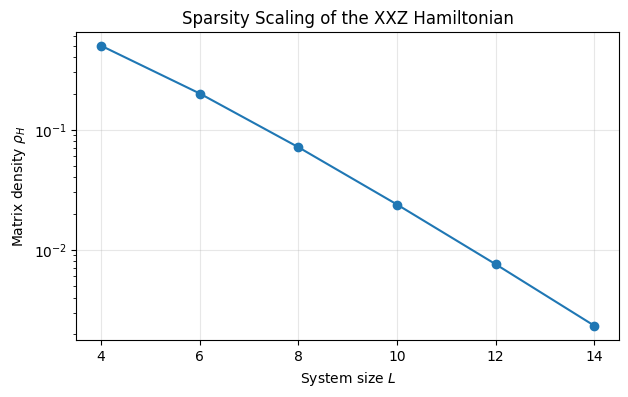

In [255]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    L_values,
    density_values,
    "o-"
)

plt.yscale("log")

plt.xlabel(
    r"System size $L$"
)

plt.ylabel(
    r"Matrix density $\rho_H$"
)

plt.title(
    "Sparsity Scaling of the XXZ Hamiltonian"
)

plt.grid(
    alpha=0.3
)

plt.show()

### Sparsity Scaling

The matrix density decreases as the system size increases,

$$
\rho_H(L)
=
\frac{N_{\mathrm{nz}}(L)}{D(L)^2}.
$$

This confirms that the XXZ Hamiltonian becomes proportionally more sparse for larger Hilbert spaces.

However, the absolute number of stored elements still increases with $L$.

Therefore, sparse storage considerably improves the numerical representation of the Hamiltonian but does not eliminate the exponential growth of the many-body Hilbert space.

## 3.9 Sparse Matrix-Vector Products

Many iterative numerical methods do not require direct access to every matrix element of the Hamiltonian.

Instead, their fundamental operation is the matrix-vector product

$$
|\phi\rangle
=
H|\psi\rangle.
$$

For a generic dense matrix, the computational cost of this operation scales approximately as

$$
O(D^2).
$$

For a sparse matrix containing $N_{\mathrm{nz}}$ stored elements, the corresponding cost is approximately

$$
O(N_{\mathrm{nz}}).
$$

Since a local many-body Hamiltonian satisfies approximately

$$
N_{\mathrm{nz}}\ll D^2,
$$

sparse matrix-vector products become increasingly advantageous as the system size grows.

These operations form the basis of Krylov-subspace methods, including Lanczos diagonalization and sparse time evolution.

In [256]:
L_test = 10
N_up_test = L_test // 2

basis_dense_test, H_dense_test = build_xxz_reduced(
    L=L_test,
    N_up=N_up_test,
    Delta=0.7,
    lam=0.0,
    J = 1.0
)

basis_sparse_test, H_sparse_test = build_xxz_sparse(
    L=L_test,
    N_up=N_up_test,
    Delta=0.7,
    lam=0.0,
    J = 1.0
)

H_csr_test = H_sparse_test.tocsr()

print(
    "Dimension:",
    H_csr_test.shape[0]
)

Dimension: 252


In [257]:
rng = np.random.default_rng(
    12345
)

D_test = H_dense_test.shape[0]

psi = (
    rng.normal(size=D_test) + 1j*rng.normal(size=D_test)
)

psi /= np.linalg.norm(psi)

In [258]:
phi_dense = (
    H_dense_test @ psi
)

phi_sparse = (
    H_sparse_test @ psi
)


print("Same matrix vector product: ",
    np.allclose(phi_dense,phi_sparse))

print("difference norm: ",
      np.linalg.norm(H_dense_test - H_sparse_test)
)


Same matrix vector product:  True
difference norm:  1.0877919644084146e-15


In [259]:
n_repetitions = 100

start = perf_counter()

for _ in range(n_repetitions):
    H_dense_test @ psi
dense_time = (
    perf_counter() - start
)

start = perf_counter()

for _ in range(n_repetitions):
    H_sparse_test @ psi

sparse_time = (
    perf_counter()
    -
    start
)

print(
    f"Dense total time: "
    f"{dense_time:.6f} s"
)

print(
    f"Sparse total time: "
    f"{sparse_time:.6f} s"
)

print(
    f"Dense per multiplication: "
    f"{dense_time / n_repetitions:.6e} s"
)

print(
    f"Sparse per multiplication: "
    f"{sparse_time / n_repetitions:.6e} s"
)

Dense total time: 0.009215 s
Sparse total time: 0.000685 s
Dense per multiplication: 9.214600e-05 s
Sparse per multiplication: 6.845000e-06 s


### Matrix-Vector Product Validation

The dense and sparse Hamiltonians produce the same action on the test state,

$$
H_{\mathrm{dense}}|\psi\rangle
=
H_{\mathrm{sparse}}|\psi\rangle
$$

within numerical precision.

Timing measurements for small systems should be interpreted cautiously because fixed computational overhead may dominate the calculation.

The important asymptotic distinction is

$$
O(D^2)
$$

for dense matrix-vector multiplication compared with approximately

$$
O(N_{\mathrm{nz}})
$$

for sparse multiplication.

The advantage of the sparse representation is therefore expected to become increasingly important as $D$ grows.

## 3.10 Dense and Iterative Eigensolvers

Dense exact diagonalization and sparse iterative diagonalization solve related but computationally different problems.

A dense Hermitian eigensolver such as

scipy.linalg.eigh

typically computes the complete eigendescomposition,
$$
H \phi = E_n |\phi_n \rangle
$$

inclusing all eigenvalues and eigenvectors.

This is appropiate when the Hilbert space dimension is sufficiently small and the complete spectrum is required. Sparse interative methods instead target only a limited number of eigenvalues.

scipy.sparse.linalg.eigsh

This method is based on Krylov-subspace techniques closely related to the Lanczos algorithm. Starting with a vector $|v \rangle$, a Krylov subspace is constructed as 
$$
\mathcal{K}_m (H,|v\rangle) = span \{|v\rangle , H |v\rangle, H^2 |v\rangle, .... , H^{m-1}|v\rangle \}.
$$

Instied of diagonalizing the complete $D \times D$ matrix directly, the Hamiltonian is proyected onto a much smaller subspace.

The crucial numerical operation is repeatedly applying 
$$
H | \psi \rangle 
$$

which is precisely where the sparse CSR representation has more impact.

In [260]:
k = 6

E_iterative = eigsh(
    H_csr_test,
    k=k,
    which="SA",
    return_eigenvectors=False
)

E_iterative = np.sort(
    E_iterative
)

E_dense_all = np.linalg.eigvalsh(
    H_dense_test
)

E_dense_low = (
    E_dense_all[:k]
)

print(
    "Dense lowest eigenvalues:"
)

print(
    E_dense_low
)

print()

print(
    "Sparse iterative eigenvalues:"
)

print(
    E_iterative
)

print()

print(
    "Same eigenvalues:",
    np.allclose(
        E_dense_low,
        E_iterative
    )
)

Dense lowest eigenvalues:
[-3.847 -3.507 -3.15  -3.075 -2.833 -2.818]

Sparse iterative eigenvalues:
[-3.847 -3.507 -3.15  -3.075 -2.833 -2.818]

Same eigenvalues: True


### Dense versus Iterative Diagonalization

The iterative sparse eigensolver reproduces the lowest eigenvalues obtained from complete dense diagonalization.

The conceptual difference is important.

Dense diagonalization computes essentially the entire spectrum, whereas the iterative method obtains only the requested part of the spectrum using repeated sparse matrix-vector products.

For observables dominated by low-energy physics, this can provide a dramatic computational advantage.

However, quantum-chaos studies introduce an additional complication because spectral statistics generally require many consecutive energy levels rather than only a few extremal eigenvalues.

## 3.11 Why Sparse Diagonalization Does Not Automatically Solve the Spectral-Statistics Problem

Sparse storage and sparse iterative diagonalization substantially reduce the numerical cost of many quantum many-body calculations.

However, they do not automatically solve the problem relevant to quantum-chaos spectroscopy.

For ground-state calculations, obtaining only a few extremal eigenvalues may be sufficient.

For example, an iterative eigensolver can efficiently target the lowest-energy states,

$$
E_0,E_1,\ldots,E_k.
$$

Quantum-chaos observables are fundamentally different.

Quantities such as

$$
P(s),
$$

the adjacent-gap ratio

$$
r_n
=
\frac{
\min(s_n,s_{n+1})
}{
\max(s_n,s_{n+1})
},
$$

and longer-range spectral correlations require many consecutive eigenvalues belonging to the same symmetry sector.

Furthermore, universal random-matrix behaviour is usually studied in the bulk of the many-body spectrum rather than only at its edges.

Thus,

$$
\text{sparse Hamiltonian}
\neq
\text{cheap complete spectrum}.
$$

Interior eigenvalues can be targeted using shift-invert techniques.

Conceptually, rather than working directly with $H$, one considers

$$
(H-\sigma I)^{-1}.
$$

Eigenvalues of $H$ close to the target energy $\sigma$ are transformed into large-magnitude eigenvalues of the inverse operator and can therefore be targeted efficiently by iterative methods.

In SciPy, this can be accessed through a call of the form

```python
eigsh(
    H,
    k=k,
    sigma=sigma,
    which="LM"
)

In [261]:
sigma = 0.1

E_middle = eigsh(
    H_csr_test,
    k=6,
    sigma=sigma,
    which="LM",
    return_eigenvectors=False
)

E_middle = np.sort(
    E_middle
)

print(
    "Eigenvalues near sigma =",
    sigma
)

print(
    E_middle
)

Eigenvalues near sigma = 0.1
[0.058 0.065 0.069 0.069 0.11  0.135]


## 3.12 Preliminary Performance Benchmark

The sparse implementation can now be characterized quantitatively as the system size increases.

For each system size, we measure:

- the reduced Hilbert-space dimension $D$;
- the number of stored matrix elements $N_{\mathrm{nz}}$;
- the matrix density;
- the sparse construction time;
- the estimated dense-memory requirement;
- the actual CSR-memory requirement.

The purpose of this benchmark is not to obtain hardware-independent performance numbers.

Execution times depend on the processor, memory architecture, Python environment, and operating system.

Instead, the objective is to reveal the numerical scaling trends associated with increasing many-body Hilbert-space dimension.

In [262]:
benchmark_sizes = [
    4, 6, 8, 10, 12, 14
]

benchmark_results = []

for L_test in benchmark_sizes:

        N_up_test = L_test//2

        start = perf_counter()

        _, H_test_coo = build_xxz_sparse(
                L = L_test,
                N_up=N_up_test,
                Delta=Delta,
                lam=lam,
                J=J
        )
        H_test_csr = H_test_coo.tocsr()

        construction_time = (perf_counter() - start)

        D_test = H_test_csr.shape[0]
        nnz_test = H_test_csr.nnz

        density_test = (
                nnz_test / D_test**2
        )

        dense_memory_test = (
                16*D_test**2
        )

        sparse_memory_test = (
                sparse_memory_bytes(H_test_csr)
        )

        benchmark_results.append(
        (
            L_test,
            D_test,
            nnz_test,
            density_test,
            construction_time,
            dense_memory_test,
            sparse_memory_test
        )
    )

In [263]:
print(
    f"{'L':>4}"
    f"{'D':>10}"
    f"{'nnz':>12}"
    f"{'density':>14}"
    f"{'time (s)':>14}"
    f"{'dense MiB':>14}"
    f"{'CSR MiB':>14}"
)

for result in benchmark_results:

    (
        L_test,
        D_test,
        nnz_test,
        density_test,
        construction_time,
        dense_memory_test,
        sparse_memory_test
    ) = result

    print(
        f"{L_test:4d}"
        f"{D_test:10d}"
        f"{nnz_test:12d}"
        f"{density_test:14.6e}"
        f"{construction_time:14.6f}"
        f"{bytes_to_mb(dense_memory_test):14.6f}"
        f"{bytes_to_mb(sparse_memory_test):14.6f}"
    )

   L         D         nnz       density      time (s)     dense MiB       CSR MiB
   4         6          18  5.000000e-01      0.000280      0.000549      0.000370
   6        20          80  2.000000e-01      0.000221      0.006104      0.001606
   8        70         350  7.142857e-02      0.000521      0.074768      0.006947
  10       252        1512  2.380952e-02      0.002392      0.968994      0.029804
  12       924        6468  7.575758e-03      0.008261     13.027588      0.126896
  14      3432       27456  2.331002e-03      0.041373    179.727539      0.536777


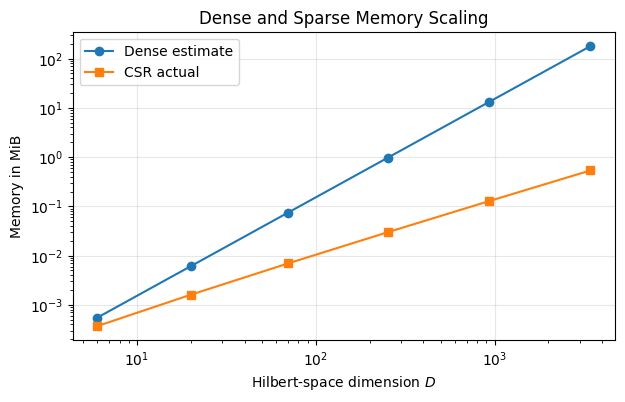

In [264]:
D_benchmark = [
    result[1]
    for result in benchmark_results
]

dense_memory_mb = [
    bytes_to_mb(result[5])
    for result in benchmark_results
]

sparse_memory_mb = [
    bytes_to_mb(result[6])
    for result in benchmark_results
]

plt.figure(figsize=(7, 4))

plt.plot(
    D_benchmark, dense_memory_mb, 
    "o-", label = "Dense estimate"
)

plt.plot(
    D_benchmark, sparse_memory_mb,
    "s-", label = "CSR actual"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Hilbert-space dimension $D$")
plt.ylabel(r"Memory in MiB")

plt.title("Dense and Sparse Memory Scaling")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 3.13 Physical and Numerical Consistency Checks

A numerical many-body implementation should be validated through physical constraints rather than relying only on successful code execution.

The sparse XXZ Hamiltonian must satisfy several independent conditions.

### Hilbert-space dimension

For fixed $N_\uparrow$,

$$
D
=
\binom{L}{N_\uparrow}.
$$

### Hermiticity

The Hamiltonian must satisfy

$$
H=H^\dagger.
$$

### Dense-sparse agreement

For sufficiently small systems,

$$
H_{\mathrm{sparse}}
=
H_{\mathrm{dense}}.
$$

### Spectral agreement

The eigenvalues obtained from both representations must satisfy

$$
E_n^{\mathrm{sparse}}
=
E_n^{\mathrm{dense}}.
$$

### Matrix-vector action

For an arbitrary state $|\psi\rangle$,

$$
H_{\mathrm{sparse}}|\psi\rangle
=
H_{\mathrm{dense}}|\psi\rangle.
$$

### Magnetization-sector consistency

Every basis state must contain exactly the prescribed number of up spins,

$$
N_\uparrow
=
L-\operatorname{popcount}(n).
$$

These checks provide independent tests of the basis construction, matrix-element generation, sparse representation, and eigensolver behaviour.

In [265]:
L_validation = 8
N_up_validation = 4

basis_dense_val, H_dense_val = build_xxz_reduced(
    L=L_validation,
    N_up=N_up_validation,
    Delta=Delta,
    lam=lam,
    J=J
)
basis_sparse_val, H_sparse_val = build_xxz_sparse(
    L=L_validation,
    N_up=N_up_validation,
    Delta=Delta,
    lam=lam,
    J=J
)

H_csr_val = H_sparse_val.tocsr()

assert len(basis_sparse_val) == comb(
    L_validation, N_up_validation
)

assert np.array_equal(
    basis_sparse_val, basis_dense_val
)

assert all(
    L_validation
    - int(state).bit_count()
    == N_up_validation
    for state in basis_sparse_val
)

assert np.allclose(
    H_dense_val, H_csr_val.toarray()
)

H_hermitian_error = (
    H_csr_val
    -
    H_csr_val.getH()
)

assert (
    H_hermitian_error.nnz == 0
    or
    np.max(
        np.abs(
            H_hermitian_error.data
        )
    ) < 1e-12
)

E_dense_val = np.linalg.eigvalsh(H_dense_val)
E_sparse_val = np.linalg.eigvalsh(H_csr_val.toarray())

assert np.allclose(
    E_dense_val, E_sparse_val
)

rng = np.random.default_rng(1234)

phi_val = (
    rng.normal(size = len(basis_sparse_val))
    + 1j*rng.normal(size = len(basis_sparse_val))
)

phi_val /= np.linalg.norm(phi_val)

assert np.allclose(
    H_dense_val @ phi_val, H_csr_val @ phi_val
)

print(
    "All physical and numerical validation tests passed."
)

All physical and numerical validation tests passed.


## 3.14 Summary of the Sparse Hamiltonian Representation

The numerical representation of the XXZ Hamiltonian has now been transformed from a dense reduced matrix into a directly constructed sparse operator.

The complete progression is

$$
\text{dense reduced Hamiltonian}
\rightarrow
\text{direct COO construction}
\rightarrow
\text{CSR representation}.
$$

The COO format provides a convenient representation during Hamiltonian construction because individual matrix elements can be generated directly from the physical interactions.

The CSR format is more appropriate for repeated numerical operations, particularly matrix-vector products of the form

$$
H|\psi\rangle.
$$

For a dense matrix, memory requirements scale as

$$
O(D^2).
$$

For a local sparse Hamiltonian, the number of stored elements scales approximately as

$$
O(LD),
$$

leading to a substantial reduction in memory usage.

However, the Hilbert-space dimension itself still grows exponentially,

$$
D
=
\binom{L}{N_\uparrow}
\sim
e^{cL}.
$$

Sparse representations therefore extend the range of accessible system sizes but do not eliminate the fundamental exponential complexity of exact diagonalization.

The sparse implementation has been independently validated through:

$$
H_{\mathrm{sparse}}
=
H_{\mathrm{dense}},
$$

$$
H=H^\dagger,
$$

$$
E_n^{\mathrm{sparse}}
=
E_n^{\mathrm{dense}},
$$

and

$$
H_{\mathrm{sparse}}|\psi\rangle
=
H_{\mathrm{dense}}|\psi\rangle.
$$

The implementation is now suitable for iterative eigensolvers based on Krylov-subspace methods.

However, before analysing level-spacing statistics, an additional symmetry of the open XXZ chain must be resolved.

The next stage of the project will therefore be

$$
\boxed{
\text{reflection parity}
}
$$

followed by

$$
\boxed{
\text{symmetry-resolved spectral statistics}
}.
$$

The numerical progression of the project is now

$$
2^L
\rightarrow
\binom{L}{N_\uparrow}
\rightarrow
\text{binary basis}
\rightarrow
\text{sparse Hamiltonian}
\rightarrow
\text{parity sectors}
\rightarrow
\text{Poisson/GOE statistics}.
$$

# 4. Remaining Symmetries and Reflection Parity

The conservation of total magnetization allowed the XXZ Hamiltonian to be restricted to a fixed-$N_\uparrow$ sector,

$$
\mathcal{H}
\rightarrow
\mathcal{H}_{N_\uparrow}.
$$

However, this does not necessarily produce an irreducible symmetry sector.

For the homogeneous open XXZ chain considered here, the Hamiltonian is also invariant under spatial reflection,

$$
i
\rightarrow
L-1-i.
$$

The corresponding reflection operator will be denoted by $P$.

Because the Hamiltonian is invariant under this transformation,

$$
[H,P]=0.
$$

The eigenstates of the Hamiltonian can therefore also be classified according to their reflection parity,

$$
P|\psi\rangle
=
p|\psi\rangle,
$$

with

$$
p=\pm1.
$$

This additional symmetry must be resolved before calculating level-spacing statistics.

Mixing levels belonging to different parity sectors would combine statistically independent spectra and could artificially suppress the level repulsion expected in a quantum-chaotic system.

The objective of this section is therefore to perform the decomposition

$$
\mathcal{H}_{N_\uparrow}
=
\mathcal{H}_{N_\uparrow,+}
\oplus
\mathcal{H}_{N_\uparrow,-}.
$$

## 4.1 Why Magnetization Reduction Is Not Enough

The conservation law

$$
[H,S_{\mathrm{tot}}^z]=0
$$

allows the Hamiltonian to be separated into independent magnetization sectors.

However, a fixed magnetization sector may still contain additional independent symmetry subsectors.

For the present open chain, spatial reflection provides one such symmetry.

If the energy spectrum is computed without resolving reflection parity, the resulting ordered eigenvalues contain contributions from both

$$
p=+1
$$

and

$$
p=-1.
$$

Levels belonging to different symmetry sectors do not interact and can cross freely.

This is problematic for quantum-chaos diagnostics because level repulsion is expected only between levels belonging to the same irreducible symmetry sector.

Therefore, the correct sequence for spectral analysis is

$$
\text{full Hilbert space}
\rightarrow
\text{fixed magnetization}
\rightarrow
\text{fixed parity}
\rightarrow
\text{spectral statistics}.
$$

## 4.2 Spatial Reflection Symmetry

For an open chain containing $L$ sites, spatial reflection maps site $i$ onto

$$
i
\rightarrow
L-1-i.
$$

For example, in a four-site system,

$$
(0,1,2,3)
\rightarrow
(3,2,1,0).
$$

Therefore, a computational-basis state transforms as

$$
|\sigma_0\sigma_1\cdots\sigma_{L-1}\rangle
\rightarrow
|\sigma_{L-1}\cdots\sigma_1\sigma_0\rangle.
$$

For example,

$$
|\uparrow\uparrow\downarrow\downarrow\rangle
\rightarrow
|\downarrow\downarrow\uparrow\uparrow\rangle.
$$

In the binary convention used throughout this project,

$$
0\leftrightarrow\uparrow,
\qquad
1\leftrightarrow\downarrow,
$$

this corresponds to

$$
0011
\rightarrow
1100.
$$

The reflection operator satisfies

$$
P^2=I,
$$

because applying the transformation twice restores the original state.

Therefore, if

$$
P|\psi\rangle=p|\psi\rangle,
$$

then

$$
p^2=1,
$$

and the only possible parity eigenvalues are

$$
p=\pm1.
$$

In [266]:
def reflect_states(
        state: int,
        L: int
) -> int:
    reflected = 0
    
    for position in range(L):

        bit = (
            int(state) >> position
        ) & 1

        if bit:
            reflected |= (
                1 << (L - 1 - position)
            )
    return reflected

In [267]:
L = 4

test_states = [
    3,   # 0011
    5,   # 0101
    6,   # 0110
    9    # 1001
]

for state in test_states:

    reflected = reflect_states(
        state=state,
        L=L
    )

    print(
        format(state, f"0{L}b"),
        "->",
        format(reflected, f"0{L}b")
    )

0011 -> 1100
0101 -> 1010
0110 -> 0110
1001 -> 1001


### Reflection of Binary Basis States

The binary representation makes spatial reflection particularly simple.

The transformation reverses the order of the $L$ bits,

$$
b_0b_1\cdots b_{L-1}
\rightarrow
b_{L-1}\cdots b_1b_0.
$$

Some configurations are mapped onto a different basis state, while others are invariant under reflection.

States satisfying

$$
P|n\rangle=|n\rangle
$$

will later require special treatment when the parity-adapted basis is constructed.

## 4.4 Reflection Operator in the Reduced Basis

Within a fixed-$N_\uparrow$ basis, reflection preserves the number of up and down spins.

Therefore,

$$
P:
\mathcal{H}_{N_\uparrow}
\rightarrow
\mathcal{H}_{N_\uparrow}.
$$

For each computational-basis state $|n\rangle$, the reflection operator acts as

$$
P|n\rangle
=
|R(n)\rangle,
$$

where $R(n)$ denotes the bit-reversed state.

In matrix form, $P$ is a permutation matrix.

Each column contains exactly one non-zero element equal to one.

In [ ]:
def build_reflection_operator(
    basis: np.ndarray,
    L: int
) -> csr_matrix:
    
    D = len(basis)

    state_to_index = {
        int(state): index
        for index, state in enumerate(basis)
    }

    rows = []
    cols = []
    data = []

    for column, state_raw in enumerate(basis):

        state = int(state_raw)

        reflected_state = reflect_states(
            state,
            L
        )

        row = state_to_index[
            reflected_state
        ]

        rows.append(row)
        cols.append(column)
        data.append(1.0)

    P = coo_matrix(
        (
            data,
            (rows, cols)
        ),
        shape=(D, D),
        dtype=float
    ).tocsr()

    return P

In [269]:
L = 4
N_up = 2

basis = fixed_magnetization_basis(
    L,
    N_up
)

P = build_reflection_operator(
    basis,
    L
)

print("Basis:")
print(basis)

print()

print("Reflection operator:")
print(P.toarray())

Basis:
[ 3  5  6  9 10 12]

Reflection operator:
[[0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]


## 4.5 Symmetry Checks

Before using reflection parity to decompose the Hamiltonian, the numerical operator must satisfy the expected algebraic properties.

The first condition is

$$
P^2=I.
$$

The reflection operator is also Hermitian,

$$
P^\dagger=P,
$$

and therefore unitary,

$$
P^\dagger P=I.
$$

Finally, reflection is a symmetry of the homogeneous open XXZ Hamiltonian,

$$
[H,P]=0.
$$

The last relation guarantees that the Hamiltonian and the reflection operator can be simultaneously diagonalized.

In [270]:
basis_test, H_test = build_xxz_sparse(
    L=L,
    N_up=N_up,
    Delta=0.7,
    lam=0.5,
    J=1.0
)

H_test = H_test.tocsr()

P = build_reflection_operator(
    basis_test,
    L
)

D = len(basis_test)

I = sparse.identity(
    D,
    format="csr"
)

In [271]:
P_squared_error = (
    P @ P - I
)

print(
    "P^2 = I:",
    np.allclose(
        P_squared_error.toarray(),
        0.0
    )
)

print(
    "P = P^dagger:",
    np.allclose(
        P.toarray(),
        P.getH().toarray()
    )
)

commutator_HP = (
    H_test @ P
    -
    P @ H_test
)

print(
    "[H,P] = 0:",
    np.allclose(
        commutator_HP.toarray(),
        0.0
    )
)

print(
    "Commutator norm:",
    np.linalg.norm(
        commutator_HP.toarray()
    )
)

P^2 = I: True
P = P^dagger: True
[H,P] = 0: True
Commutator norm: 0.0


### Reflection-Symmetry Validation

The numerical reflection operator satisfies

$$
P^2=I
$$

and

$$
P=P^\dagger.
$$

Furthermore, the commutator with the XXZ Hamiltonian vanishes within numerical precision,

$$
\left\|
[H,P]
\right\|
\approx0.
$$

The Hamiltonian can therefore be decomposed into independent eigenspaces of $P$ corresponding to parity eigenvalues

$$
p=+1
$$

and

$$
p=-1.
$$

## 4.6 Parity Eigenstates

Consider a computational-basis state $|n\rangle$ and its reflected partner

$$
|Rn\rangle
=
P|n\rangle.
$$

If

$$
|Rn\rangle
\neq
|n\rangle,
$$

the two states can be combined into parity eigenstates,

$$
|n,+\rangle
=
\frac{1}{\sqrt{2}}
\left(
|n\rangle
+
|Rn\rangle
\right),
$$

and

$$
|n,-\rangle
=
\frac{1}{\sqrt{2}}
\left(
|n\rangle
-
|Rn\rangle
\right).
$$

Applying the reflection operator gives

$$
P|n,+\rangle
=
+|n,+\rangle,
$$

whereas

$$
P|n,-\rangle
=
-|n,-\rangle.
$$

Each pair of reflected computational-basis states therefore generates one even-parity state and one odd-parity state.

This change of basis will allow the Hamiltonian to be separated into independent parity blocks.

## 4.7 Construction of a Parity-Adapted Basis

The parity basis can be represented through transformation matrices

$$
U_+
$$

and

$$
U_-.
$$

The columns of $U_+$ contain the even-parity basis states expressed in the original fixed-magnetization basis.

Similarly, the columns of $U_-$ contain the odd-parity basis states.

For a pair

$$
|n\rangle,
\qquad
|Rn\rangle,
$$

the corresponding columns contain coefficients

$$
\frac{1}{\sqrt{2}}
$$

for the even sector and

$$
\frac{1}{\sqrt{2}},
\qquad
-\frac{1}{\sqrt{2}}
$$

for the odd sector.

Only one representative from each reflection pair must be processed in order to avoid double counting.

In [272]:
def build_parity_tranformation(
        basis: np.ndarray,
        L: int
) -> tuple[csr_matrix, csr_matrix]:

    D = len(basis)

    state_to_index = {
        int(state): int(index)
        for index, state in enumerate(basis)
    }


    rows_plus = []
    cols_plus = []
    data_plus = []

    rows_minus = []
    cols_minus = []
    data_minus = []

    plus_column = minus_column = 0

    normalization = 1/np.sqrt(2)

    for state_raw in basis:

        state = int(state_raw)

        reflected = reflect_states(
        state, L
        )

        if state > reflected:
            continue
        index_state = state_to_index[state]

        if state == reflected:

            rows_plus.append(index_state)
            cols_plus.append(plus_column)
            data_plus.append(1.0)

            plus_column += 1

        else:

            index_reflected = state_to_index[reflected]

            rows_plus.extend([index_state, index_reflected])
            cols_plus.extend([plus_column, plus_column])
            data_plus.extend([normalization, normalization])

            plus_column += 1

            rows_minus.extend([index_state, index_reflected])
            cols_minus.extend([minus_column, minus_column])
            data_minus.extend([normalization, -normalization])

            minus_column += 1

    U_plus = coo_matrix(
        (
            data_plus,
            (
                rows_plus,
                cols_plus
            )
        ),
        shape=(
            D,
            plus_column
        ),
        dtype=float
    ).tocsr()

    U_minus = coo_matrix(
        (
            data_minus,
            (
                rows_minus,
                cols_minus
            )
        ),
        shape=(
            D,
            minus_column
        ),
        dtype=float
    ).tocsr()

    return U_plus, U_minus

In [273]:
U_plus, U_minus = build_parity_tranformation(
    basis_test, L
)

print(
    "Original dimension:",
    len(basis_test)
)

print(
    "Even-parity dimension:",
    U_plus.shape[1]
)

print(
    "Odd-parity dimension:",
    U_minus.shape[1]
)

Original dimension: 6
Even-parity dimension: 4
Odd-parity dimension: 2


## 4.8 Hamiltonian Projection onto Parity Sectors

Once the parity-adapted basis has been constructed, the Hamiltonian can be projected onto each symmetry sector.

For even parity,

$$
H_+
=
U_+^\dagger
H
U_+,
$$

while for odd parity,

$$
H_-
=
U_-^\dagger
H
U_-.
$$

Because

$$
[H,P]=0,
$$

the two parity sectors are dynamically independent.

In the parity-adapted basis, the Hamiltonian therefore has the block structure

$$
H
\sim
\begin{pmatrix}
H_+ & 0\\
0 & H_-
\end{pmatrix}.
$$

In [274]:
H_plus = (
    U_plus.getH() @ H_test @ U_plus
).tocsr()

H_minus = (
    U_minus.getH() @ H_test @ U_minus
).tocsr()

H_plus.eliminate_zeros()
H_minus.eliminate_zeros()

print(
    "H_plus shape: ",
    H_plus.shape
)

print(
    "H_minus shape: ",
    H_minus.shape
)

print("H_plus: ")
print(H_plus)

print("H_minus")
print(H_minus)

H_plus shape:  (4, 4)
H_minus shape:  (2, 2)
H_plus: 
<Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 13 stored elements and shape (4, 4)>
  Coords	Values
  (0, 1)	(0.4999999999999999+0j)
  (0, 2)	(0.35355339059327373+0j)
  (0, 3)	(0.35355339059327373+0j)
  (1, 0)	(0.4999999999999999+0j)
  (1, 1)	(-0.3499999999999999+0j)
  (1, 2)	(0.7071067811865475+0j)
  (1, 3)	(0.7071067811865475+0j)
  (2, 0)	(0.35355339059327373+0j)
  (2, 1)	(0.7071067811865475+0j)
  (2, 2)	(-0.35+0j)
  (3, 0)	(0.35355339059327373+0j)
  (3, 1)	(0.7071067811865475+0j)
  (3, 3)	(-0.35+0j)
H_minus
<Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 3 stored elements and shape (2, 2)>
  Coords	Values
  (0, 1)	(0.4999999999999999+0j)
  (1, 0)	(0.4999999999999999+0j)
  (1, 1)	(-0.3499999999999999+0j)


## 4.9 Validation of the Parity Decomposition

The parity decomposition must preserve the complete spectrum of the original fixed-magnetization Hamiltonian.

Therefore,

$$
\operatorname{spec}(H)
=
\operatorname{spec}(H_+)
\cup
\operatorname{spec}(H_-).
$$

The dimensions must also satisfy

$$
D
=
D_+
+
D_-.
$$

Finally, the transformation matrices should define orthonormal bases,

$$
U_+^\dagger U_+=I_+,
$$

and

$$
U_-^\dagger U_-=I_-.
$$

The even and odd sectors must also be mutually orthogonal,

$$
U_+^\dagger U_-=0.
$$

In [275]:
D = len(basis_test)

D_plus = H_plus.shape[0]
D_minus = H_minus.shape[0]

print(
    "Dimension conserved:",
    D == D_plus + D_minus
)

Dimension conserved: True


In [276]:
I_plus = sparse.identity(
    D_plus,
    format="csr"
)

I_minus = sparse.identity(
    D_minus,
    format="csr"
)

print(
    "U_plus orthonormal:",
    np.allclose(
        (
            U_plus.getH()
            @ U_plus
        ).toarray(),
        I_plus.toarray()
    )
)

print(
    "U_minus orthonormal:",
    np.allclose(
        (
            U_minus.getH()
            @ U_minus
        ).toarray(),
        I_minus.toarray()
    )
)

print(
    "Parity sectors orthogonal:",
    np.allclose(
        (
            U_plus.getH()
            @ U_minus
        ).toarray(),
        0.0
    )
)

U_plus orthonormal: True
U_minus orthonormal: True
Parity sectors orthogonal: True


In [277]:
E_full = np.linalg.eigvalsh(H_test.toarray())
E_plus = np.linalg.eigvalsh(H_plus.toarray())
E_minus = np.linalg.eigvalsh(H_minus.toarray())

E_parity = np.sort(
    np.concatenate([
        E_plus, E_minus
    ])
)    

print(
    "Spectrum preserved: ",
    np.allclose(
        E_full, E_parity
    )
)

print(
    "Maximal spectrum error: ",
    np.max(
        np.abs(E_full - E_parity)
    )
)

Spectrum preserved:  True
Maximal spectrum error:  6.661338147750939e-16


### Parity-Decomposition Validation

The fixed-magnetization Hilbert space has been successfully decomposed as

$$
\mathcal{H}_{N_\uparrow}
=
\mathcal{H}_{N_\uparrow,+}
\oplus
\mathcal{H}_{N_\uparrow,-}.
$$

The transformation matrices form orthonormal bases within each parity sector and the two sectors are mutually orthogonal.

Furthermore,

$$
D=D_++D_-,
$$

and the union of both parity spectra reproduces the complete spectrum of the original fixed-magnetization Hamiltonian.

This confirms that the parity transformation reorganizes the Hilbert space without changing the physical spectrum.

## 4.10 Self-Reflected States

Some computational-basis states are invariant under spatial reflection,

$$
R(n)=n.
$$

For example,

$$
0110
\rightarrow
0110.
$$

Such a state already satisfies

$$
P|n\rangle=+|n\rangle.
$$

It therefore belongs exclusively to the even-parity sector.

Attempting to construct an odd combination would give

$$
\frac{1}{\sqrt{2}}
\left(
|n\rangle-|n\rangle
\right)
=
0.
$$

Consequently, self-reflected computational states contribute only to

$$
p=+1.
$$

This explains why the dimensions of the two parity sectors are not necessarily equal.

In [278]:
print(
    "Self-reflected basis states:"
)

for state_raw in basis_test:

    state = int(state_raw)

    if reflect_states(
        state,
        L
    ) == state:

        print(
            format(
                state,
                f"0{L}b"
            )
        )

Self-reflected basis states:
0110
1001


## 4.11 Additional Symmetry at Half Filling

Reflection parity is not necessarily the only remaining symmetry of the XXZ Hamiltonian.

For the present model, global spin inversion transforms

$$
|\uparrow\rangle
\leftrightarrow
|\downarrow\rangle.
$$

Equivalently,

$$
N_\uparrow
\rightarrow
L-N_\uparrow.
$$

For a generic magnetization sector,

$$
N_\uparrow
\neq
\frac{L}{2},
$$

spin inversion maps the state into a different magnetization sector and therefore does not introduce an additional symmetry inside the sector being analysed.

At half filling,

$$
N_\uparrow
=
\frac{L}{2},
$$

the transformation remains inside the same magnetization sector.

This introduces an additional discrete symmetry that would also need to be resolved before performing clean level-statistics calculations.

For this reason, a convenient strategy for the quantum-chaos analysis is to work in a non-zero magnetization sector, for example

$$
N_\uparrow
=
\frac{L}{2}+1
$$

or

$$
N_\uparrow
=
\frac{L}{2}-1,
$$

and then resolve reflection parity.

This avoids mixing the additional spin-inversion symmetry present at half filling.

## 4.12 Summary of Reflection-Parity Reduction

The fixed-magnetization Hamiltonian possesses an additional spatial-reflection symmetry,

$$
[H,P]=0.
$$

The reflection operator satisfies

$$
P^2=I,
$$

and therefore has eigenvalues

$$
p=\pm1.
$$

Pairs of reflected computational-basis states generate parity eigenstates,

$$
|n,\pm\rangle
=
\frac{
|n\rangle
\pm
|Rn\rangle
}{
\sqrt{2}
}.
$$

Using the corresponding transformation matrices, the Hamiltonian has been decomposed into two independent blocks,

$$
H_+
=
U_+^\dagger H U_+,
$$

and

$$
H_-
=
U_-^\dagger H U_-.
$$

The complete fixed-magnetization Hilbert space therefore decomposes as

$$
\mathcal{H}_{N_\uparrow}
=
\mathcal{H}_{N_\uparrow,+}
\oplus
\mathcal{H}_{N_\uparrow,-}.
$$

The parity decomposition has been validated through dimensional consistency, orthonormality of the transformed basis, and conservation of the complete energy spectrum.

For future spectral-statistics calculations, it is also advantageous to avoid the half-filled sector because global spin inversion constitutes an additional internal symmetry when

$$
N_\uparrow=L/2.
$$

A convenient working strategy will therefore be

$$
\boxed{
N_\uparrow\neq L/2
}
$$

combined with a fixed reflection parity.

The numerical hierarchy is now

$$
\text{full Hilbert space}
\rightarrow
\text{fixed magnetization}
\rightarrow
\text{sparse representation}
\rightarrow
\text{fixed reflection parity}.
$$

The Hamiltonian is now sufficiently symmetry resolved to begin the analysis of quantum-chaos signatures through spectral statistics.

# 5. Spectral Statistics and Quantum Chaos

The previous sections developed a symmetry-resolved representation of the interacting XXZ spin chain.

The numerical hierarchy is now

$$
\text{full Hilbert space}
\rightarrow
\text{fixed magnetization}
\rightarrow
\text{fixed reflection parity}.
$$

This symmetry resolution is essential before analysing spectral correlations.

The central idea of quantum-chaos spectroscopy is that the statistical properties of energy levels contain information about the underlying dynamics.

For quantum-integrable systems, neighbouring levels are approximately statistically independent and level crossings are not strongly suppressed.

Their spectral statistics are therefore expected to approach Poisson statistics.

For generic non-integrable systems with the appropriate antiunitary symmetry, level repulsion emerges and the spectral correlations approach those of the Gaussian Orthogonal Ensemble (GOE).

The XXZ model considered here provides a convenient setting for studying this crossover.

At

$$
\lambda=0,
$$

the nearest-neighbour XXZ chain is integrable.

For generic finite $\lambda$, the next-nearest-neighbour interaction breaks integrability and a quantum-chaotic regime is expected.

The objective of this section is to quantify this transition using symmetry-resolved energy spectra.

## 5.1 Symmetry-Resolved Spectra

Level statistics must be calculated within a single irreducible symmetry sector.

In the present model, we therefore fix:

- the system size $L$;
- the number of up spins $N_\uparrow$;
- the reflection parity $p=\pm1$.

To avoid the additional global spin-inversion symmetry present at half filling, the spectral analysis will use

$$
N_\uparrow\neq\frac{L}{2}.
$$

For even $L$, a convenient choice is

$$
N_\uparrow
=
\frac{L}{2}+1.
$$

Within this sector, the Hamiltonian is first constructed in sparse form and subsequently projected onto one reflection-parity subspace,

$$
H_p
=
U_p^\dagger H U_p.
$$

For moderate Hilbert-space dimensions, the complete spectrum of this parity block can then be obtained using dense Hermitian diagonalization.

This is useful because spectral statistics require many consecutive energy levels rather than only a few extremal eigenvalues.

In [279]:
def build_parity_hamiltonian(
        L:int, 
        N_up: int, 
        parity: int,
        Delta: float = 0.7,
        lam: float = 0.0,
        J: float = 1.0
) -> csr_matrix:

    if parity not in (+1,-1):
        raise ValueError("parity must be between +1 and -1")

    basis, H = build_xxz_sparse(
        L=L,
        N_up=N_up,
        Delta=Delta,
        lam=lam,
        J=J
    )

    H = H.tocsr()

    U_plus, U_minus = build_parity_tranformation(
        basis, L
    )

    if parity == +1: 
        U = U_plus
    else:
        U = U_minus

    H_parity = (
        U.getH() @ H @ U
    ).tocsr()

    H_parity.sum_duplicates()
    H_parity.eliminate_zeros()

    return H_parity

In [280]:
L = 12
N_up = 7
parity = +1

Delta = 0.7
J = 1.0
lam = 0.0

H_parity = build_parity_hamiltonian(
    L=L,
    N_up=N_up,
    parity=parity,
    Delta=Delta,
    lam=lam,
    J=J
)

print(
    "Parity-sector dimension:",
    H_parity.shape[0]
)

E = np.linalg.eigvalsh(
    H_parity.toarray()
)

print(
    "Number of eigenvalues:",
    len(E)
)

print(
    "Ground-state energy:",
    E[0]
)

print(
    "Maximum energy:",
    E[-1]
)

Parity-sector dimension: 396
Number of eigenvalues: 396
Ground-state energy: -4.100509979981922
Maximum energy: 2.892149635004284


## 5.2 Spectral Bulk and Edge Effects

The statistical properties of a finite many-body spectrum are not uniform over the complete energy range.

States near the spectral edges often display stronger finite-size effects and a different local density of states from states near the centre of the spectrum.

Universal random-matrix behaviour is therefore usually investigated in the spectral bulk.

Instead of immediately using every eigenvalue, we retain only a central fraction of the ordered spectrum.

If the complete spectrum contains $N$ energy levels,

$$
E_1<E_2<\cdots<E_N,
$$

we define a bulk window by discarding equal fractions of levels from both spectral edges.

This procedure does not constitute spectral unfolding.

It simply reduces edge effects before evaluating local spectral quantities such as the adjacent-gap ratio.

In [281]:
def select_spectral_bulk(
        energies: np.ndarray,
        fraction: float= 0.5
) -> np.ndarray:

    if not 0.0 < fraction <= 1.0:
        raise ValueError("fraction must satisfy 0 < fraction <= 1")

    energies = np.sort(
        np.asarray(energies)
    )

    N = len(energies)

    n_keep = int(fraction*N)

    start = (N - n_keep) // 2

    stop = start + n_keep

    return energies[start:stop]

In [282]:
E_bulk = select_spectral_bulk(
    E, fraction=0.5
)

print("Full spectrum: ",
    len(E)
)

print("Bulk spectrum: ",
    len(E_bulk)
)

Full spectrum:  396
Bulk spectrum:  198


## 5.3 Nearest-Neighbour Level Spacings

For an ordered energy spectrum,

$$
E_1<E_2<\cdots<E_N,
$$

the nearest-neighbour level spacings are defined as

$$
s_n
=
E_{n+1}-E_n.
$$

These spacings measure the local separation between consecutive energy levels.

For an integrable system, neighbouring energy levels are approximately uncorrelated and small spacings are not strongly suppressed.

For a chaotic system, neighbouring levels belonging to the same symmetry sector repel each other.

Consequently, the probability of finding

$$
s_n\approx0
$$

is strongly reduced.

However, the mean level spacing varies across a finite many-body spectrum because the density of states is energy dependent.

A direct comparison of spacing distributions therefore requires an unfolding procedure.

Before introducing unfolding, we first consider a related quantity that avoids this complication: the adjacent-gap ratio.

In [283]:
def level_spacings(
    energies: np.ndarray
) -> np.ndarray:

    energies = np.sort(
        np.asarray(energies)
    )

    return np.diff(
        energies
    )

In [284]:
spacings = level_spacings(
    E_bulk
)

print(
    "Number of spacings:",
    len(spacings)
)

print(
    "Mean raw spacing:",
    np.mean(spacings)
)

print(
    "Minimum spacing:",
    np.min(spacings)
)

Number of spacings: 197
Mean raw spacing: 0.009457265415514808
Minimum spacing: 2.8803230751495157e-05


## 5.4 Adjacent-Gap Ratio

A particularly useful diagnostic of quantum chaos is the adjacent-gap ratio.

Given two consecutive spacings,

$$
s_n
=
E_{n+1}-E_n,
$$

and

$$
s_{n+1}
=
E_{n+2}-E_{n+1},
$$

the symmetrized adjacent-gap ratio is defined as

$$
r_n
=
\frac{
\min(s_n,s_{n+1})
}{
\max(s_n,s_{n+1})
}.
$$

By construction,

$$
0\leq r_n\leq1.
$$

The main advantage of this statistic is that it compares neighbouring spacings directly.

As a result, it is largely insensitive to slow variations of the local density of states and does not require spectral unfolding.

The average ratio

$$
\langle r\rangle
=
\frac{1}{N_r}
\sum_n r_n
$$

provides a simple scalar diagnostic of spectral correlations.

This quantity will therefore be used as the primary indicator of the integrability-to-chaos crossover.

In [285]:
def adjacent_gap_ratios(
    energies: np.ndarray,
    tolerance: float = 1e-14
) -> np.ndarray:
    """
    Compute symmetrized adjacent-gap ratios.
    """

    spacings = level_spacings(
        energies
    )

    s_left = spacings[:-1]
    s_right = spacings[1:]

    denominator = np.maximum(
        s_left,
        s_right
    )

    valid = denominator > tolerance

    ratios = (
        np.minimum(
            s_left[valid],
            s_right[valid]
        )
        /
        denominator[valid]
    )

    return ratios

In [286]:
r_values = adjacent_gap_ratios(
    E_bulk
)

print(
    "Number of gap ratios:",
    len(r_values)
)

print(
    "<r> =",
    np.mean(r_values)
)

Number of gap ratios: 196
<r> = 0.38250174035188544


## 5.5 Poisson and GOE Predictions

The adjacent-gap ratio has characteristic values in integrable and chaotic quantum systems.

For statistically independent energy levels following Poisson statistics,

$$
\langle r\rangle_{\mathrm{Poisson}}
=
2\ln2-1
\approx
0.3863.
$$

This behaviour is characteristic of generic quantum-integrable systems.

For chaotic systems in the Gaussian Orthogonal Ensemble universality class, one expects approximately

$$
\langle r\rangle_{\mathrm{GOE}}
\approx
0.53.
$$

The distinction

$$
0.386
\longrightarrow
0.53
$$

therefore provides a convenient numerical signature of the transition from integrable to chaotic spectral statistics.

The XXZ Hamiltonian used in this project can be represented by a real symmetric matrix, placing the generic chaotic regime in the GOE symmetry class.

In [287]:
r_poisson = (
    2.0*np.log(2.0) - 1.0
)

r_goe = 0.5307

print(
    "Poisson <r>:",
    r_poisson
)

print(
    "GOE <r>: ",
    r_goe
)

Poisson <r>: 0.3862943611198906
GOE <r>:  0.5307


## 5.6 Integrable versus Chaotic Regimes

We now compare two Hamiltonians within exactly the same symmetry sector.

The first corresponds to the integrable nearest-neighbour XXZ chain,

$$
\lambda=0.
$$

The second includes a next-nearest-neighbour interaction,

$$
\lambda>0,
$$

which generically breaks integrability.

We choose

$$
\lambda=0.5
$$

as an initial representative of the non-integrable regime.

It is essential that both spectra are calculated using the same values of

$$
L,
\qquad
N_\uparrow,
\qquad
p,
\qquad
\Delta.
$$

Otherwise, differences in the statistics could arise from mixing different physical symmetry sectors rather than from integrability breaking.

In [288]:
L = 12
N_up = 7
parity = +1

Delta = 0.7
J = 1.0

lambda_integrable = 0.0
lambda_chaotic = 0.5

In [289]:
H_integrable = build_parity_hamiltonian(
    L=L,
    N_up=N_up,
    parity=parity,
    Delta=Delta,
    lam=lambda_integrable,
    J=J
)

H_chaotic = build_parity_hamiltonian(
    L=L,
    N_up=N_up,
    parity=parity,
    Delta=Delta,
    lam=lambda_chaotic,
    J=J
)

In [290]:
E_integrable = np.linalg.eigvalsh(
    H_integrable.toarray()
)

E_chaotic = np.linalg.eigvalsh(
    H_chaotic.toarray()
)

E_integrable_bulk = select_spectral_bulk(E_integrable, fraction=0.5)
E_chaotic_bulk = select_spectral_bulk(E_chaotic, fraction=0.5)

In [291]:
r_integrable = adjacent_gap_ratios(
    E_integrable_bulk
)

r_chaotic = adjacent_gap_ratios(
    E_chaotic_bulk
)

mean_r_integrable = np.mean(
    r_integrable
)

mean_r_chaotic = np.mean(
    r_chaotic
)

print(
    f"lambda = {lambda_integrable:.2f}"
    f" -> <r> = {mean_r_integrable:.6f}"
)

print(
    f"lambda = {lambda_chaotic:.2f}"
    f" -> <r> = {mean_r_chaotic:.6f}"
)

print()

print(
    f"Poisson reference = {r_poisson:.6f}"
)

print(
    f"GOE reference = {r_goe:.6f}"
)

lambda = 0.00 -> <r> = 0.382502
lambda = 0.50 -> <r> = 0.562264

Poisson reference = 0.386294
GOE reference = 0.530700


### First Integrability-to-Chaos Comparison

The symmetry-resolved adjacent-gap ratio changes significantly when the next-nearest-neighbour interaction is introduced.

For the integrable limit,

$$
\lambda=0,
$$

the result should be compared with the Poisson reference value

$$
\langle r\rangle_{\mathrm{Poisson}}
\approx0.386.
$$

For the non-integrable Hamiltonian,

$$
\lambda=0.5,
$$

the corresponding result should be compared with the GOE value

$$
\langle r\rangle_{\mathrm{GOE}}
\approx0.53.
$$

Agreement is not expected to be exact for a finite system.

Finite-size corrections, the chosen spectral window, and the strength of the integrability-breaking perturbation can all produce deviations from the asymptotic random-matrix predictions.

The relevant observation is therefore the systematic evolution of the spectral correlations rather than agreement with a reference value at a single system size.

## 5.7 Distribution of Adjacent-Gap Ratios

The mean value $\langle r\rangle$ provides a compact diagnostic, but it compresses the complete spectral information into a single number.

A more detailed comparison can be obtained from the probability distribution

$$
P(r).
$$

For Poisson statistics, the symmetrized ratio distribution is

$$
P_{\mathrm{P}}(r)
=
\frac{2}{(1+r)^2},
\qquad
0\leq r\leq1.
$$

For the GOE, level repulsion modifies the distribution and suppresses the probability of very small values of $r$.

Comparing the numerical histogram with these theoretical expectations provides a more detailed diagnostic of spectral correlations.

In [292]:
def poisson_ratio_distribution(
    r: np.ndarray
) -> np.ndarray:

    return (
        2.0
        /
        (1.0 + r)**2
    )


def goe_ratio_distribution(
    r: np.ndarray
) -> np.ndarray:

    return (
        (27.0 / 4.0)
        *
        (r + r**2)
        /
        (1.0 + r + r**2)**2.5
    )

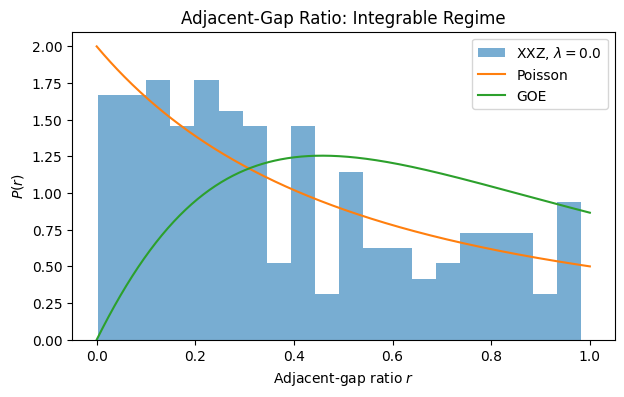

In [293]:
r_grid = np.linspace(
    0.0,
    1.0,
    500
)

plt.figure(
    figsize=(7, 4)
)

plt.hist(
    r_integrable,
    bins=20,
    density=True,
    alpha=0.6,
    label=rf"XXZ, $\lambda={lambda_integrable}$"
)

plt.plot(
    r_grid,
    poisson_ratio_distribution(r_grid),
    label="Poisson"
)

plt.plot(
    r_grid,
    goe_ratio_distribution(r_grid),
    label="GOE"
)

plt.xlabel(
    r"Adjacent-gap ratio $r$"
)

plt.ylabel(
    r"$P(r)$"
)

plt.title(
    "Adjacent-Gap Ratio: Integrable Regime"
)

plt.legend()
plt.show()

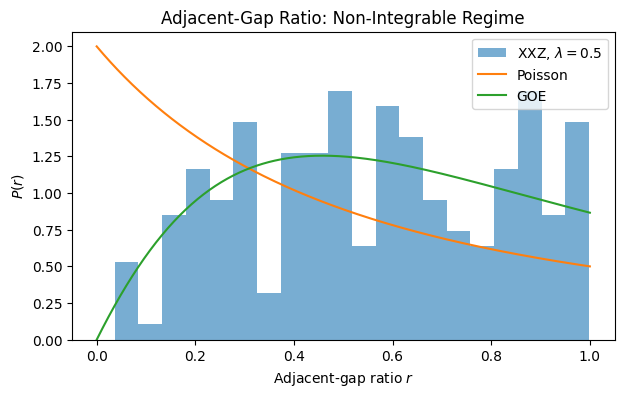

In [294]:
plt.figure(
    figsize=(7, 4)
)

plt.hist(
    r_chaotic,
    bins=20,
    density=True,
    alpha=0.6,
    label=rf"XXZ, $\lambda={lambda_chaotic}$"
)

plt.plot(
    r_grid,
    poisson_ratio_distribution(r_grid),
    label="Poisson"
)

plt.plot(
    r_grid,
    goe_ratio_distribution(r_grid),
    label="GOE"
)

plt.xlabel(
    r"Adjacent-gap ratio $r$"
)

plt.ylabel(
    r"$P(r)$"
)

plt.title(
    "Adjacent-Gap Ratio: Non-Integrable Regime"
)

plt.legend()
plt.show()

## 5.8 Nearest-Neighbour Spacing Distribution and Spectral Unfolding

Unlike the adjacent-gap ratio, the nearest-neighbour spacing distribution depends directly on the local density of states.

The raw spacings

$$
s_n
=
E_{n+1}-E_n
$$

cannot therefore be compared directly across different regions of the spectrum.

To remove the smooth variation of the density of states, the spectrum must be unfolded.

Let

$$
N(E)
$$

denote the integrated density of states.

It can be decomposed approximately into a smooth part and a fluctuating part,

$$
N(E)
=
\overline{N}(E)
+
N_{\mathrm{fluc}}(E).
$$

The unfolded energies are defined as

$$
\varepsilon_n
=
\overline{N}(E_n).
$$

The corresponding spacings,

$$
s_n
=
\varepsilon_{n+1}
-
\varepsilon_n,
$$

have approximately unit mean spacing.

Spectral unfolding is not unique and can introduce systematic effects.

For this reason, the adjacent-gap ratio remains the primary statistic in this project, while unfolded spacing distributions will be used as a complementary diagnostic.

In [295]:
def unfold_spectrum(
        energies: np.ndarray,
        degree: int = 5
) -> np.ndarray:

    energies = np.sort(
        np.asarray(energies)
    )

    staircase = np.arange(1, len(energies) + 1)

    coefficients = np.polyfit(
        energies, 
        staircase, 
        degree
    )

    unfolded = np.polyval(
        coefficients,
        energies
    )

    return unfolded

In [296]:
epsilon_integrable = unfold_spectrum(
    E_integrable_bulk,
    degree=5
)

epsilon_chaotic = unfold_spectrum(
    E_chaotic_bulk,
    degree=5
)

s_integrable = np.diff(
    epsilon_integrable
)

s_chaotic = np.diff(
    epsilon_chaotic
)

s_integrable /= np.mean(s_integrable)

s_chaotic /= np.mean(s_chaotic)

print(
    "Mean unfolded spacing, integrable:",
    np.mean(s_integrable)
)

print(
    "Mean unfolded spacing, chaotic:",
    np.mean(s_chaotic)
)

Mean unfolded spacing, integrable: 1.0000000000000002
Mean unfolded spacing, chaotic: 1.0


## 5.9 Poisson versus Wigner-Dyson Level Spacings

For an integrable quantum system, unfolded nearest-neighbour spacings approximately follow the Poisson distribution,

$$
P_{\mathrm{P}}(s)
=
e^{-s}.
$$

In the GOE universality class, level repulsion produces the Wigner-Dyson form

$$
P_{\mathrm{GOE}}(s)
\approx
\frac{\pi}{2}
s
\exp
\left(
-\frac{\pi s^2}{4}
\right).
$$

The qualitative distinction is particularly important near

$$
s=0.
$$

For Poisson statistics,

$$
P_{\mathrm{P}}(0)=1,
$$

so arbitrarily small spacings remain probable.

For GOE statistics,

$$
P_{\mathrm{GOE}}(s)
\propto s
$$

for small $s$, producing linear level repulsion.

In [297]:
def poisson_spacing_distribution(
    s: np.ndarray
) -> np.ndarray:

    return np.exp(
        -s
    )


def goe_spacing_distribution(
    s: np.ndarray
) -> np.ndarray:

    return (
        np.pi / 2.0
        *
        s
        *
        np.exp(
            -np.pi * s**2 / 4.0
        )
    )

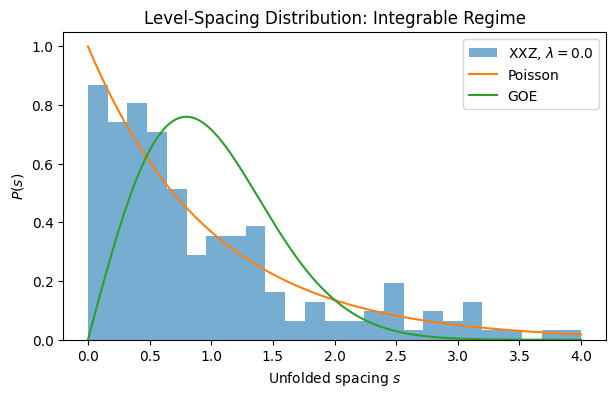

In [298]:
s_grid = np.linspace(
    0.0,
    4.0,
    500
)

plt.figure(
    figsize=(7, 4)
)

plt.hist(
    s_integrable,
    bins=25,
    range=(0, 4),
    density=True,
    alpha=0.6,
    label=rf"XXZ, $\lambda={lambda_integrable}$"
)

plt.plot(
    s_grid,
    poisson_spacing_distribution(s_grid),
    label="Poisson"
)

plt.plot(
    s_grid,
    goe_spacing_distribution(s_grid),
    label="GOE"
)

plt.xlabel(
    r"Unfolded spacing $s$"
)

plt.ylabel(
    r"$P(s)$"
)

plt.title(
    "Level-Spacing Distribution: Integrable Regime"
)

plt.legend()
plt.show()

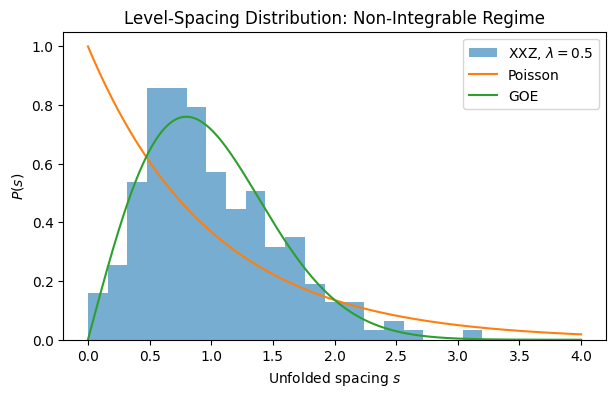

In [299]:
plt.figure(
    figsize=(7, 4)
)

plt.hist(
    s_chaotic,
    bins=25,
    range=(0, 4),
    density=True,
    alpha=0.6,
    label=rf"XXZ, $\lambda={lambda_chaotic}$"
)

plt.plot(
    s_grid,
    poisson_spacing_distribution(s_grid),
    label="Poisson"
)

plt.plot(
    s_grid,
    goe_spacing_distribution(s_grid),
    label="GOE"
)

plt.xlabel(
    r"Unfolded spacing $s$"
)

plt.ylabel(
    r"$P(s)$"
)

plt.title(
    "Level-Spacing Distribution: Non-Integrable Regime"
)

plt.legend()
plt.show()

## 5.10 Integrability-to-Chaos Crossover

Instead of comparing only two values of the perturbation strength, the transition can be studied continuously by varying

$$
\lambda.
$$

For each value of $\lambda$, the procedure is:

1. construct the Hamiltonian in the same magnetization and parity sector;
2. diagonalize the complete symmetry-resolved block;
3. select the same central spectral fraction;
4. calculate the adjacent-gap ratios;
5. evaluate $\langle r\rangle$.

The resulting function

$$
\langle r\rangle(\lambda)
$$

provides a direct numerical picture of the crossover from integrable to chaotic spectral statistics.

The integrable limit is expected near

$$
\langle r\rangle
\approx0.386,
$$

whereas the chaotic regime should approach the GOE value

$$
\langle r\rangle
\approx0.53.
$$

In [300]:
lambda_values = np.linspace(
    0.0,
    1.0,
    50
)

mean_r_values = []

for lam_test in lambda_values:

    H_test = build_parity_hamiltonian(
        L=L,
        N_up=N_up,
        parity=parity,
        Delta=Delta,
        lam=lam_test,
        J=J
    )

    E_test = np.linalg.eigvalsh(H_test.toarray())

    E_test_bulk = select_spectral_bulk(E_test, fraction=0.5)

    r_test = adjacent_gap_ratios(E_test_bulk)

    mean_r = np.mean(r_test)

    mean_r_values.append(mean_r)

    print(
        f"lambda = {lam_test:.2f}"
        f"| <r> = {mean_r:.6f}"
    )

lambda = 0.00| <r> = 0.382502
lambda = 0.02| <r> = 0.379443
lambda = 0.04| <r> = 0.385139
lambda = 0.06| <r> = 0.424150
lambda = 0.08| <r> = 0.394634
lambda = 0.10| <r> = 0.428404
lambda = 0.12| <r> = 0.422336
lambda = 0.14| <r> = 0.421173
lambda = 0.16| <r> = 0.461541
lambda = 0.18| <r> = 0.471705
lambda = 0.20| <r> = 0.452761
lambda = 0.22| <r> = 0.483696
lambda = 0.24| <r> = 0.455597
lambda = 0.27| <r> = 0.454058
lambda = 0.29| <r> = 0.489916
lambda = 0.31| <r> = 0.509988
lambda = 0.33| <r> = 0.491880
lambda = 0.35| <r> = 0.510826
lambda = 0.37| <r> = 0.538826
lambda = 0.39| <r> = 0.557910
lambda = 0.41| <r> = 0.525847
lambda = 0.43| <r> = 0.503764
lambda = 0.45| <r> = 0.514991
lambda = 0.47| <r> = 0.526824
lambda = 0.49| <r> = 0.545664
lambda = 0.51| <r> = 0.544834
lambda = 0.53| <r> = 0.541014
lambda = 0.55| <r> = 0.529271
lambda = 0.57| <r> = 0.540146
lambda = 0.59| <r> = 0.558262
lambda = 0.61| <r> = 0.530470
lambda = 0.63| <r> = 0.556819
lambda = 0.65| <r> = 0.539062
lambda = 0

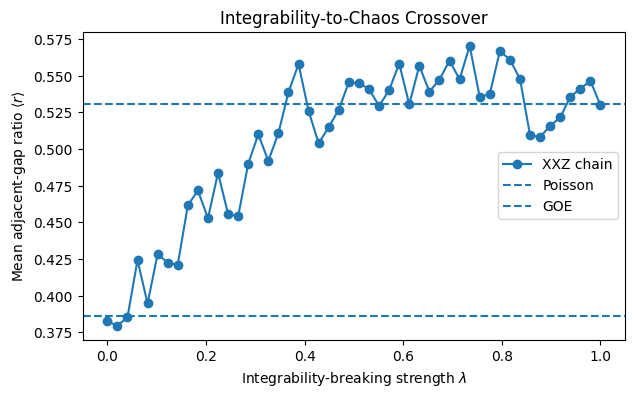

In [301]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    lambda_values,
    mean_r_values,
    "o-",
    label="XXZ chain"
)

plt.axhline(
    r_poisson,
    linestyle="--",
    label="Poisson"
)

plt.axhline(
    r_goe,
    linestyle="--",
    label="GOE"
)

plt.xlabel(
    r"Integrability-breaking strength $\lambda$"
)

plt.ylabel(
    r"Mean adjacent-gap ratio $\langle r\rangle$"
)

plt.title(
    "Integrability-to-Chaos Crossover"
)

plt.legend()
plt.show()

## 5.11 Finite-Size Considerations

Random-matrix predictions describe universal statistical behaviour that becomes increasingly accurate when sufficiently many levels are available.

Exact diagonalization, however, is restricted to finite systems.

Consequently, deviations from the ideal Poisson and GOE values may arise from:

- finite Hilbert-space dimension;
- limited numbers of levels inside a symmetry sector;
- spectral-edge effects;
- incomplete symmetry resolution;
- the chosen spectral window;
- the strength of the integrability-breaking perturbation.

A single system size should therefore not be interpreted as definitive evidence of universal behaviour.

A more robust analysis compares several values of $L$ while keeping the physical symmetry sector as consistent as possible.

For even system sizes, the present strategy will use approximately

$$
N_\uparrow
=
\frac{L}{2}+1,
$$

together with a fixed reflection parity.

The evolution of

$$
\langle r\rangle
$$

with both $L$ and $\lambda$ will later provide a finite-size test of the integrability-to-chaos crossover.

## 5.12 Numerical and Physical Checks

Before interpreting the spectral statistics physically, several consistency conditions should be verified.

The energies must be sorted,

$$
E_{n+1}\geq E_n.
$$

The nearest-neighbour spacings must satisfy

$$
s_n\geq0.
$$

The adjacent-gap ratios must lie within

$$
0\leq r_n\leq1.
$$

All compared spectra must correspond to exactly the same values of

$$
L,
\qquad
N_\uparrow,
\qquad
p,
\qquad
\Delta.
$$

Only the parameter intentionally used to break integrability, $\lambda$, should be varied.

Finally, spectral statistics must never be calculated by combining different symmetry sectors.

In [302]:
assert np.all(
    np.diff(E_integrable) >= -1e-12
)

assert np.all(
    np.diff(E_chaotic) >= -1e-12
)

assert np.all(
    r_integrable >= 0.0
)

assert np.all(
    r_integrable <= 1.0
)

assert np.all(
    r_chaotic >= 0.0
)

assert np.all(
    r_chaotic <= 1.0
)

assert (
    H_integrable.shape
    ==
    H_chaotic.shape
)

print(
    "All basic spectral-statistics checks passed."
)

All basic spectral-statistics checks passed.


## 5.13 Summary of Spectral Statistics

The energy spectrum has now been analysed within a fixed magnetization and reflection-parity sector.

The nearest-neighbour spacings are defined as

$$
s_n
=
E_{n+1}-E_n,
$$

while the symmetrized adjacent-gap ratio is

$$
r_n
=
\frac{
\min(s_n,s_{n+1})
}{
\max(s_n,s_{n+1})
}.
$$

The adjacent-gap ratio provides an especially useful diagnostic because it does not require spectral unfolding.

For integrable systems, Poisson statistics predict

$$
\langle r\rangle
\approx
0.386,
$$

whereas quantum-chaotic systems in the GOE universality class approach

$$
\langle r\rangle
\approx
0.53.
$$

The next-nearest-neighbour coupling $\lambda$ therefore provides a control parameter for studying the crossover

$$
\text{integrable}
\rightarrow
\text{quantum chaotic}.
$$

The spectral analysis developed in this section provides three complementary diagnostics:

$$
\langle r\rangle,
$$

$$
P(r),
$$

and

$$
P(s).
$$

Among these quantities, $\langle r\rangle$ and $P(r)$ will be treated as the primary diagnostics because they avoid the ambiguities associated with spectral unfolding.

The next stage will connect these numerical results more directly with Random Matrix Theory and construct explicit GOE reference ensembles for comparison with the interacting spin-chain spectrum.

## 6 Random Matrix Theory as a Benchmark

Random Matrix Theory provides a universal statistical description of quantum systems whose classical counterparts are chaotic, or more generally of quantum systems exhibiting sufficiently complex non-integrable dynamics.

The central idea is not that the microscopic Hamiltonian of the spin chain is literally random.

Instead, after all relevant symmetries have been resolved, the local statistical correlations between energy levels can become universal and coincide with those generated by appropriate ensembles of random matrices.

The relevant comparison is therefore

$$
\text{microscopic many-body Hamiltonian}
\longrightarrow
\text{universal spectral statistics}.
$$

For the XXZ chain considered in this project, the Hamiltonian can be represented by a real symmetric matrix.

The corresponding random-matrix universality class is the Gaussian Orthogonal Ensemble, or GOE.

The objective of this section is to construct numerical GOE reference spectra and compare their spectral statistics with those obtained from the interacting spin chain.

## 6.1 Gaussian Orthogonal Ensemble

The Gaussian Orthogonal Ensemble consists of real symmetric random matrices,

$$
H_{\mathrm{GOE}}
=
H_{\mathrm{GOE}}^T.
$$

The matrix elements are random Gaussian variables subject to the symmetry condition

$$
H_{ij}=H_{ji}.
$$

A convenient numerical construction begins with a real matrix $A$ whose elements are independent Gaussian random variables,

$$
A_{ij}
\sim
\mathcal{N}(0,1).
$$

A real symmetric matrix can then be constructed as

$$
H_{\mathrm{GOE}}
=
\frac{
A+A^T
}{
\sqrt{2D}
},
$$

where $D$ is the matrix dimension.

The normalization by $\sqrt{D}$ ensures that the spectral width remains finite as the matrix dimension increases.

With this convention, the eigenvalue density approaches the Wigner semicircle distribution in the large-$D$ limit.

In [303]:
def generate_goe_matrix(
        D: int,
        rng: np.random.Generator
) -> np.ndarray:

    A = rng.normal(
        loc=0.0,
        scale = 1.0,
        size=(D,D)
    )

    H_goe = (
        (A + A.T)/np.sqrt(2*D)
    )

    return H_goe

In [304]:
rng = np.random.default_rng(
    12345
)

D_goe = 300

H_goe = generate_goe_matrix(
    D=D_goe,
    rng=rng
)

print("GOE dimension: ", H_goe.shape)

print("Real matrix: ", np.isrealobj(H_goe))

print("Symmetric: ", np.allclose(H_goe, H_goe.T))

GOE dimension:  (300, 300)
Real matrix:  True
Symmetric:  True


## 6.2 Energy Spectrum of a GOE Matrix

A GOE matrix has a completely different microscopic origin from the XXZ Hamiltonian.

Nevertheless, its eigenvalue correlations provide the universal reference expected for a time-reversal-invariant chaotic quantum system.

The eigenvalue problem is

$$
H_{\mathrm{GOE}}|\psi_n\rangle
=
E_n|\psi_n\rangle.
$$

Because $H_{\mathrm{GOE}}$ is real and symmetric, all eigenvalues are real.

As in the many-body problem, the eigenvalues are ordered as

$$
E_1
\leq
E_2
\leq
\cdots
\leq
E_D.
$$

In [305]:
E_goe = np.linalg.eigvalsh(H_goe)

print(
    "Number of eigenvalues: ",
    len(E_goe)
)

print(
    "Minimum energy: ",
    E_goe[0]
)

print(
    "Maximum energy: ",
    E_goe[len(E_goe) - 1]
)


Number of eigenvalues:  300
Minimum energy:  -1.9640134719085054
Maximum energy:  1.9672143346924755


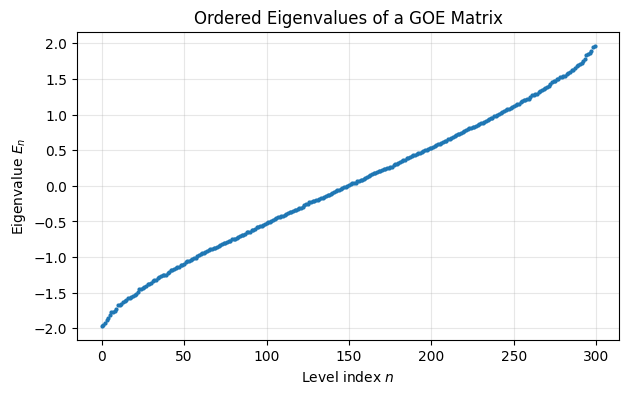

In [306]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    np.arange(len(E_goe)),
    E_goe,
    ".",
    markersize=4
)

plt.xlabel(
    r"Level index $n$"
)

plt.ylabel(
    r"Eigenvalue $E_n$"
)

plt.title(
    "Ordered Eigenvalues of a GOE Matrix"
)

plt.grid(
    alpha=0.3
)

plt.show()

## 6.3 Wigner Semicircle Law

For large GOE matrices, the average density of eigenvalues approaches the Wigner semicircle distribution.

With the normalization adopted here, the limiting density is

$$
\rho(E)
=
\frac{1}{2\pi}
\sqrt{
4-E^2
},
$$

for

$$
|E|\leq2,
$$

and

$$
\rho(E)=0
$$

outside this interval.

The semicircle law describes the global density of states of the random-matrix ensemble.

It should not be confused with the local spectral correlations used to diagnose quantum chaos.

The global density

$$
\rho(E)
$$

and the local level-spacing statistics contain different information.

In [307]:
def wigner_semicircle(
    E: np.ndarray
) -> np.ndarray:

    rho = np.zeros_like(
        E,
        dtype=float
    )

    mask = np.abs(E) <= 2.0

    rho[mask] = (
        1.0
        /
        (2.0 * np.pi)
        *
        np.sqrt(
            4.0
            -
            E[mask]**2
        )
    )

    return rho

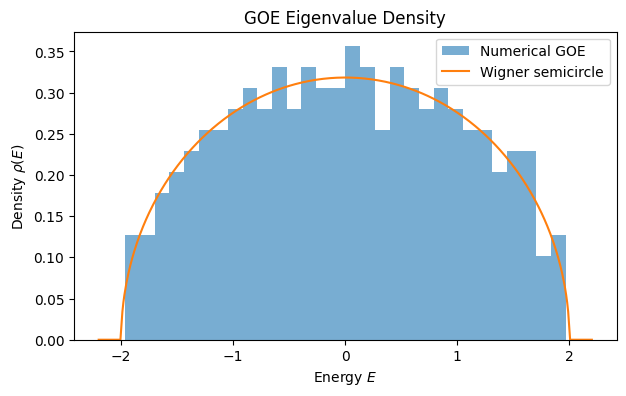

In [308]:
E_grid = np.linspace(
    -2.2,
    2.2,
    500
)

plt.figure(
    figsize=(7, 4)
)

plt.hist(
    E_goe,
    bins=30,
    density=True,
    alpha=0.6,
    label="Numerical GOE"
)

plt.plot(
    E_grid,
    wigner_semicircle(E_grid),
    label="Wigner semicircle"
)

plt.xlabel(
    r"Energy $E$"
)

plt.ylabel(
    r"Density $\rho(E)$"
)

plt.title(
    "GOE Eigenvalue Density"
)

plt.legend()

plt.show()

### Global Spectral Density

The GOE eigenvalue histogram approaches the Wigner semicircle distribution.

For a finite matrix, deviations are expected because the semicircle law is an asymptotic result.

This comparison concerns the global density of states.

The quantum-chaos diagnostics considered in the previous section instead probe local correlations between neighbouring energy levels.

## 6.4 Adjacent-Gap Statistics of the GOE

To compare Random Matrix Theory directly with the interacting spin chain, the same spectral statistic must be applied to both systems.

For an ordered GOE spectrum, define

$$
s_n
=
E_{n+1}-E_n,
$$

and

$$
r_n
=
\frac{
\min(s_n,s_{n+1})
}{
\max(s_n,s_{n+1})
}.
$$

The GOE is characterized by strong level repulsion and a mean adjacent-gap ratio close to

$$
\langle r\rangle_{\mathrm{GOE}}
\approx
0.53.
$$

Unlike the unfolded nearest-neighbour spacing distribution, the adjacent-gap ratio can be evaluated directly from the raw spectrum.

To reduce edge effects, only the central part of the GOE spectrum will be used.

In [309]:
E_goe_bulk = select_spectral_bulk(E_goe, fraction=0.5)

r_goe_numerical = adjacent_gap_ratios(E_goe_bulk)

mean_r_goe_numerical = np.mean(r_goe_numerical)

print(
    "Numerical GOE <r>: ",
    mean_r_goe_numerical
)

print(
    "Reference value of <r>: ",
    0.5307
)

Numerical GOE <r>:  0.5185300191617802
Reference value of <r>:  0.5307


## 6.5 Ensemble Averaging

A single random matrix represents only one realization of the GOE.

Random Matrix Theory makes statistical predictions for an ensemble of matrices.

Therefore, a more reliable numerical benchmark is obtained by generating several independent GOE realizations and combining their adjacent-gap ratios.

For each realization,

$$
H_{\mathrm{GOE}}^{(\alpha)},
$$

we calculate a symmetry-independent spectrum and retain the same central spectral fraction.

The complete GOE reference sample is then constructed as

$$
\{r\}_{\mathrm{GOE}}
=
\bigcup_\alpha
\{r\}_\alpha.
$$

This procedure reduces statistical fluctuations and provides a more stable numerical estimate of

$$
\langle r\rangle_{\mathrm{GOE}}.
$$

In [310]:
def generate_goe_gap_ratios(
        D:int, 
        n_realizations: int,
        bulk_fraction: float = 0.5,
        seed: int = 12345
) -> np.ndarray:

    rng = np.random.default_rng(seed)

    all_ratios = []

    for _ in range(n_realizations):

        H = generate_goe_matrix(
            D=D,
            rng=rng
        )

        energies = np.linalg.eigvalsh(H)

        energies_bulk = select_spectral_bulk(energies, fraction=bulk_fraction)

        ratios = adjacent_gap_ratios(energies_bulk)

        all_ratios.append(ratios)

    return np.concatenate(all_ratios)


In [311]:
goe_ratios = generate_goe_gap_ratios(
    D=250,
    n_realizations=10,
    bulk_fraction=0.5,
    seed=12345
)

print(
    "Number of GOE ratios: ",
    len(goe_ratios)
)

print(
    "Ensemble <r>: ",
    np.mean(goe_ratios)
)

Number of GOE ratios:  1230
Ensemble <r>:  0.5357486431946875


## 6.6 Numerical GOE Distribution of Adjacent-Gap Ratios

The complete distribution

$$
P(r)
$$

contains more information than the mean value alone.

The numerical GOE ensemble can therefore be compared with the analytical random-matrix surmise introduced previously.

For the GOE, a useful approximation is

$$
P_{\mathrm{GOE}}(r)
=
\frac{27}{4}
\frac{
r+r^2
}{
(1+r+r^2)^{5/2}
},
$$

with

$$
0\leq r\leq1.
$$

Agreement between the numerical random matrices and this theoretical curve provides an independent validation of the spectral-statistics implementation.

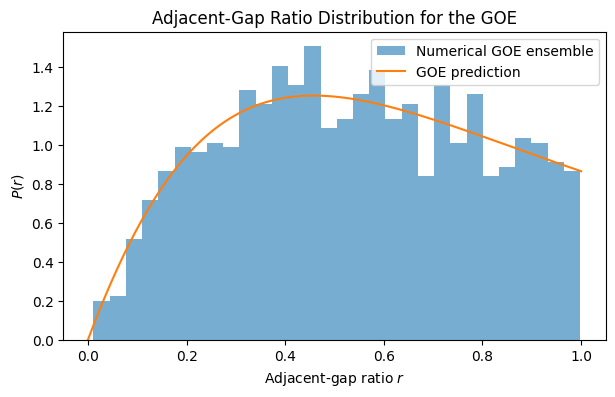

In [312]:
r_grid = np.linspace(
    0.0,
    1.0,
    500
)

plt.figure(figsize=(7,4))

plt.hist(
    goe_ratios,
    bins = 30,
    density=True,
    alpha=0.6,
    label="Numerical GOE ensemble"
)

plt.plot(
    r_grid,
    goe_ratio_distribution(r_grid),
    label="GOE prediction"
)

plt.xlabel(
    r"Adjacent-gap ratio $r$"
)

plt.ylabel(
    r"$P(r)$"
)

plt.title(
    "Adjacent-Gap Ratio Distribution for the GOE"
)

plt.legend()
plt.show()

## 6.7 Numerical Poisson Benchmark

A complementary numerical benchmark can be constructed for an uncorrelated spectrum.

For a Poisson process, the nearest-neighbour spacings are independently distributed according to

$$
P(s)
=
e^{-s}.
$$

A synthetic Poisson spectrum can therefore be generated by drawing independent exponential spacings,

$$
s_n
\sim
\mathrm{Exp}(1),
$$

and constructing cumulative energy levels,

$$
E_n
=
\sum_{j<n}s_j.
$$

This produces a reference spectrum with no level repulsion.

Its adjacent-gap statistics should approach

$$
\langle r\rangle_{\mathrm{Poisson}}
=
2\ln2-1
\approx
0.3863.
$$

In [313]:
def generate_poisson_spectrum(
    N: int,
    rng: np.random.Generator
) -> np.ndarray:

    spacings = rng.exponential(
        scale=1.0,
        size=N - 1
    )

    energies = np.concatenate([
        [0.0],
        np.cumsum(spacings)
    ])

    return energies

In [314]:
rng_poisson = np.random.default_rng(
    54321
)

E_poisson = generate_poisson_spectrum(
    N=5000,
    rng=rng_poisson
)

r_poisson_numerical = adjacent_gap_ratios(
    E_poisson
)

print(
    "Numerical Poisson <r>:",
    np.mean(r_poisson_numerical)
)

print(
    "Analytical Poisson <r>:",
    2.0 * np.log(2.0) - 1.0
)

Numerical Poisson <r>: 0.3893492295314692
Analytical Poisson <r>: 0.3862943611198906


## 6.9 Poisson versus GOE Reference Statistics

The two universal reference limits can now be compared directly.

For uncorrelated Poisson levels,

$$
\langle r\rangle
\approx
0.386,
$$

whereas the GOE produces

$$
\langle r\rangle
\approx
0.53.
$$

The difference originates from level repulsion.

In the Poisson case, neighbouring energy levels can approach each other arbitrarily closely.

In the GOE, spectral correlations suppress near-degenerate neighbouring levels.

These two limits provide the reference framework for interpreting the XXZ spectrum.

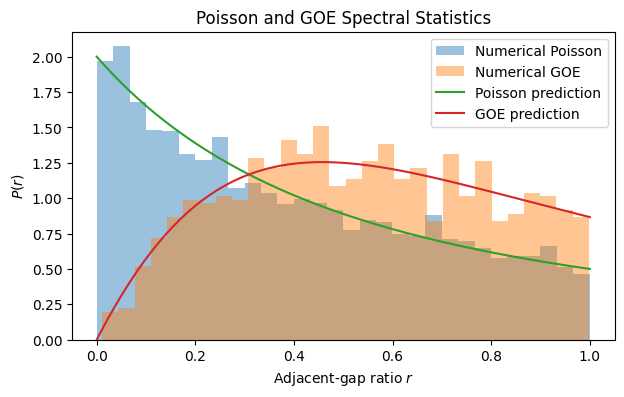

In [315]:
plt.figure(
    figsize=(7, 4)
)

plt.hist(
    r_poisson_numerical,
    bins=30,
    density=True,
    alpha=0.45,
    label="Numerical Poisson"
)

plt.hist(
    goe_ratios,
    bins=30,
    density=True,
    alpha=0.45,
    label="Numerical GOE"
)

plt.plot(
    r_grid,
    poisson_ratio_distribution(
        r_grid
    ),
    label="Poisson prediction"
)

plt.plot(
    r_grid,
    goe_ratio_distribution(
        r_grid
    ),
    label="GOE prediction"
)

plt.xlabel(
    r"Adjacent-gap ratio $r$"
)

plt.ylabel(
    r"$P(r)$"
)

plt.title(
    "Poisson and GOE Spectral Statistics"
)

plt.legend()

plt.show()

## 6.9 Direct Comparison with the XXZ Chain

The numerical random-matrix benchmarks can now be compared directly with the symmetry-resolved XXZ spectra.

Three physically distinct cases are considered:

$$
\text{Poisson reference},
$$

$$
\text{integrable XXZ},
$$

and

$$
\text{non-integrable XXZ},
$$

together with the GOE reference ensemble.

The expected correspondence is

$$
\text{integrable XXZ}
\longleftrightarrow
\text{Poisson},
$$

and

$$
\text{chaotic XXZ}
\longleftrightarrow
\text{GOE}.
$$

The comparison concerns universal spectral correlations rather than the absolute values or global distributions of the energy eigenvalues.

In [316]:
print(
    f"{'System':<25}"
    f"{'<r>':>12}"
)

print(
    "-" * 37
)

print(
    f"{'Poisson reference':<25}"
    f"{np.mean(r_poisson_numerical):12.6f}"
)

print(
    f"{'Integrable XXZ':<25}"
    f"{np.mean(r_integrable):12.6f}"
)

print(
    f"{'Chaotic XXZ':<25}"
    f"{np.mean(r_chaotic):12.6f}"
)

print(
    f"{'GOE reference':<25}"
    f"{np.mean(goe_ratios):12.6f}"
)

System                            <r>
-------------------------------------
Poisson reference            0.389349
Integrable XXZ               0.382502
Chaotic XXZ                  0.562264
GOE reference                0.535749


## 6.10 Graphical comparison of $P(r)$

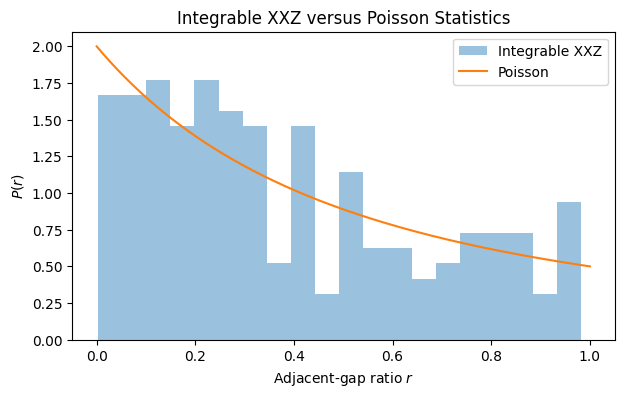

In [317]:
plt.figure(
    figsize=(7, 4)
)

plt.hist(
    r_integrable,
    bins=20,
    density=True,
    alpha=0.45,
    label="Integrable XXZ"
)

plt.plot(
    r_grid,
    poisson_ratio_distribution(
        r_grid
    ),
    label="Poisson"
)

plt.xlabel(
    r"Adjacent-gap ratio $r$"
)

plt.ylabel(
    r"$P(r)$"
)

plt.title(
    "Integrable XXZ versus Poisson Statistics"
)

plt.legend()

plt.show()

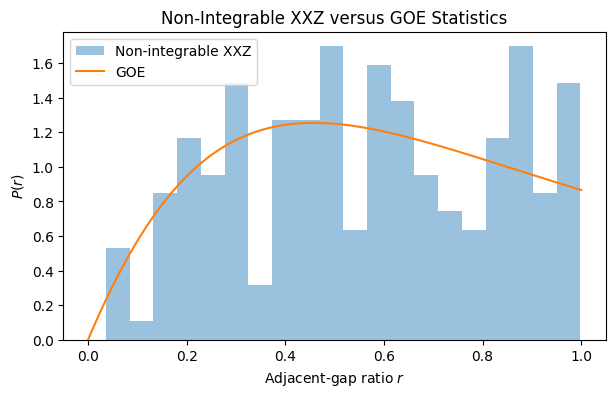

In [318]:
plt.figure(
    figsize=(7, 4)
)

plt.hist(
    r_chaotic,
    bins=20,
    density=True,
    alpha=0.45,
    label="Non-integrable XXZ"
)

plt.plot(
    r_grid,
    goe_ratio_distribution(
        r_grid
    ),
    label="GOE"
)

plt.xlabel(
    r"Adjacent-gap ratio $r$"
)

plt.ylabel(
    r"$P(r)$"
)

plt.title(
    "Non-Integrable XXZ versus GOE Statistics"
)

plt.legend()

plt.show()

## 6.11 Finite-Size Convergence of the GOE Benchmark

Random Matrix Theory predictions correspond to an ensemble and, strictly, to an asymptotic large-matrix limit.

Finite GOE matrices therefore exhibit statistical fluctuations.

To verify the stability of the numerical reference, the mean adjacent-gap ratio can be evaluated for increasing random-matrix dimension,

$$
D_{\mathrm{GOE}}.
$$

The result should approach a dimension-independent value close to the universal GOE prediction.

This calculation also distinguishes finite-size effects intrinsic to Random Matrix Theory from finite-size effects associated with the interacting spin chain.

In [319]:
goe_dimension = [
    50,
    100,
    150,
    200,
    300
]

mean_r_by_dimension = []

for D_test in goe_dimension:

    ratios = generate_goe_gap_ratios(
        D=D_test,
        n_realizations=8,
        bulk_fraction=0.5,
        seed=12345
    )

    mean_r_test = np.mean(ratios)

    mean_r_by_dimension.append(mean_r_test)

    print(
        f"D = {D_test:4d}"
        f"| <r> = {mean_r_test:.6f}"
    )

D =   50| <r> = 0.540363
D =  100| <r> = 0.523182
D =  150| <r> = 0.540408
D =  200| <r> = 0.531561
D =  300| <r> = 0.534223


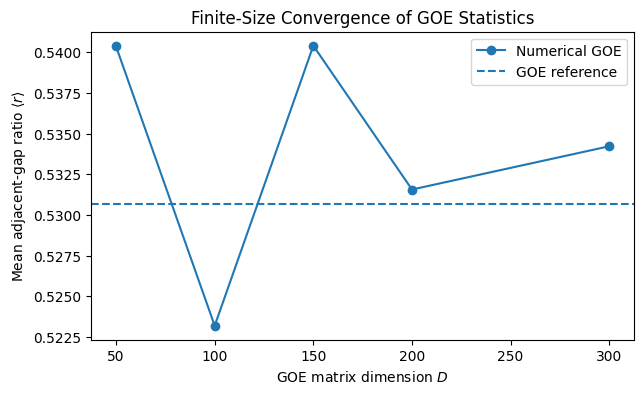

In [320]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    goe_dimension,
    mean_r_by_dimension,
    "o-",
    label="Numerical GOE"
)

plt.axhline(
    0.5307,
    linestyle="--",
    label="GOE reference"
)

plt.xlabel(
    r"GOE matrix dimension $D$"
)

plt.ylabel(
    r"Mean adjacent-gap ratio $\langle r\rangle$"
)

plt.title(
    "Finite-Size Convergence of GOE Statistics"
)

plt.legend()

plt.show()

## 6.13 What Random Matrix Theory Does Not Predict

Random Matrix Theory describes universal spectral correlations, but it does not reproduce the microscopic structure of the XXZ Hamiltonian.

The XXZ model contains local interactions, conserved quantities, spatial structure, and physically meaningful parameters such as

$$
J,
\qquad
\Delta,
\qquad
\lambda.
$$

A GOE matrix contains none of this microscopic information.

Consequently, the comparison

$$
\text{XXZ}
\leftrightarrow
\text{GOE}
$$

should not be interpreted as an equality between Hamiltonians.

Instead, the correspondence concerns statistical properties of the symmetry-resolved spectrum.

In particular,

$$
P(r),
$$

$$
\langle r\rangle,
$$

and unfolded level-spacing distributions can display universal GOE behaviour even though the underlying Hamiltonian remains highly structured and local.

Random Matrix Theory therefore provides a universal statistical benchmark rather than a microscopic model of the spin chain.

## 6.14 Summary of the Random-Matrix Benchmark

The Gaussian Orthogonal Ensemble has been introduced as the random-matrix reference appropriate to the real symmetric XXZ Hamiltonian.

GOE matrices satisfy

$$
H_{\mathrm{GOE}}
=
H_{\mathrm{GOE}}^T
$$

and display strong spectral correlations associated with level repulsion.

The global eigenvalue density approaches the Wigner semicircle law,

$$
\rho(E)
=
\frac{1}{2\pi}
\sqrt{
4-E^2
}.
$$

More importantly for the present project, the local spectral statistics approach

$$
\langle r\rangle_{\mathrm{GOE}}
\approx
0.53.
$$

A complementary Poisson benchmark was generated from independent exponential spacings, producing

$$
\langle r\rangle_{\mathrm{Poisson}}
\approx
0.386.
$$

These two statistical limits provide the reference framework

$$
\text{Poisson}
\longleftrightarrow
\text{integrable},
$$

and

$$
\text{GOE}
\longleftrightarrow
\text{quantum chaotic}.
$$

The interacting XXZ chain can therefore be classified statistically by comparing its symmetry-resolved spectrum with these universal reference ensembles.

The progression of the project is now

$$
\text{XXZ Hamiltonian}
\rightarrow
\text{symmetry resolution}
\rightarrow
\text{spectral statistics}
\rightarrow
\text{Random Matrix Theory}.
$$

The next stage will study the integrability-to-chaos crossover in greater detail as a function of the interaction strength, system size, and spectral position.

# 7. Integrability-to-Chaos Crossover and Finite-Size Scaling

The previous sections established the statistical signatures of integrability and quantum chaos.

For an integrable spectrum, the adjacent-gap ratio approaches the Poisson value

$$
\langle r\rangle_{\mathrm{P}}
\approx
0.386,
$$

whereas chaotic spectra in the GOE universality class approach

$$
\langle r\rangle_{\mathrm{GOE}}
\approx
0.53.
$$

The next-nearest-neighbour coupling $\lambda$ provides a continuous control parameter between these two regimes.

Rather than comparing only isolated values of $\lambda$, we now study the function

$$
\langle r\rangle(\lambda,L),
$$

where $L$ is the system size.

This allows us to investigate both the integrability-to-chaos crossover and its dependence on finite Hilbert-space dimension.

For each value of $L$, the spectral analysis will be performed inside a fixed magnetization and reflection-parity sector.

To avoid the additional spin-inversion symmetry present at half filling, we choose

$$
N_\uparrow
=
\frac{L}{2}+1
$$

for even $L$.

The numerical protocol is therefore

$$
(L,\lambda)
\rightarrow
H_{N_\uparrow,p}
\rightarrow
\{E_n\}
\rightarrow
\text{spectral bulk}
\rightarrow
\{r_n\}
\rightarrow
\langle r\rangle.
$$

## 7.1 Numerical Protocol

A meaningful comparison between different values of $\lambda$ requires all other physical and numerical parameters to remain fixed.

For a given system size $L$, we use

$$
N_\uparrow
=
\frac{L}{2}+1,
$$

a fixed reflection parity $p$, and a fixed anisotropy $\Delta$.

Only the integrability-breaking parameter

$$
\lambda
$$

is varied.

The same central fraction of the spectrum is retained for every calculation in order to reduce spectral-edge effects.

The primary observable is

$$
\langle r\rangle
=
\frac{1}{N_r}
\sum_n r_n.
$$

This quantity does not require unfolding and is therefore particularly suitable for systematic parameter scans.

In [321]:
def mean_gap_ratio_for_parameters(
        L: int,
        N_up: int,
        parity: int,
        Delta: float,
        lam: float,
        J: float = 1.0,
        bulk_fraction: float = 0.5
) -> tuple[float,int]:

    H = build_parity_hamiltonian(
        L=L,
        N_up=N_up,
        parity=parity,
        Delta=Delta,
        lam=lam,
        J=J
    )

    dimension = H.shape[0]

    energies = np.linalg.eigvalsh(H.toarray())

    energies_bulk = select_spectral_bulk(
        energies, fraction=bulk_fraction
    )

    ratios = adjacent_gap_ratios(energies_bulk)

    mean_r = np.mean(ratios)

    return mean_r, dimension

## 7.2 Mean Gap Ratio as a Function of the Integrability-Breaking Parameter

We first study the crossover for a single system size.

The integrable limit corresponds to

$$
\lambda=0.
$$

As $\lambda$ increases, the next-nearest-neighbour interaction competes with the nearest-neighbour XXZ Hamiltonian and breaks integrability.

The spectral correlations are therefore expected to evolve from approximately Poisson statistics toward GOE-like behaviour.

The quantity

$$
\langle r\rangle(\lambda)
$$

provides a compact representation of this crossover.

In [322]:
L_scan = 12

N_up_scan = (
    L_scan // 2
    + 1
)

parity_scan = +1

Delta_scan = 0.7
J_scan = 1.0

bulk_fraction = 0.5

lambda_values = np.linspace(
    0.0,
    1.0,
    50
)

mean_r_lambda = []

for lam_test in lambda_values:

    mean_r, dimension = mean_gap_ratio_for_parameters(
        L=L_scan,
        N_up=N_up_scan,
        parity=parity_scan,
        Delta=Delta_scan,
        lam=lam_test,
        J=J_scan,
        bulk_fraction=bulk_fraction
    )

    mean_r_lambda.append(
        mean_r
    )

    print(
        f"lambda = {lam_test:5.2f}"
        f" | D = {dimension:5d}"
        f" | <r> = {mean_r:.6f}"
    )

lambda =  0.00 | D =   396 | <r> = 0.382502
lambda =  0.02 | D =   396 | <r> = 0.379443
lambda =  0.04 | D =   396 | <r> = 0.385139
lambda =  0.06 | D =   396 | <r> = 0.424150
lambda =  0.08 | D =   396 | <r> = 0.394634
lambda =  0.10 | D =   396 | <r> = 0.428404
lambda =  0.12 | D =   396 | <r> = 0.422336
lambda =  0.14 | D =   396 | <r> = 0.421173
lambda =  0.16 | D =   396 | <r> = 0.461541
lambda =  0.18 | D =   396 | <r> = 0.471705
lambda =  0.20 | D =   396 | <r> = 0.452761
lambda =  0.22 | D =   396 | <r> = 0.483696
lambda =  0.24 | D =   396 | <r> = 0.455597
lambda =  0.27 | D =   396 | <r> = 0.454058
lambda =  0.29 | D =   396 | <r> = 0.489916
lambda =  0.31 | D =   396 | <r> = 0.509988
lambda =  0.33 | D =   396 | <r> = 0.491880
lambda =  0.35 | D =   396 | <r> = 0.510826
lambda =  0.37 | D =   396 | <r> = 0.538826
lambda =  0.39 | D =   396 | <r> = 0.557910
lambda =  0.41 | D =   396 | <r> = 0.525847
lambda =  0.43 | D =   396 | <r> = 0.503764
lambda =  0.45 | D =   396 | <r>

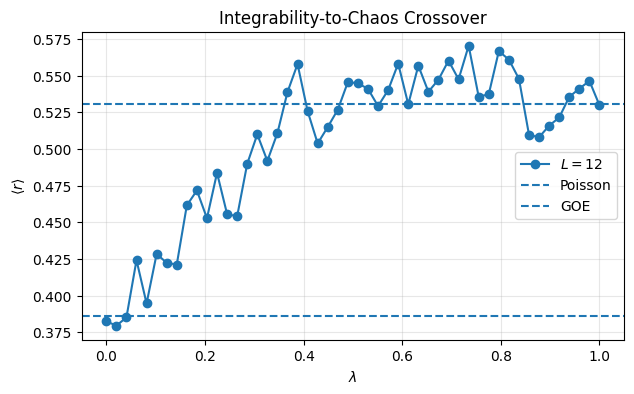

In [323]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    lambda_values,
    mean_r_lambda,
    "o-",
    label=rf"$L={L_scan}$"
)

plt.axhline(
    r_poisson,
    linestyle="--",
    label="Poisson"
)

plt.axhline(
    r_goe,
    linestyle="--",
    label="GOE"
)

plt.xlabel(
    r"$\lambda$"
)

plt.ylabel(
    r"$\langle r\rangle$"
)

plt.title(
    "Integrability-to-Chaos Crossover"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

### Single-Size Crossover

The adjacent-gap ratio evolves away from the Poisson reference as the next-nearest-neighbour interaction is introduced.

The integrable point

$$
\lambda=0
$$

should remain close to

$$
\langle r\rangle_{\mathrm{P}}
\approx0.386,
$$

while an intermediate non-integrable regime is expected to approach

$$
\langle r\rangle_{\mathrm{GOE}}
\approx0.53.
$$

Finite-size fluctuations prevent exact agreement with either universal value.

It is therefore more informative to analyse how the complete crossover changes with increasing system size.

## 7.4 Finite-Size Scan

A quantum-chaos diagnostic should become more robust as the Hilbert-space dimension increases.

We therefore repeat the $\lambda$ scan for several system sizes.

For every even $L$, the magnetization sector is chosen as

$$
N_\uparrow
=
\frac{L}{2}+1.
$$

This keeps the system close to the largest magnetization sector while avoiding half filling.

We begin with the moderate system sizes

$$
L=8,10,12.
$$

If computational resources permit, the calculation can later be extended to

$$
L=14.
$$

The number of parity-resolved levels grows rapidly with $L$, so larger systems provide better spectral statistics but require substantially more diagonalization time.

In [324]:
system_sizes = [
    8,
    10,
    12,
    14
]

lambda_values_finite = np.linspace(
    0.0,
    1.0,
    25
)

parity_fixed = +1
Delta_fixed = 0.7
bulk_fraction_fixed = 0.5

finite_size_results = {}

for L_test in system_sizes:

    N_up_test = (
        L_test // 2
        + 1
    )

    mean_r_values = []

    print()
    print(
        f"System size L = {L_test}"
    )

    for lam_test in lambda_values_finite:

        mean_r, dimension = mean_gap_ratio_for_parameters(
            L=L_test,
            N_up=N_up_test,
            parity=parity_fixed,
            Delta=Delta_fixed,
            lam=lam_test,
            J=1.0,
            bulk_fraction=bulk_fraction_fixed
        )

        mean_r_values.append(
            mean_r
        )

        print(
            f"lambda = {lam_test:.2f}"
            f" | D = {dimension:5d}"
            f" | <r> = {mean_r:.6f}"
        )

    finite_size_results[
        L_test
    ] = np.asarray(
        mean_r_values
    )


System size L = 8
lambda = 0.00 | D =    28 | <r> = 0.457779
lambda = 0.04 | D =    28 | <r> = 0.424453
lambda = 0.08 | D =    28 | <r> = 0.448582
lambda = 0.12 | D =    28 | <r> = 0.548750
lambda = 0.17 | D =    28 | <r> = 0.491066
lambda = 0.21 | D =    28 | <r> = 0.296924
lambda = 0.25 | D =    28 | <r> = 0.392908
lambda = 0.29 | D =    28 | <r> = 0.369561
lambda = 0.33 | D =    28 | <r> = 0.568782
lambda = 0.38 | D =    28 | <r> = 0.525064
lambda = 0.42 | D =    28 | <r> = 0.467094
lambda = 0.46 | D =    28 | <r> = 0.515160
lambda = 0.50 | D =    28 | <r> = 0.489132
lambda = 0.54 | D =    28 | <r> = 0.362550
lambda = 0.58 | D =    28 | <r> = 0.362121
lambda = 0.62 | D =    28 | <r> = 0.352997
lambda = 0.67 | D =    28 | <r> = 0.386493
lambda = 0.71 | D =    28 | <r> = 0.471780
lambda = 0.75 | D =    28 | <r> = 0.569441
lambda = 0.79 | D =    28 | <r> = 0.579684
lambda = 0.83 | D =    28 | <r> = 0.606247
lambda = 0.88 | D =    28 | <r> = 0.575702
lambda = 0.92 | D =    28 | <r> = 0

## 7.5 Comparison between Different System Sizes

The curves

$$
\langle r\rangle(\lambda,L)
$$

can now be compared directly.

If the crossover reflects genuine many-body chaos rather than a small-system artefact, the non-integrable regime should become progressively closer to the GOE prediction as the system size increases.

At the same time, the exactly integrable point

$$
\lambda=0
$$

should remain associated with Poisson-like statistics.

Finite systems may display substantial fluctuations, particularly for the smallest values of $L$.

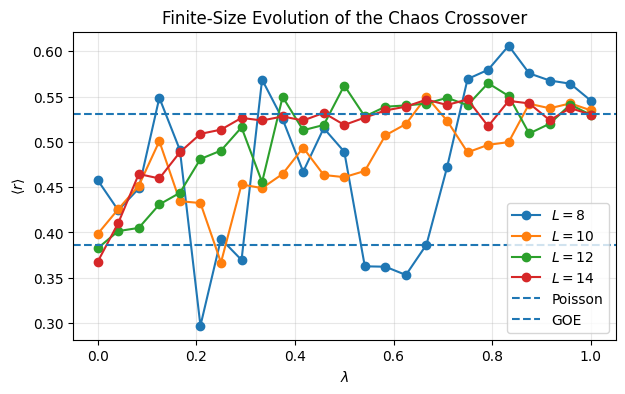

In [325]:
plt.figure(
    figsize=(7, 4)
)

for L_test in system_sizes:

    plt.plot(
        lambda_values_finite,
        finite_size_results[L_test],
        "o-",
        label=rf"$L={L_test}$"
    )

plt.axhline(
    r_poisson,
    linestyle="--",
    label="Poisson"
)

plt.axhline(
    r_goe,
    linestyle="--",
    label="GOE"
)

plt.xlabel(
    r"$\lambda$"
)

plt.ylabel(
    r"$\langle r\rangle$"
)

plt.title(
    "Finite-Size Evolution of the Chaos Crossover"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

## 7.6 Two-Dimensional Crossover Map

The finite-size data define a two-dimensional function,

$$
\langle r\rangle
=
\langle r\rangle(L,\lambda).
$$

A compact visualization can therefore be obtained by representing the mean adjacent-gap ratio as a function of both system size and integrability-breaking strength.

This provides a global picture of the region in parameter space where the spectrum approaches Poisson or GOE statistics.

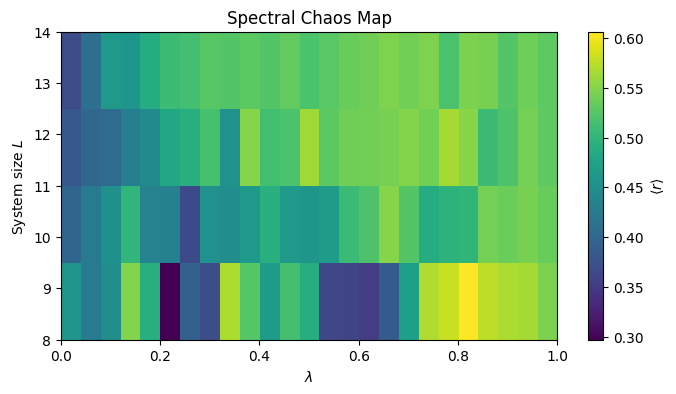

In [326]:
r_matrix = np.array([
    finite_size_results[L_test]
    for L_test in system_sizes
])

plt.figure(figsize=(8,4))

image = plt.imshow(
    r_matrix,
    aspect="auto",
    origin="lower",
    extent=[
        lambda_values_finite[0],
        lambda_values_finite[-1],
        system_sizes[0],
        system_sizes[-1]
    ]
)

plt.colorbar(
    image, label = r"$\langle r \rangle$"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"System size $L$")

plt.title("Spectral Chaos Map")

plt.show()

## 7.7 Operational Estimate of a Crossover Scale

For a finite system, the transition from Poisson-like to GOE-like statistics is a smooth crossover rather than a sharp transition.

An operational crossover scale can nevertheless be defined.

A simple choice is the midpoint

$$
r_{\mathrm{mid}}
=
\frac{
\langle r\rangle_{\mathrm{P}}
+
\langle r\rangle_{\mathrm{GOE}}
}{2}.
$$

We may define $\lambda_*(L)$ as the smallest value of $\lambda$ for which

$$
\langle r\rangle(\lambda,L)
\geq
r_{\mathrm{mid}}.
$$

This definition is not universal and should not be interpreted as a critical point.

It provides only a convenient quantitative measure of how the finite-size crossover evolves with $L$.

In [327]:
r_mid = (
    r_poisson
    +
    r_goe
) / 2.0

print(
    "Midpoint criterion:",
    r_mid
)

lambda_star = {}

for L_test in system_sizes:

    values = finite_size_results[
        L_test
    ]

    indices = np.where(
        values >= r_mid
    )[0]

    if len(indices) > 0:

        lambda_star[
            L_test
        ] = lambda_values_finite[
            indices[0]
        ]

    else:

        lambda_star[
            L_test
        ] = np.nan

    print(
        f"L = {L_test}"
        f" | lambda* = "
        f"{lambda_star[L_test]}"
    )

Midpoint criterion: 0.45849718055994526
L = 8 | lambda* = 0.125
L = 10 | lambda* = 0.125
L = 12 | lambda* = 0.20833333333333331
L = 14 | lambda* = 0.08333333333333333


## 7.8 Robustness against the Spectral Window

The mean adjacent-gap ratio is evaluated using only a central fraction of the spectrum.

Although this suppresses spectral-edge effects, the precise choice of bulk fraction is not unique.

A robust conclusion should therefore not depend strongly on small variations of the selected window.

We compare several central fractions,

$$
f_{\mathrm{bulk}}
=
0.3,\ 0.5,\ 0.7.
$$

Large variations would indicate that the finite system is not yet displaying uniform spectral statistics across the spectral bulk.

In [328]:
L_window = 12

N_up_window = (
    L_window // 2
    + 1
)

lambda_window = 0.5

bulk_fractions = [
    0.3,
    0.5,
    0.7
]

for fraction in bulk_fractions:

    mean_r, dimension = mean_gap_ratio_for_parameters(
        L=L_window,
        N_up=N_up_window,
        parity=+1,
        Delta=0.7,
        lam=lambda_window,
        J=1.0,
        bulk_fraction=fraction
    )

    print(
        f"bulk fraction = {fraction:.1f}"
        f" | <r> = {mean_r:.6f}"
    )

bulk fraction = 0.3 | <r> = 0.572675
bulk fraction = 0.5 | <r> = 0.562264
bulk fraction = 0.7 | <r> = 0.565953


## 7.9 Consistency between Reflection-Parity Sectors

The two reflection-parity sectors,

$$
p=+1
$$

and

$$
p=-1,
$$

are statistically independent.

They must never be mixed when calculating level statistics.

However, in a generic chaotic regime both sectors are expected to display the same GOE universality class.

Therefore, their values of

$$
\langle r\rangle
$$

should become statistically similar when sufficiently many levels are available.

This provides an additional physical consistency check.

In [329]:
L_parity = 12

N_up_parity = (
    L_parity // 2
    + 1
)

lambda_parity = 0.5

for parity_test in (+1, -1):

    mean_r, dimension = mean_gap_ratio_for_parameters(
        L=L_parity,
        N_up=N_up_parity,
        parity=parity_test,
        Delta=0.7,
        lam=lambda_parity,
        J=1.0,
        bulk_fraction=0.5
    )

    print(
        f"parity = {parity_test:+d}"
        f" | D = {dimension}"
        f" | <r> = {mean_r:.6f}"
    )

parity = +1 | D = 396 | <r> = 0.562264
parity = -1 | D = 396 | <r> = 0.561395


## 7.10 Physical Interpretation of the Crossover

The integrability-to-chaos crossover reflects the progressive destruction of the special structure responsible for the exact solvability of the nearest-neighbour XXZ chain.

At

$$
\lambda=0,
$$

the system is integrable and possesses an extensive set of conserved quantities.

Its energy levels are therefore expected to display approximately Poisson statistics.

When the next-nearest-neighbour interaction is introduced,

$$
\lambda>0,
$$

the integrable structure is generically broken.

States that were previously constrained by integrability become increasingly hybridized, producing stronger spectral correlations and level repulsion.

The resulting statistics approach those of the GOE,

$$
\langle r\rangle
\rightarrow
\langle r\rangle_{\mathrm{GOE}}.
$$

The finite-size dependence is essential.

As $L$ increases, the Hilbert-space dimension grows rapidly and the number of energy levels available for statistical analysis increases.

Consequently, universal random-matrix behaviour should become more clearly visible.

However, increasing $\lambda$ indefinitely does not necessarily imply increasingly chaotic behaviour.

In the limit where the next-nearest-neighbour interaction dominates,

$$
\lambda\gg1,
$$

the structure of the Hamiltonian changes again and additional approximate decompositions may emerge.

The most strongly chaotic regime is therefore expected at intermediate interaction strengths rather than necessarily in the limit $\lambda\rightarrow\infty$.

## 7.11 Summary of the Integrability-to-Chaos Crossover

The adjacent-gap ratio has been used to study the XXZ chain as a function of both the integrability-breaking interaction and the system size,

$$
\langle r\rangle
=
\langle r\rangle(\lambda,L).
$$

The integrable limit,

$$
\lambda=0,
$$

is associated with Poisson-like statistics,

$$
\langle r\rangle
\approx
0.386.
$$

When the next-nearest-neighbour interaction breaks integrability, the spectrum develops level repulsion and approaches the GOE reference,

$$
\langle r\rangle
\approx
0.53.
$$

The finite-size analysis allows the crossover to be distinguished from fluctuations associated with small Hilbert spaces.

Several numerical checks have also been introduced:

- comparison between different system sizes;
- robustness against the chosen spectral window;
- comparison between the two reflection-parity sectors;
- an operational estimate of the crossover scale.

The main result of the static spectral analysis can therefore be summarized as

$$
\boxed{
\text{integrability}
\rightarrow
\text{level repulsion}
\rightarrow
\text{GOE spectral correlations}.
}
$$

The project has so far characterized quantum chaos through the stationary energy spectrum.

The next major question is dynamical:

$$
\boxed{
\text{How does the integrability-to-chaos crossover affect quantum time evolution?}
}
$$

This motivates the next stage of the project, where non-equilibrium initial states and real-time dynamics will be investigated.

# 8. Non-Equilibrium Quantum Dynamics

The previous sections characterized the integrability-to-chaos crossover through stationary spectral properties.

The central quantities were the energy eigenvalues,

$$
H|\psi_n\rangle
=
E_n|\psi_n\rangle,
$$

and their statistical correlations.

We now address a different question:

$$
\boxed{
\text{How does integrability breaking affect the real-time evolution of a quantum state?}
}
$$

Given an initial state

$$
|\psi(0)\rangle,
$$

the state at time $t$ is

$$
|\psi(t)\rangle
=
e^{-iHt}
|\psi(0)\rangle,
$$

where $\hbar=1$.

The operator

$$
U(t)=e^{-iHt}
$$

is the unitary time-evolution operator.

The goal of this section is to compare non-equilibrium dynamics in the integrable and non-integrable regimes of the XXZ chain.

Unlike level-spacing statistics, physical time evolution does not require the initial state to belong to a single reflection-parity sector.

We will therefore work directly in a fixed-magnetization basis while preserving

$$
[H,S_{\mathrm{tot}}^z]=0.
$$

## 8.1 From Spectral Chaos to Quantum Dynamics

Spectral statistics provide a stationary signature of quantum chaos.

In the integrable regime,

$$
\lambda=0,
$$

the energy levels display approximately Poisson statistics.

When integrability is broken, spectral correlations develop and the system approaches GOE behaviour.

However, quantum chaos should also influence dynamical observables.

Starting from a state that is not an eigenstate of the Hamiltonian,

$$
|\psi(0)\rangle
=
\sum_n c_n|\psi_n\rangle,
$$

the time-evolved state is

$$
|\psi(t)\rangle
=
\sum_n
c_n
e^{-iE_nt}
|\psi_n\rangle.
$$

The evolution therefore depends not only on the eigenvalues $E_n$, but also on the structure of the eigenstates and on the overlaps

$$
c_n
=
\langle\psi_n|\psi(0)\rangle.
$$

Integrability breaking generally leads to stronger mixing of basis states and more complex dephasing dynamics.

The following calculations will compare these effects directly.

## 8.2 Choice of the Initial State

A convenient initial condition is a computational-basis product state,

$$
|\psi(0)\rangle
=
|\sigma_0\sigma_1\cdots\sigma_{L-1}\rangle.
$$

Such a state is simple in the $S^z$ basis but is generally not an eigenstate of the interacting Hamiltonian.

Consequently, it develops non-trivial quantum dynamics.

Because the Hamiltonian conserves total magnetization, the initial state must belong to the fixed-$N_\uparrow$ sector used to construct the Hamiltonian.

Rather than selecting an arbitrary configuration near a spectral edge, it is useful to choose a basis state whose energy expectation value lies reasonably close to the centre of the many-body spectrum.

This ensures that the dynamics probes a region containing many interacting eigenstates rather than a small number of low-energy states.

In [330]:
L_dyn = 12
N_up_dyn = 7

Delta_dyn = 0.7
J_dyn = 1.0


basis_dyn, H_dyn = build_xxz_sparse(
    L=L_dyn,
    N_up=N_up_dyn,
    Delta=Delta_dyn,
    lam=lam,
    J=J_dyn
)

H_dyn = H_dyn.tocsr()

print(
    "Hilbert-space dimension: ",
    H_dyn.shape[0]
)

Hilbert-space dimension:  792


## 8.3 Selecting a Product State near the Spectral Centre

For a computational-basis state $|n\rangle$, the energy expectation value is

$$
E_n^{(0)}
=
\langle n|H|n\rangle.
$$

This is not generally an eigenvalue of the interacting Hamiltonian.

However, it provides a useful estimate of the spectral region explored by the initial state.

We select a product state whose diagonal energy lies close to the centre of the spectrum,

$$
E_{\mathrm{centre}}
=
\frac{
E_{\min}+E_{\max}
}{2}.
$$

This avoids choosing an initial state dominated by spectral-edge physics.

In [331]:
E_min = eigsh(
    H_dyn,
    k = 1,
    which="SA",
    return_eigenvectors=False
)[0]

E_max = eigsh(
    H_dyn,
    k = 1,
    which="LA",
    return_eigenvectors=False
)[0]

E_center = (
    (E_min + E_max)/2 
)

print("E_min    =", E_min)
print("E_max    =", E_max)
print("E_center =", E_center)

E_min    = -4.417194788676732
E_max    = 2.89214963500429
E_center = -0.7625225768362212


In [332]:
diagonal_energies = H_dyn.diagonal().real

initial_index = np.argmin(
    np.abs(diagonal_energies - E_center)
)

initial_state_integer = int(
    basis_dyn[initial_index]
)

print(
    "Initial basis index:",
    initial_index
)

print(
    "Initial binary state:",
    format(
        initial_state_integer,
        f"0{L_dyn}b"
    )
)

print(
    "Diagonal energy:",
    diagonal_energies[initial_index]
)

Initial basis index: 77
Initial binary state: 000101010110
Diagonal energy: -0.8749999999999998


In [333]:
phi0 = np.zeros(
    len(basis_dyn),
    dtype=complex
)

phi0[initial_index] = 1.0

print(
    "Initial-state norm: ",
    np.linalg.norm(phi0)
)

Initial-state norm:  1.0


## 8.4 Quantum Time Evolution

The time evolution of the initial state is governed by

$$
|\psi(t)\rangle
=
e^{-iHt}
|\psi(0)\rangle.
$$

A direct construction of the matrix exponential

$$
e^{-iHt}
$$

would generally be inefficient because it produces a dense operator even when $H$ is sparse.

Instead, it is preferable to compute only the action of the exponential on the initial vector,

$$
e^{-iHt}|\psi(0)\rangle.
$$

This is precisely the type of problem for which Krylov-subspace methods are well suited.

## 8.5 Krylov-Based Time Evolution

SciPy provides `expm_multiply`, which evaluates the action

$$
e^{A}|\psi\rangle
$$

without explicitly constructing the complete matrix exponential.

For quantum dynamics,

$$
A=-iHt.
$$

This allows the sparse representation of the Hamiltonian to be retained throughout the calculation.

The method is therefore considerably more appropriate than constructing

$$
U(t)=e^{-iHt}
$$

as a dense matrix.

We evaluate the wave function on a uniform time grid,

$$
t_0,t_1,\ldots,t_{N_t}.
$$

In [334]:
from scipy.sparse.linalg import expm_multiply

t_min = 0.0
t_max = 50.0
n_times = 300

times = np.linspace(
    t_min,
    t_max,
    n_times
)

psi_t = expm_multiply(
    -1j * H_dyn,
    phi0,
    start = t_min,
    stop = t_max,
    num = n_times,
    endpoint=True
)

print(
    "Time-evolved array shape: ",
    psi_t.shape
)

Time-evolved array shape:  (300, 792)


## 8.6 Survival Probability

The survival probability measures the probability that the system remains in its initial state after a time $t$.

It is defined as

$$
P(t)
=
\left|
\langle\psi(0)|\psi(t)\rangle
\right|^2.
$$

At the initial time,

$$
P(0)=1.
$$

As the state spreads over the many-body Hilbert space, the overlap with the original configuration generally decreases.

The survival probability therefore provides a simple measure of how rapidly the initial state loses memory of its original configuration.

In [335]:
survival_probability = np.abs(psi_t @ phi0.conj())**2

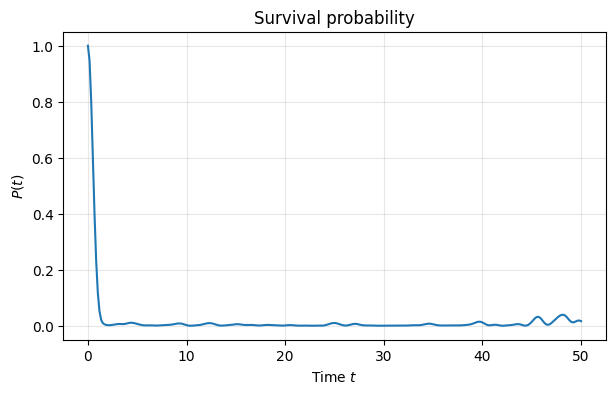

P(0) = 1.0


In [336]:
plt.figure(
    figsize=(7,4)
)

plt.plot(
    times, 
    survival_probability
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    r"$P(t)$"
)

plt.title(
    "Survival probability"
)

plt.grid(alpha=0.3)
plt.show()

print(
    f"P(0) = {survival_probability[0]}"
)

## 8.7 Integrable versus Chaotic Dynamics

We now compare the evolution generated by two Hamiltonians acting in the same magnetization sector.

The integrable Hamiltonian corresponds to

$$
\lambda=0,
$$

while the non-integrable Hamiltonian is chosen as

$$
\lambda=0.5.
$$

All other parameters are kept fixed.

To ensure a meaningful comparison, the same initial product state is evolved under both Hamiltonians.

Differences in the resulting dynamics therefore originate from the structure of the Hamiltonian rather than from different initial conditions.

In [337]:
_, H_integrable_dyn = build_xxz_sparse(
    L=L_dyn,
    N_up=N_up_dyn,
    Delta=Delta_dyn,
    lam=0.0,
    J=J_dyn
)

_, H_chaotic_dyn = build_xxz_sparse(
    L=L_dyn,
    N_up=N_up_dyn,
    Delta=Delta_dyn,
    lam=0.5,
    J=J_dyn
)

H_integrable_dyn = (
    H_integrable_dyn.tocsr()
)

H_chaotic_dyn = (
    H_chaotic_dyn.tocsr()
)

In [338]:
psi_integrable_t = expm_multiply(
    -1j * H_integrable_dyn,
    phi0,
    start=t_min,
    stop=t_max,
    num=n_times,
    endpoint=True
)

psi_chaotic_t = expm_multiply(
    -1j * H_chaotic_dyn,
    phi0,
    start=t_min,
    stop=t_max,
    num=n_times,
    endpoint=True
)

P_integrable = np.abs(
    psi_integrable_t @ phi0.conj()
)**2

P_chaotic = np.abs(
    psi_chaotic_t @ phi0.conj()
)**2

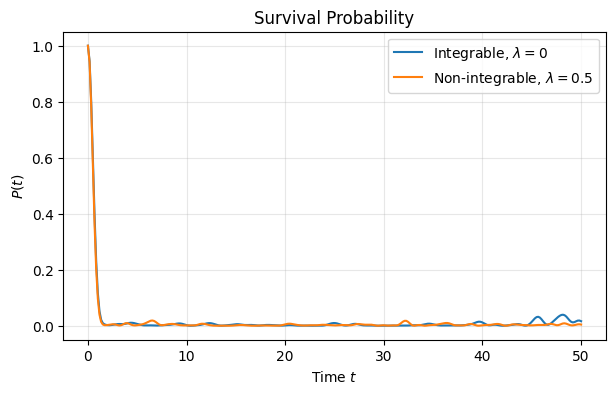

In [339]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    times,
    P_integrable,
    label=r"Integrable, $\lambda=0$"
)

plt.plot(
    times,
    P_chaotic,
    label=r"Non-integrable, $\lambda=0.5$"
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    r"$P(t)$"
)

plt.title(
    "Survival Probability"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

### Survival-Probability Comparison

Both evolutions begin from the same initial condition,

$$
P(0)=1.
$$

As time increases, the initial state spreads over the many-body basis and the survival probability decreases.

The detailed decay and fluctuation pattern depends on the spectral structure and eigenstate composition of the Hamiltonian.

The non-integrable system is expected to exhibit stronger state mixing and more complex dephasing, while integrable dynamics may retain stronger signatures of its constrained structure.

For a finite isolated quantum system, the survival probability does not generally decay irreversibly to zero.

Finite-size fluctuations and quantum recurrences remain present at long times.

## 8.8 Local Magnetization Dynamics

The survival probability measures memory of the complete initial state.

A more local probe is provided by the magnetization at lattice site $i$,

$$
\langle S_i^z(t)\rangle
=
\langle\psi(t)|
S_i^z
|\psi(t)\rangle.
$$

In the computational basis,

$$
S_i^z
=
+\frac{1}{2}
$$

for an up spin and

$$
S_i^z
=
-\frac{1}{2}
$$

for a down spin.

Since $S_i^z$ is diagonal in the computational basis, its expectation value can be calculated efficiently without constructing an explicit sparse operator.

In [340]:
def local_sz_values(
        basis: np.ndarray,
        site: int,
        L: int,
) -> np.ndarray:

    values = np.empty(
        len(basis),
        dtype=float
    )

    for index, state_raw in enumerate(basis):

        state = int(state_raw)

        bit = get_bit(
            state,
            site,
            L
        )

        if bit == 0:
            values[index] = 0.5
        else:
            values[index] = -0.5
    return values

In [341]:
site_probe = L_dyn // 2

sz_values = local_sz_values(
    basis=basis_dyn,
    site=site_probe,
    L=L_dyn
)

prob_integrable = np.abs(
    psi_integrable_t
)**2

prob_chaotic = np.abs(
    psi_chaotic_t
)**2

sz_integrable = (
    prob_integrable @ sz_values
)

sz_chaotic = (
    prob_chaotic @ sz_values
)

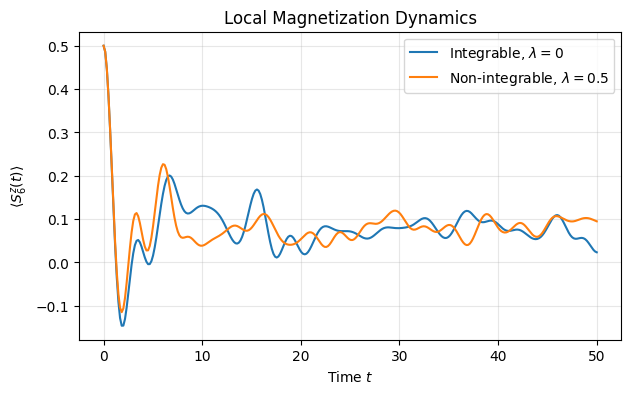

In [342]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    times,
    sz_integrable,
    label=r"Integrable, $\lambda=0$"
)

plt.plot(
    times,
    sz_chaotic,
    label=r"Non-integrable, $\lambda=0.5$"
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    rf"$\langle S_{{{site_probe}}}^z(t)\rangle$"
)

plt.title(
    "Local Magnetization Dynamics"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

## 8.9 Spin Imbalance and Memory of the Initial Configuration

A global measure of memory can be constructed by comparing the instantaneous local magnetization pattern with the initial spin configuration.

Let

$$
s_i^{(0)}
=
2\langle\psi(0)|S_i^z|\psi(0)\rangle,
$$

so that

$$
s_i^{(0)}=\pm1.
$$

We define the spin imbalance as

$$
\mathcal{I}(t)
=
\frac{2}{L}
\sum_{i=0}^{L-1}
s_i^{(0)}
\langle S_i^z(t)\rangle.
$$

For the initial product state,

$$
\mathcal{I}(0)=1.
$$

A decay of $\mathcal{I}(t)$ indicates loss of memory of the original spatial spin pattern.

In [343]:
initial_pattern = np.empty(
    L_dyn, dtype=float
)

for site in range(L_dyn):

    bit = get_bit(
        initial_state_integer,
        site,
        L_dyn
    )

    initial_pattern[site] = (
        +1.0 if bit == 0 else -1.0
    )

sz_basis_matrix = np.column_stack([
    local_sz_values(
        basis_dyn,
        site,
        L_dyn
    ) 
    for site in range(L_dyn)
])

local_magnetization_integrable = (
    prob_integrable @ sz_basis_matrix
)

local_magnetization_chaotic = (
    prob_chaotic @ sz_basis_matrix
)

imbalance_integrable = (
    2.0 / L_dyn * (local_magnetization_integrable @ initial_pattern)
)

imbalance_chaotic = (
    2.0 / L_dyn * (local_magnetization_chaotic @ initial_pattern)
)


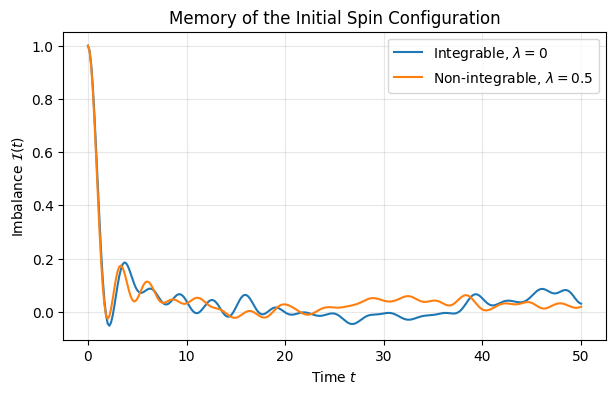

In [344]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    times,
    imbalance_integrable,
    label=r"Integrable, $\lambda=0$"
)

plt.plot(
    times,
    imbalance_chaotic,
    label=r"Non-integrable, $\lambda=0.5$"
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    r"Imbalance $\mathcal{I}(t)$"
)

plt.title(
    "Memory of the Initial Spin Configuration"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

In [345]:
print(
    "I_integrable(0) = ",
    imbalance_integrable[0]
)

print(
    "I_chaotic(0) = ",
    imbalance_chaotic[0]
)

I_integrable(0) =  1.0
I_chaotic(0) =  1.0


## 8.10 Long-Time Behaviour

A finite isolated quantum system does not generally converge to a perfectly stationary state.

Instead, observables continue to fluctuate because the evolution remains unitary.

A useful quantity is therefore the long-time average,

$$
\overline{O}
=
\frac{1}{T_2-T_1}
\int_{T_1}^{T_2}
O(t)\,dt.
$$

Numerically, this can be approximated by averaging over a late-time window.

Comparing long-time averages and temporal fluctuations provides information about how effectively the system loses memory of its initial condition.

In [346]:
late_time_mask = (
    times >= 0.6*t_max
)

P_int_long = np.mean(
    P_integrable[late_time_mask]
)

P_chaos_long = np.mean(
    P_chaotic[late_time_mask]
)

I_int_long = np.mean(
    imbalance_integrable[late_time_mask]
)

I_chao_long = np.mean(
    imbalance_chaotic[late_time_mask]
)

print(
    "Long-time averages"
)

print(
    f"Integrable <P> = "
    f"{P_int_long:.6f}"
)

print(
    f"Chaotic <P>    = "
    f"{P_chaos_long:.6f}"
)

print(
    f"Integrable <I> = "
    f"{I_int_long:.6f}"
)
print(
    f"Chaotic <I>    = "
    f"{I_chao_long:.6f}"
)

Long-time averages
Integrable <P> = 0.007637
Chaotic <P>    = 0.003740
Integrable <I> = 0.027220
Chaotic <I>    = 0.032689


In [347]:
F_int_std = np.std(
    P_integrable[
        late_time_mask
    ]
)

F_chaos_std = np.std(
    P_chaotic[
        late_time_mask
    ]
)

print(
    "Long-time survival fluctuations:"
)

print(
    "Integrable:",
    F_int_std
)

print(
    "Chaotic:",
    F_chaos_std
)

Long-time survival fluctuations:
Integrable: 0.009850995041389175
Chaotic: 0.0033054148270335883


## 8.11 Numerical Consistency Checks

Quantum time evolution generated by a Hermitian Hamiltonian is unitary.

Therefore, the norm of the state must remain constant,

$$
\langle\psi(t)|\psi(t)\rangle
=
1.
$$

The total magnetization must also remain constant because

$$
[H,S_{\mathrm{tot}}^z]=0.
$$

Several numerical consistency checks can therefore be applied to the time-evolved states before interpreting the dynamics physically.

In [348]:
norms_integrable = np.sum(
    np.abs(psi_integrable_t)**2,
    axis = 1
)

norms_chaotic = np.sum(
    np.abs(psi_chaotic_t)**2,
    axis = 1
)

print(
    "Maximum norm error, integrable:",
    np.max(
        np.abs(
            norms_integrable
            -
            1.0
        )
    )
)

print(
    "Maximum norm error, chaotic:",
    np.max(
        np.abs(
            norms_chaotic
            -
            1.0
        )
    )
)

Maximum norm error, integrable: 1.2656542480726785e-14
Maximum norm error, chaotic: 2.19824158875781e-14


In [349]:
assert np.allclose(
    norms_integrable,
    1.0,
    atol=1e-10
)

assert np.allclose(
    norms_chaotic,
    1.0,
    atol=1e-10
)

assert np.isclose(
    P_integrable[0],
    1.0
)

assert np.isclose(
    P_chaotic[0],
    1.0
)

assert np.isclose(
    imbalance_integrable[0],
    1.0
)

assert np.isclose(
    imbalance_chaotic[0],
    1.0
)

print(
    "All basic dynamical checks passed."
)

All basic dynamical checks passed.


## 8.12 Summary of Non-Equilibrium Quantum Dynamics

The analysis has now been extended from stationary spectral properties to real-time quantum dynamics.

Starting from a computational-basis product state,

$$
|\psi(0)\rangle,
$$

the state was evolved according to

$$
|\psi(t)\rangle
=
e^{-iHt}
|\psi(0)\rangle.
$$

The sparse Hamiltonian representation allowed the exponential action to be evaluated without constructing the complete dense operator

$$
e^{-iHt}.
$$

Several dynamical observables were introduced.

The survival probability,

$$
P(t)
=
\left|
\langle\psi(0)|\psi(t)\rangle
\right|^2,
$$

measures the probability of recovering the complete initial state.

The local magnetization,

$$
\langle S_i^z(t)\rangle,
$$

probes the evolution of individual lattice sites.

The spin imbalance,

$$
\mathcal{I}(t),
$$

measures the persistence of the initial spatial spin pattern.

The dynamics were compared between the integrable regime,

$$
\lambda=0,
$$

and a non-integrable regime,

$$
\lambda=0.5.
$$

The numerical evolution was validated by conservation of the wave-function norm and total magnetization.

The project has therefore progressed from

$$
\text{spectral chaos}
$$

to

$$
\text{non-equilibrium dynamics}.
$$

The next natural step is to investigate a genuinely quantum measure of information spreading:

$$
\boxed{
\text{entanglement entropy}.
}
$$

The growth of bipartite entanglement will provide a complementary dynamical signature of the difference between integrable and chaotic many-body evolution.

# 9. Entanglement Dynamics

The previous section investigated non-equilibrium quantum dynamics through observables such as the survival probability, local magnetization, and spin imbalance.

These quantities measure different forms of memory of the initial state.

We now introduce a genuinely quantum measure of information spreading: bipartite entanglement.

Starting from an initially unentangled product state,

$$
|\psi(0)\rangle,
$$

unitary evolution under an interacting Hamiltonian generally generates quantum correlations between different spatial regions of the chain.

We divide the system into two subsystems,

$$
A \cup B,
$$

and study the entanglement between them.

For a pure quantum state, this entanglement is quantified by the von Neumann entropy

$$
S_A(t)
=
-\operatorname{Tr}
\left[
\rho_A(t)\log\rho_A(t)
\right],
$$

where

$$
\rho_A(t)
=
\operatorname{Tr}_B
\left[
|\psi(t)\rangle
\langle\psi(t)|
\right].
$$

The growth of $S_A(t)$ provides a direct probe of the spreading of quantum information through the interacting spin chain.

## 9.1 Bipartite Entanglement

Consider a spatial bipartition of the spin chain into two contiguous subsystems,

$$
A
=
\{0,\ldots,L_A-1\},
$$

and

$$
B
=
\{L_A,\ldots,L-1\}.
$$

For an even system size, we choose a half-chain bipartition,

$$
L_A=L_B=\frac{L}{2}.
$$

The full Hilbert space has the tensor-product structure

$$
\mathcal{H}
=
\mathcal{H}_A
\otimes
\mathcal{H}_B.
$$

An arbitrary pure state can therefore be written as

$$
|\psi\rangle
=
\sum_{a,b}
C_{ab}
|a\rangle_A
\otimes
|b\rangle_B.
$$

The matrix

$$
C_{ab}
$$

contains the amplitudes associated with each pair of subsystem configurations.

Entanglement is generated when this coefficient matrix cannot be factorized as

$$
C_{ab}=u_a v_b.
$$

In [350]:
L_A = L_dyn//2
L_B = L_dyn - L_A

print("Subsystem A size:", L_A)
print("Subsystem B size:", L_B)

print(
    "Subsystem dimensions:",
    2**L_A,
    2**L_B
)

Subsystem A size: 6
Subsystem B size: 6
Subsystem dimensions: 64 64


## 9.2 Reduced Density Matrix

The density matrix of the complete pure state is

$$
\rho
=
|\psi\rangle
\langle\psi|.
$$

The state of subsystem $A$ is obtained by tracing over subsystem $B$,

$$
\rho_A
=
\operatorname{Tr}_B(\rho).
$$

Using the coefficient matrix $C$, the reduced density matrix can be written directly as

$$
\rho_A
=
CC^\dagger.
$$

Similarly,

$$
\rho_B
=
C^\dagger C.
$$

For a normalized state,

$$
\operatorname{Tr}\rho_A
=
\operatorname{Tr}\rho_B
=
1.
$$

If the complete state is a product state, $\rho_A$ is pure.

If the two subsystems are entangled, $\rho_A$ becomes mixed even though the complete state remains pure.

## 9.3 Schmidt Decomposition

Any bipartite pure state admits a Schmidt decomposition,

$$
|\psi\rangle
=
\sum_{\alpha}
\sigma_\alpha
|\alpha\rangle_A
|\alpha\rangle_B,
$$

where the Schmidt coefficients satisfy

$$
\sigma_\alpha\geq0
$$

and

$$
\sum_\alpha\sigma_\alpha^2=1.
$$

The squared Schmidt coefficients,

$$
p_\alpha
=
\sigma_\alpha^2,
$$

are precisely the non-zero eigenvalues of the reduced density matrices,

$$
\rho_A
\qquad\text{and}\qquad
\rho_B.
$$

Numerically, the Schmidt coefficients can be obtained directly from the singular-value decomposition of the coefficient matrix,

$$
C
=
U\Sigma V^\dagger.
$$

This avoids explicitly diagonalizing the reduced density matrix and provides a convenient and numerically stable method for calculating entanglement.

## 9.4 Entanglement in a Fixed-Magnetization Basis

The time-evolved wave function used in this project is represented in a fixed-magnetization basis.

Its dimension is

$$
D
=
\binom{L}{N_\uparrow},
$$

rather than the complete Hilbert-space dimension

$$
2^L.
$$

Consequently, the reduced state vector cannot be reshaped directly into a matrix of dimensions

$$
2^{L_A}
\times
2^{L_B}.
$$

The tensor-product structure must instead be reconstructed from the binary representation of each many-body basis state.

Because site $0$ corresponds to the leftmost, most significant binary digit, a state integer can be decomposed as

$$
n
=
a\,2^{L_B}+b,
$$

where $a$ labels the configuration of subsystem $A$ and $b$ labels the configuration of subsystem $B$.

Therefore,

$$
a
=
n >> L_B,
$$

while

$$
b
=
n \;\&\; (2^{L_B}-1).
$$

This mapping allows the reduced-basis wave function to be embedded directly into the bipartite amplitude matrix $C_{ab}$.

In [351]:
def bipartite_amplitude_matrix(
        psi: np.ndarray,
        basis: np.ndarray,
        L: int,
        L_A: int
) -> np.ndarray:

    if len(psi) != len(basis):
        raise ValueError("psi and basis must have the same lenght")
    if not 0 < L_A < L:
        raise ValueError("Expected 0 < L_A < L")

    L_B = L - L_A

    dimA = 2**L_A
    dimB = 2**L_B

    C = np.zeros(
        (dimA,dimB),
        dtype=complex
    )

    maskB = (
        1 << L_B
    ) - 1

    for amplitude, state_raw in zip(
        psi,
        basis
    ):
        state = int(state_raw)

        index_A = (
            state >> L_B
        )

        index_B = (
            state & maskB
        )

        C[
            index_A,
            index_B
        ] = amplitude
    return C

In [352]:
C0 = bipartite_amplitude_matrix(
    psi=phi0,
    basis=basis_dyn,
    L=L_dyn,
    L_A=L_A
)

print(
    "Coefficient matrix shape:",
    C0.shape
)

print(
    "Norm from C:",
    np.sum(
        np.abs(C0)**2
    )
)

Coefficient matrix shape: (64, 64)
Norm from C: 1.0


## 9.5 Von Neumann Entanglement Entropy

The bipartite von Neumann entropy is defined as

$$
S_A
=
-\operatorname{Tr}
\left[
\rho_A\log\rho_A
\right].
$$

In terms of the Schmidt probabilities

$$
p_\alpha
=
\sigma_\alpha^2,
$$

this becomes

$$
S_A
=
-\sum_\alpha
p_\alpha
\log p_\alpha.
$$

Throughout this project, the natural logarithm is used, so the entropy is measured in nats.

For a product state,

$$
S_A=0,
$$

whereas an entangled state satisfies

$$
S_A>0.
$$

For a subsystem containing $L_A$ spin-$1/2$ degrees of freedom, the general Hilbert-space bound is

$$
S_A
\leq
L_A\log 2.
$$

For the present half-chain bipartition,

$$
L_A=6,
$$

which gives

$$
S_A
\leq
6\log2
\approx
4.159.
$$

However, this general bound does not take into account the fixed-magnetization constraint.

Because the dynamics is restricted to the sector

$$
L=12,
\qquad
N_\uparrow=7,
$$

the allowed Schmidt decomposition is constrained by particle-number conservation.

The maximum Schmidt rank is

$$
\chi_{\max}
=
\sum_{N_A}
\min
\left[
\binom{L_A}{N_A},
\binom{L_B}{N_\uparrow-N_A}
\right].
$$

For the present bipartition,

$$
L_A=L_B=6,
$$

the numerical calculation gives

$$
\chi_{\max}=44.
$$

Therefore, a more restrictive entropy bound is

$$
S_A
\leq
\log\chi_{\max}
=
\log44
\approx
3.784.
$$

This sector-dependent bound provides a more meaningful reference scale for the entanglement generated during the dynamics.

In [353]:
def entanglement_entropy(
        psi: np.ndarray,
        basis: np.ndarray,
        L: int,
        L_A: int,
        tolerance: float=1e-14
) -> float:

    C = bipartite_amplitude_matrix(
        psi=psi,
        basis=basis,
        L=L,
        L_A=L_A
    )

    singular_values = np.linalg.svd(
        C,
        compute_uv=False
    )
    
    probabilities = (
        np.abs(
            singular_values
        )**2
    )
    probabilities = probabilities[
        probabilities > tolerance
    ]

    probabilities = (
        probabilities / np.sum(probabilities)
    )

    entropy = -np.sum(probabilities*np.log(probabilities))

    return float(entropy)

## 9.6 Validation with the Initial Product State

The initial state used for the dynamics is a computational-basis product state.

It can be written as

$$
|\psi(0)\rangle
=
|\psi_A(0)\rangle
\otimes
|\psi_B(0)\rangle.
$$

Its Schmidt decomposition therefore contains only one non-zero coefficient,

$$
\sigma_1=1,
$$

so that

$$
p_1=1.
$$

Consequently,

$$
S_A(0)=0.
$$

The numerical calculation gives

$$
S_A(0)\approx0,
$$

within machine precision.

The reduced density matrix also satisfies

$$
\operatorname{Tr}\rho_A=1,
$$

and is numerically Hermitian.

These checks confirm that the bipartite amplitude matrix and entropy calculation correctly reproduce the expected properties of the initial unentangled product state.

In [354]:
S_initial = entanglement_entropy(
    psi=phi0,
    basis=basis_dyn,
    L=L_dyn,
    L_A=L_A
)

print(
    "Initial entanglement entropy:",
    S_initial
)

Initial entanglement entropy: -0.0


In [355]:
rho_A_0 = (
    C0
    @ C0.conj().T
)

print(
    "Tr(rho_A) =",
    np.trace(rho_A_0)
)

print(
    "Hermitian:",
    np.allclose(
        rho_A_0,
        rho_A_0.conj().T
    )
)

Tr(rho_A) = (1+0j)
Hermitian: True


## 9.7 Entanglement-Growth Results

Both the integrable and non-integrable systems start from the same product state,

$$
S_A(0)=0,
$$

and generate substantial bipartite entanglement during the subsequent unitary evolution.

At short times, the two curves display similar behaviour, indicating that local interactions initially generate entanglement efficiently in both regimes.

At later times, however, a clear separation develops.

The non-integrable system reaches a larger entanglement entropy and approaches a smoother saturation regime, whereas the integrable system exhibits more pronounced temporal oscillations and revivals.

This distinction shows that the difference between integrable and chaotic dynamics is not simply whether entanglement is generated, since both systems produce strong entanglement.

Instead, the most visible differences appear in

$$
\text{the saturation value},
$$

$$
\text{the temporal fluctuations},
$$

and

$$
\text{the distribution of Schmidt weights}.
$$

For the present finite system, the chaotic dynamics explores a larger fraction of the entanglement structure allowed by the fixed-magnetization sector.

In [356]:
S_integrable = np.array([
    entanglement_entropy(
        psi=psi,
        basis=basis_dyn,
        L=L_dyn,
        L_A=L_A
    )
    for psi in psi_integrable_t
])

S_chaotic = np.array([
    entanglement_entropy(
        psi=psi,
        basis=basis_dyn,
        L=L_dyn,
        L_A=L_A
    )
    for psi in psi_chaotic_t
])


print(
    "S_integrable(0) =",
    S_integrable[0]
)

print(
    "S_chaotic(0) =",
    S_chaotic[0]
)

S_integrable(0) = -0.0
S_chaotic(0) = -0.0


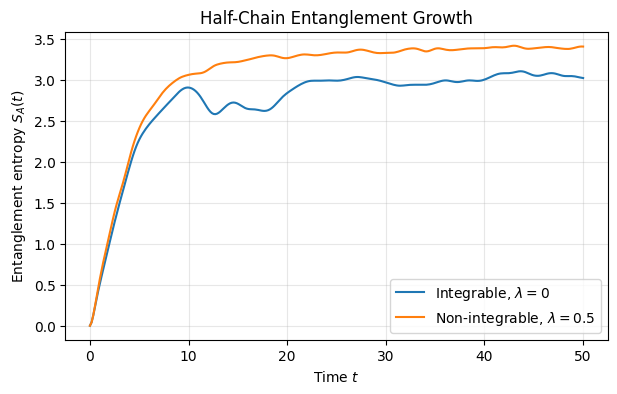

General upper bound: 4.1588830833596715


In [357]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    times,
    S_integrable,
    label=r"Integrable, $\lambda=0$"
)

plt.plot(
    times,
    S_chaotic,
    label=r"Non-integrable, $\lambda=0.5$"
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    r"Entanglement entropy $S_A(t)$"
)

plt.title(
    "Half-Chain Entanglement Growth"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

S_max_general = (
    L_A
    *
    np.log(2.0)
)

print(
    "General upper bound:",
    S_max_general
)

In [358]:
def r_squared(y, y_fit):
    residual = np.sum(
        (y - y_fit)**2
    )

    total = np.sum(
        (y - np.mean(y))**2
    )

    return 1.0 - residual / total


R2_integrable = r_squared(
    S_integrable[fit_mask],
    S_fit_integrable
)

R2_chaotic = r_squared(
    S_chaotic[fit_mask],
    S_fit_chaotic
)

print("R² integrable:", R2_integrable)
print("R² chaotic:", R2_chaotic)

R² integrable: 0.9967076390364135
R² chaotic: 0.9937606362506856


In [359]:
from math import comb

def maximum_schmidt_rank_fixed_magnetization(
    L: int,
    N_up: int,
    L_A: int
) -> int:

    L_B = L - L_A

    rank_max = 0

    for N_A in range(L_A + 1):

        N_B = N_up - N_A

        if 0 <= N_B <= L_B:

            dim_A_sector = comb(
                L_A,
                N_A
            )

            dim_B_sector = comb(
                L_B,
                N_B
            )

            rank_max += min(
                dim_A_sector,
                dim_B_sector
            )

    return rank_max

In [360]:
chi_max = maximum_schmidt_rank_fixed_magnetization(
    L=L_dyn,
    N_up=N_up_dyn,
    L_A=L_A
)

S_max_sector = np.log(
    chi_max
)

print(
    "Maximum Schmidt rank:",
    chi_max
)

print(
    "Sector-constrained entropy bound:",
    S_max_sector
)

Maximum Schmidt rank: 44
Sector-constrained entropy bound: 3.784189633918261


## 9.8 Early-Time Entanglement Growth

After a global quench, interacting one-dimensional systems often display an approximately linear regime of entanglement growth before finite-size saturation,

$$
S_A(t)
\approx
S_A(0)
+
v_E t.
$$

The coefficient

$$
v_E
$$

provides an effective entanglement-growth rate.

For the present finite system, a linear fit was performed in the interval

$$
0.5
\leq
t
\leq
5.
$$

The resulting slopes are

$$
v_E^{\mathrm{int}}
\approx
0.465,
$$

and

$$
v_E^{\mathrm{chaos}}
\approx
0.482.
$$

The non-integrable system therefore displays a slightly larger effective growth rate, although the difference is modest.

Relative to the integrable result, the increase is approximately

$$
\frac{
v_E^{\mathrm{chaos}}
-
v_E^{\mathrm{int}}
}{
v_E^{\mathrm{int}}
}
\approx
3.7\%.
$$

The quality of the linear approximation is high in both cases.

The coefficients of determination are

$$
R^2_{\mathrm{int}}
\approx
0.9967,
$$

and

$$
R^2_{\mathrm{chaos}}
\approx
0.9938.
$$

These values indicate that the chosen time interval is well described by an approximately linear increase of the entanglement entropy.

Nevertheless, the difference between the two growth rates is considerably smaller than the difference observed in their long-time behaviour.

The strongest distinction between the integrable and chaotic regimes therefore emerges primarily in the saturation value and temporal fluctuations rather than in the earliest stage of entanglement production.

In [361]:
fit_mask = (
    (times >= 0.5)
    &
    (times <= 5.0)
)

coeff_integrable = np.polyfit(
    times[fit_mask],
    S_integrable[fit_mask],
    deg=1
)

coeff_chaotic = np.polyfit(
    times[fit_mask],
    S_chaotic[fit_mask],
    deg=1
)

v_E_integrable = (
    coeff_integrable[0]
)

v_E_chaotic = (
    coeff_chaotic[0]
)

print(
    "Effective entanglement growth rates"
)

print(
    "Integrable:",
    v_E_integrable
)

print(
    "Chaotic:",
    v_E_chaotic
)

Effective entanglement growth rates
Integrable: 0.46513589412149137
Chaotic: 0.4824840412930288


In [362]:
S_fit_integrable = np.polyval(
    coeff_integrable,
    times[fit_mask]
)

S_fit_chaotic = np.polyval(
    coeff_chaotic,
    times[fit_mask]
)

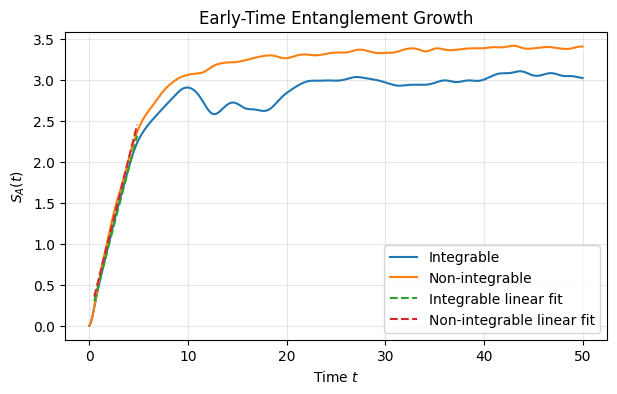

In [363]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    times,
    S_integrable,
    label="Integrable"
)

plt.plot(
    times,
    S_chaotic,
    label="Non-integrable"
)

plt.plot(
    times[fit_mask],
    S_fit_integrable,
    "--",
    label="Integrable linear fit"
)

plt.plot(
    times[fit_mask],
    S_fit_chaotic,
    "--",
    label="Non-integrable linear fit"
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    r"$S_A(t)$"
)

plt.title(
    "Early-Time Entanglement Growth"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

## 9.9 Long-Time Saturation and Fluctuations

Because the system is finite, entanglement growth cannot continue indefinitely.

At sufficiently long times, the entropy reaches a finite-size regime characterized by a non-zero average value and temporal fluctuations.

We characterize this regime through the late-time average

$$
\overline{S_A}
=
\frac{1}{N_T}
\sum_{t\in\mathrm{late}}
S_A(t),
$$

and the corresponding standard deviation,

$$
\sigma_S
=
\sqrt{
\overline{
\left(
S_A-\overline{S_A}
\right)^2
}
}.
$$

The numerical results are

$$
\overline{S_A}^{\mathrm{int}}
\approx
3.012,
$$

and

$$
\overline{S_A}^{\mathrm{chaos}}
\approx
3.380.
$$

The non-integrable system therefore reaches a significantly larger long-time entanglement entropy.

The temporal fluctuations are

$$
\sigma_S^{\mathrm{int}}
\approx
0.0552,
$$

and

$$
\sigma_S^{\mathrm{chaos}}
\approx
0.0193.
$$

Thus, the chaotic regime exhibits fluctuations approximately three times smaller than the integrable regime.

Relative to the fixed-magnetization upper bound,

$$
S_{\max}
=
\log44
\approx
3.784,
$$

the late-time entropies correspond approximately to

$$
\frac{
\overline{S_A}^{\mathrm{int}}
}{
S_{\max}
}
\approx
0.80,
$$

and

$$
\frac{
\overline{S_A}^{\mathrm{chaos}}
}{
S_{\max}
}
\approx
0.89.
$$

The chaotic dynamics therefore explores a larger fraction of the entanglement structure available in the symmetry sector.

The combination of a larger saturation entropy and substantially smaller fluctuations provides a particularly clear dynamical distinction between the integrable and non-integrable regimes.

In [364]:
S_integrable_long = np.mean(
    S_integrable[
        late_time_mask
    ]
)

S_chaotic_long = np.mean(
    S_chaotic[
        late_time_mask
    ]
)

S_integrable_std = np.std(
    S_integrable[
        late_time_mask
    ]
)

S_chaotic_std = np.std(
    S_chaotic[
        late_time_mask
    ]
)

In [365]:
print(
    "Long-time entanglement"
)

print(
    f"Integrable <S_A> = "
    f"{S_integrable_long:.6f}"
)

print(
    f"Chaotic <S_A>    = "
    f"{S_chaotic_long:.6f}"
)

print()

print(
    "Long-time fluctuations"
)

print(
    f"Integrable std = "
    f"{S_integrable_std:.6f}"
)

print(
    f"Chaotic std    = "
    f"{S_chaotic_std:.6f}"
)

Long-time entanglement
Integrable <S_A> = 3.012410
Chaotic <S_A>    = 3.379626

Long-time fluctuations
Integrable std = 0.055209
Chaotic std    = 0.019347


## 9.10 Entanglement Spectrum

The von Neumann entropy compresses the complete entanglement structure into a single scalar quantity.

Additional information is contained in the eigenvalues of the reduced density matrix,

$$
p_\alpha.
$$

These eigenvalues form the Schmidt spectrum.

It is also common to introduce entanglement energies,

$$
\xi_\alpha
=
-\log p_\alpha.
$$

Large Schmidt probabilities correspond to small entanglement energies.

The Schmidt spectrum therefore provides a more detailed description of how the quantum state is distributed across the bipartite Hilbert space.

For the present system, the spectrum was evaluated at

$$
t
\approx
10.03.
$$

At this time, both the integrable and non-integrable states contain many non-zero Schmidt probabilities, showing that substantial entanglement has already developed.

However, the two distributions display visibly different structures.

The integrable spectrum is more strongly hierarchical: its Schmidt probabilities decay more rapidly with the Schmidt index.

The non-integrable spectrum is broader and distributes appreciable weight among a larger number of Schmidt modes.

This more homogeneous spreading of Schmidt weight is consistent with the larger von Neumann entropy observed in the chaotic regime.

The maximum number of Schmidt modes is not

$$
2^{L_A}=64,
$$

because total magnetization is conserved.

For

$$
L=12,
\qquad
N_\uparrow=7,
\qquad
L_A=L_B=6,
$$

the fixed-magnetization constraint reduces the maximum Schmidt rank to

$$
\chi_{\max}=44.
$$

The numerical Schmidt spectrum is therefore directly shaped by the same symmetry reduction that was used earlier to construct the many-body Hamiltonian.

This establishes a direct connection between conserved quantities and the structure of bipartite entanglement.

In [366]:
def schmidt_probabilities(
        psi: np.ndarray,
        basis: np.ndarray,
        L:int,
        L_A: int,
        tolerance: float=1e-14
) -> np.ndarray:

    C = bipartite_amplitude_matrix(
        psi=psi,
        basis=basis,
        L=L,
        L_A=L_A
    )

    singular_values = np.linalg.svd(
        C,
        compute_uv=False
    )

    probabilities = np.abs(
        singular_values
    )**2

    probabilities = probabilities[
        probabilities > tolerance
    ]

    probabilities /= np.sum(probabilities)

    return np.sort(probabilities)[::-1]

In [367]:
time_target = 10.0

time_index = np.argmin(
    np.abs(times - time_target)
)

print(
    "Selected time:",
    times[time_index]
)

Selected time: 10.033444816053512


In [368]:
p_integrable = schmidt_probabilities(
    psi_integrable_t[time_index],
    basis_dyn,
    L_dyn,
    L_A
)

p_chaotic = schmidt_probabilities(
    psi_chaotic_t[time_index],
    basis_dyn,
    L_dyn,
    L_A
)

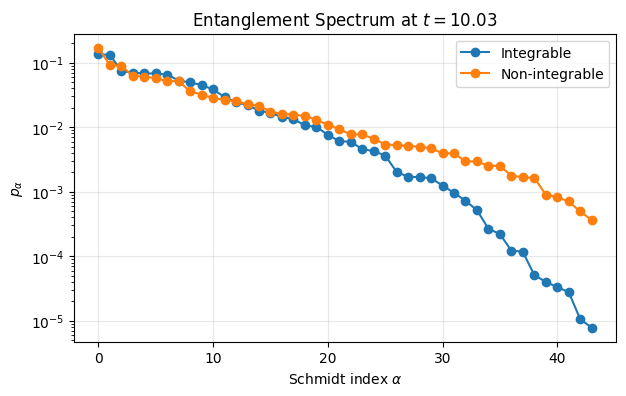

In [369]:
plt.figure(
    figsize=(7, 4)
)

plt.semilogy(
    np.arange(
        len(p_integrable)
    ),
    p_integrable,
    "o-",
    label="Integrable"
)

plt.semilogy(
    np.arange(
        len(p_chaotic)
    ),
    p_chaotic,
    "o-",
    label="Non-integrable"
)

plt.xlabel(
    r"Schmidt index $\alpha$"
)

plt.ylabel(
    r"$p_\alpha$"
)

plt.title(
    rf"Entanglement Spectrum at $t={times[time_index]:.2f}$"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

## 9.11 Relation to Other Dynamical Observables

The different dynamical observables introduced in this project probe complementary aspects of the quantum evolution.

The survival probability,

$$
P(t)
=
|\langle\psi(0)|\psi(t)\rangle|^2,
$$

measures memory of the complete initial state.

The spin imbalance,

$$
\mathcal{I}(t),
$$

measures memory of the initial spatial magnetization pattern.

The entanglement entropy,

$$
S_A(t),
$$

instead measures quantum correlations generated between two spatial regions.

The numerical results reveal a complementary dynamical picture.

As the survival probability rapidly decreases, the system loses overlap with its original many-body configuration.

At the same time, the imbalance decreases strongly, indicating substantial loss of memory of the initial spin pattern.

In contrast, the entanglement entropy grows from

$$
S_A(0)=0
$$

toward a large finite-size saturation value.

The evolution can therefore be summarized schematically as

$$
\text{loss of initial-state memory}
\quad\longleftrightarrow\quad
\text{growth of many-body entanglement}.
$$

These processes are related but not equivalent.

A small survival probability does not imply that all local observables have fully relaxed, and strong entanglement does not uniquely determine the behaviour of the imbalance.

The three observables

$$
P(t),
\qquad
\mathcal{I}(t),
\qquad
S_A(t)
$$

therefore provide complementary information about the same non-equilibrium evolution.

In the non-integrable regime, the simultaneous decay of memory observables, large entanglement saturation, and reduced long-time fluctuations are consistent with a more strongly mixing many-body dynamics.

In [370]:
S_integrable_normalized = (
    S_integrable
    /
    S_max_general
)

S_chaotic_normalized = (
    S_chaotic
    /
    S_max_general
)

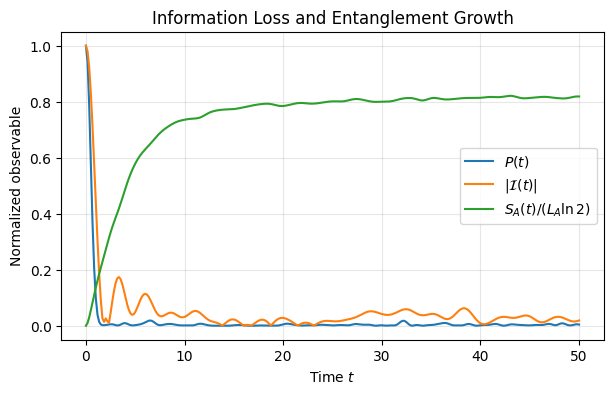

In [371]:
plt.figure(
    figsize=(7, 4)
)

plt.plot(
    times,
    P_chaotic,
    label=r"$P(t)$"
)

plt.plot(
    times,
    np.abs(
        imbalance_chaotic
    ),
    label=r"$|\mathcal{I}(t)|$"
)

plt.plot(
    times,
    S_chaotic_normalized,
    label=r"$S_A(t)/(L_A\ln2)$"
)

plt.xlabel(
    r"Time $t$"
)

plt.ylabel(
    "Normalized observable"
)

plt.title(
    "Information Loss and Entanglement Growth"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

In [372]:
C_check = bipartite_amplitude_matrix(
    psi=psi_check,
    basis=basis_dyn,
    L=L_dyn,
    L_A=L_A
)

rho_A = (
    C_check
    @ C_check.conj().T
)

rho_B = (
    C_check.conj().T
    @ C_check
)

eig_A = np.linalg.eigvalsh(
    rho_A
)

eig_B = np.linalg.eigvalsh(
    rho_B
)

eig_A = eig_A[
    eig_A > 1e-14
]

eig_B = eig_B[
    eig_B > 1e-14
]

S_A_check = -np.sum(
    eig_A * np.log(eig_A)
)

S_B_check = -np.sum(
    eig_B * np.log(eig_B)
)

print("S_A =", S_A_check)
print("S_B =", S_B_check)
print(
    "Difference =",
    abs(S_A_check - S_B_check)
)

S_A = 3.0609521514037286
S_B = 3.060952151403728
Difference = 4.440892098500626e-16


## 9.12 Numerical Consistency Checks

Several properties provide direct validation of the entanglement calculation.

For every normalized pure state,

$$
\sum_\alpha p_\alpha=1.
$$

The entanglement entropy must satisfy

$$
S_A\geq0.
$$

For the initial product state,

$$
S_A(0)=0.
$$

Finally, for a pure bipartite state,

$$
S_A=S_B.
$$

The latter property follows because the reduced density matrices $\rho_A$ and $\rho_B$ have the same non-zero eigenvalues.

In [373]:
psi_check = (
    psi_chaotic_t[
        time_index
    ]
)

S_A_check = entanglement_entropy(
    psi=psi_check,
    basis=basis_dyn,
    L=L_dyn,
    L_A=L_A
)

S_B_check = entanglement_entropy(
    psi=psi_check,
    basis=basis_dyn,
    L=L_dyn,
    L_A=L_B
)

print(
    "S_A =",
    S_A_check
)

print(
    "S_B =",
    S_B_check
)

print(
    "Difference =",
    abs(
        S_A_check
        -
        S_B_check
    )
)

S_A = 3.060952151403747
S_B = 3.060952151403747
Difference = 0.0


In [374]:
assert np.all(
    S_integrable >= -1e-12
)

assert np.all(
    S_chaotic >= -1e-12
)

assert np.isclose(
    S_integrable[0],
    0.0,
    atol=1e-12
)

assert np.isclose(
    S_chaotic[0],
    0.0,
    atol=1e-12
)

print(
    "Entanglement checks passed."
)

Entanglement checks passed.


## 9.13 Summary of Entanglement Dynamics

Bipartite entanglement has been used to characterize quantum-information spreading in the interacting XXZ chain.

The system was divided into two spatial regions,

$$
A\cup B,
$$

and the time-dependent wave function was represented through the bipartite amplitude matrix

$$
C_{ab}(t).
$$

The Schmidt decomposition,

$$
C
=
U\Sigma V^\dagger,
$$

provides Schmidt probabilities

$$
p_\alpha
=
\sigma_\alpha^2,
$$

from which the von Neumann entropy is calculated as

$$
S_A(t)
=
-\sum_\alpha
p_\alpha(t)
\log p_\alpha(t).
$$

Because the dynamics is performed in a fixed-magnetization Hilbert space, the tensor-product structure was reconstructed explicitly from the binary representation of the many-body basis states.

The initial computational-basis state is unentangled,

$$
S_A(0)=0,
$$

while the interacting dynamics rapidly generates bipartite entanglement.

For the present system,

$$
L=12,
\qquad
N_\uparrow=7,
\qquad
L_A=L_B=6,
$$

the magnetization constraint reduces the maximum Schmidt rank from the full value $64$ to

$$
\chi_{\max}=44.
$$

The corresponding symmetry-constrained entropy bound is

$$
S_A
\leq
\log44
\approx
3.784.
$$

The early-time entropy growth is approximately linear in both regimes.

The fitted effective growth rates are

$$
v_E^{\mathrm{int}}
\approx
0.465,
$$

and

$$
v_E^{\mathrm{chaos}}
\approx
0.482.
$$

The corresponding coefficients of determination,

$$
R^2_{\mathrm{int}}
\approx
0.9967,
$$

and

$$
R^2_{\mathrm{chaos}}
\approx
0.9938,
$$

confirm that the selected early-time interval is well described by a linear approximation.

The strongest distinction between the two regimes appears at long times.

The average entanglement entropies are

$$
\overline{S_A}^{\mathrm{int}}
\approx
3.012,
$$

and

$$
\overline{S_A}^{\mathrm{chaos}}
\approx
3.380.
$$

The chaotic dynamics therefore reaches a substantially larger fraction of the entanglement allowed by the fixed-magnetization sector.

The long-time fluctuations also differ strongly,

$$
\sigma_S^{\mathrm{int}}
\approx
0.0552,
$$

and

$$
\sigma_S^{\mathrm{chaos}}
\approx
0.0193.
$$

The non-integrable system therefore exhibits a smoother and more stable entanglement plateau.

The Schmidt spectrum provides a complementary microscopic interpretation.

In the integrable regime, the Schmidt probabilities are more strongly concentrated among the largest components.

In the chaotic regime, the weight is distributed more broadly across the accessible Schmidt modes, consistent with the larger entanglement entropy.

Finally, the reduced density matrices satisfy the pure-state consistency relation

$$
S_A=S_B
$$

to numerical precision.

The project therefore connects three complementary signatures of quantum chaos:

$$
\boxed{
\text{spectral correlations}
\rightarrow
\text{non-equilibrium relaxation}
\rightarrow
\text{entanglement spreading}.
}
$$

The spectral analysis showed the crossover from Poisson-like to GOE-like statistics.

The dynamical analysis showed enhanced dephasing and reduced long-time fluctuations in the non-integrable regime.

The entanglement analysis now shows that the same regime also explores a broader and more highly entangled region of Hilbert space.

Together, these results provide a coherent numerical picture of the transition from integrable to chaotic many-body quantum dynamics.

# 10. Eigenstate Thermalization and Observable Statistics

The previous sections established several signatures of quantum chaos in the interacting XXZ chain.

The spectral analysis showed a crossover from Poisson-like statistics in the integrable regime to GOE-like level correlations when integrability is broken.

The dynamical analysis revealed stronger dephasing and smaller long-time fluctuations in the non-integrable regime.

Finally, the entanglement analysis showed that chaotic dynamics explores a broader and more highly entangled region of Hilbert space.

These observations naturally lead to a deeper question:

$$
\boxed{
\text{Why can an isolated quantum many-body system appear to thermalize?}
}
$$

A central framework for understanding this phenomenon is the Eigenstate Thermalization Hypothesis, or ETH.

ETH proposes that, in generic non-integrable quantum systems, individual many-body energy eigenstates already encode thermal properties of local observables.

Thermalization can therefore emerge from unitary quantum dynamics without coupling the system to an external thermal bath.

## 10.1 From Quantum Chaos to Thermalization

Consider an initial state expanded in the energy eigenbasis,

$$
|\psi(0)\rangle
=
\sum_n c_n |E_n\rangle.
$$

Its time evolution is

$$
|\psi(t)\rangle
=
\sum_n
c_n
e^{-iE_nt}
|E_n\rangle.
$$

For an observable $\hat O$, the expectation value is

$$
\langle O(t)\rangle
=
\sum_{m,n}
c_m^*c_n
e^{i(E_m-E_n)t}
O_{mn},
$$

where

$$
O_{mn}
=
\langle E_m|\hat O|E_n\rangle.
$$

The long-time behaviour is therefore controlled not only by the energy eigenvalues, but also by the matrix elements of physical observables in the energy eigenbasis.

This motivates studying the structure of

$$
O_{mn}.
$$

The Eigenstate Thermalization Hypothesis provides a statistical description of these matrix elements in chaotic many-body systems.

## 10.2 The Eigenstate Thermalization Hypothesis

The Eigenstate Thermalization Hypothesis proposes that matrix elements of a sufficiently local observable take the form

$$
O_{mn}
=
\overline{O}(E)\delta_{mn}
+
e^{-S(E)/2}
f(E,\omega)
R_{mn},
$$

where

$$
E
=
\frac{E_m+E_n}{2},
$$

and

$$
\omega
=
E_m-E_n.
$$

The function

$$
\overline{O}(E)
$$

is a smooth function of energy.

The quantity

$$
S(E)
$$

is the thermodynamic entropy, while

$$
f(E,\omega)
$$

is a smooth envelope controlling the off-diagonal structure.

Finally,

$$
R_{mn}
$$

behaves approximately as a random variable with zero mean and unit variance.

The diagonal part of ETH therefore predicts

$$
O_{nn}
=
\langle E_n|\hat O|E_n\rangle
\approx
\overline{O}(E_n),
$$

with fluctuations that decrease as the system size increases.

This smooth eigenstate-to-eigenstate behaviour is one of the most direct numerical signatures of ETH.

## 10.3 Choice of a Local Observable

To test ETH, we require an observable that is local and compatible with the symmetry sector used in the spectral analysis.

For an even open chain, the central nearest-neighbour bond,

$$
i_c
=
\frac{L}{2}-1,
\qquad
j_c
=
\frac{L}{2},
$$

is invariant under spatial reflection.

We therefore choose the local correlation operator

$$
\hat O
=
S_{i_c}^zS_{j_c}^z.
$$

For the present system,

$$
L=12,
$$

this corresponds to

$$
\hat O
=
S_5^zS_6^z.
$$

Since $\hat O$ is diagonal in the computational basis, it can be constructed efficiently without using Kronecker products.

Its eigenvalues in the computational basis are

$$
+\frac{1}{4}
$$

for parallel spins and

$$
-\frac{1}{4}
$$

for antiparallel spins.

In [376]:
from scipy.sparse import diags

In [394]:
def central_zz_values(
    basis: np.ndarray,
    L: int
) -> np.ndarray:

    if L % 2 != 0:
        raise ValueError(
            "The central bond definition requires even L."
        )

    site_i = L // 2 - 1
    site_j = L // 2

    values = np.empty(
        len(basis),
        dtype=float
    )

    for index, state_raw in enumerate(basis):

        state = int(state_raw)

        bit_i = get_bit(
            state=state,
            site=site_i,
            L=L
        )

        bit_j = get_bit(
            state=state,
            site=site_j,
            L=L
        )

        sz_i = (
            0.5 if bit_i == 0
            else -0.5
        )

        sz_j = (
            0.5 if bit_j == 0
            else -0.5
        )

        values[index] = (
            sz_i * sz_j
        )

    return values

## 10.4 Observable in a Symmetry-Resolved Sector

ETH must be analysed inside a single symmetry sector.

Mixing independent symmetry sectors can introduce artificial structure and obscure eigenstate statistics.

Let

$$
U_p
$$

be the transformation from the fixed-magnetization basis to the reflection-parity sector

$$
p=\pm1.
$$

The Hamiltonian in this sector is

$$
H_p
=
U_p^\dagger H U_p.
$$

The observable must be transformed in exactly the same way,

$$
O_p
=
U_p^\dagger O U_p.
$$

We can then diagonalize

$$
H_p
=
V E V^\dagger,
$$

and express the observable in the energy eigenbasis as

$$
O_E
=
V^\dagger O_p V.
$$

The diagonal elements

$$
(O_E)_{nn}
$$

are the eigenstate expectation values used to test the diagonal ETH prediction.

In [395]:
def compute_eth_data(
    L: int,
    N_up: int,
    parity: int,
    Delta: float,
    lam: float,
    J: float = 1.0
) -> dict:

    basis, H = build_xxz_sparse(
        L=L,
        N_up=N_up,
        Delta=Delta,
        lam=lam,
        J=J
    )

    H = H.tocsr()

    U_plus, U_minus = (
        build_parity_tranformation(
            basis=basis,
            L=L
        )
    )

    U = (
        U_plus
        if parity == +1
        else U_minus
    )

    H_parity = (
        U.getH()
        @ H
        @ U
    ).tocsr()

    observable_values = (
        central_zz_values(
            basis=basis,
            L=L
        )
    )

    O = diags(
        observable_values,
        offsets=0,
        format="csr"
    )

    O_parity = (
        U.getH()
        @ O
        @ U
    ).tocsr()

    energies, eigenvectors = np.linalg.eigh(
        H_parity.toarray()
    )

    O_energy_basis = (
        eigenvectors.conj().T
        @ O_parity.toarray()
        @ eigenvectors
    )

    O_diagonal = np.real(
        np.diag(
            O_energy_basis
        )
    )

    energy_density = (
        energies - energies[0]
    ) / (
        energies[-1] - energies[0]
    )

    return {
        "basis": basis,
        "H_parity": H_parity,
        "O_parity": O_parity,
        "energies": energies,
        "energy_density": energy_density,
        "eigenvectors": eigenvectors,
        "O_energy_basis": O_energy_basis,
        "O_diagonal": O_diagonal
    }

In [397]:
L_eth = 12
N_up_eth = 7

Delta_eth = 0.7
J_eth = 1.0
parity_eth = +1


eth_integrable = compute_eth_data(
    L=L_eth,
    N_up=N_up_eth,
    parity=parity_eth,
    Delta=Delta_eth,
    lam=0.0,
    J=J_eth
)

eth_chaotic = compute_eth_data(
    L=L_eth,
    N_up=N_up_eth,
    parity=parity_eth,
    Delta=Delta_eth,
    lam=0.5,
    J=J_eth
)

## 10.5 Diagonal Matrix Elements

The diagonal ETH prediction concerns the eigenstate expectation values

$$
O_{nn}
=
\langle E_n|\hat O|E_n\rangle.
$$

For a chaotic many-body system, these values are expected to form a smooth function of energy,

$$
O_{nn}
\approx
\overline{O}(E_n),
$$

with relatively small eigenstate-to-eigenstate fluctuations.

For an integrable system, conserved quantities constrain the eigenstates and substantially larger fluctuations may remain even between nearby energy levels.

To compare different spectra conveniently, we introduce the normalized energy density

$$
\epsilon_n
=
\frac{
E_n-E_{\min}
}{
E_{\max}-E_{\min}
}.
$$

Thus,

$$
0\leq\epsilon\leq1.
$$

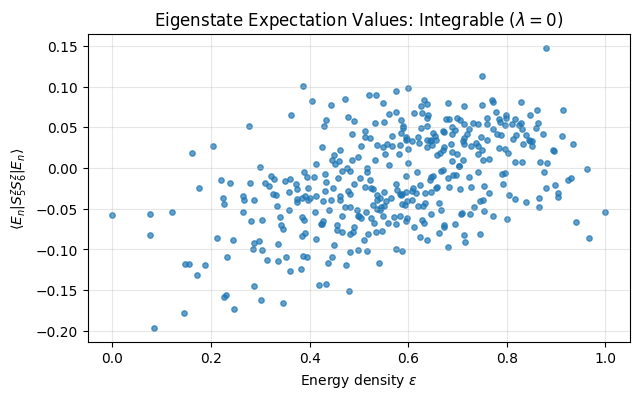

In [398]:
plt.figure(
    figsize=(7, 4)
)

plt.scatter(
    eth_integrable["energy_density"],
    eth_integrable["O_diagonal"],
    s=15,
    alpha=0.7
)

plt.xlabel(
    r"Energy density $\epsilon$"
)

plt.ylabel(
    r"$\langle E_n|S_5^zS_6^z|E_n\rangle$"
)

plt.title(
    r"Eigenstate Expectation Values: Integrable ($\lambda=0$)"
)

plt.grid(
    alpha=0.3
)

plt.show()

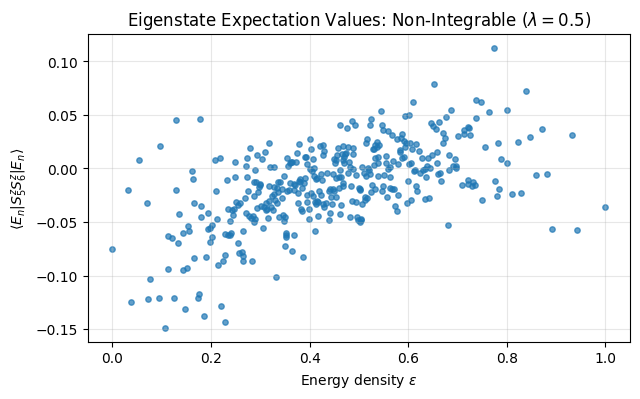

In [399]:
plt.figure(
    figsize=(7, 4)
)

plt.scatter(
    eth_chaotic["energy_density"],
    eth_chaotic["O_diagonal"],
    s=15,
    alpha=0.7
)

plt.xlabel(
    r"Energy density $\epsilon$"
)

plt.ylabel(
    r"$\langle E_n|S_5^zS_6^z|E_n\rangle$"
)

plt.title(
    r"Eigenstate Expectation Values: Non-Integrable ($\lambda=0.5$)"
)

plt.grid(
    alpha=0.3
)

plt.show()

## 10.6 Integrable versus Chaotic Eigenstates

The scatter of diagonal matrix elements provides a direct visual test of ETH.

In the integrable regime, nearby eigenstates may display substantially different expectation values,

$$
O_{nn},
$$

even when their energies are very similar.

In contrast, ETH predicts that the non-integrable spectrum should display a narrower cloud around a smooth energy-dependent function.

The relevant comparison is therefore not simply the mean value of the observable, but the magnitude of eigenstate-to-eigenstate fluctuations at approximately fixed energy.

If the chaotic data form a visibly narrower band than the integrable data, this provides evidence for the diagonal component of ETH.

In [400]:
def local_energy_average(
    energy_density: np.ndarray,
    values: np.ndarray,
    half_width: float = 0.05
) -> tuple[np.ndarray, np.ndarray]:

    local_mean = np.empty_like(
        values,
        dtype=float
    )

    local_std = np.empty_like(
        values,
        dtype=float
    )

    for index, energy in enumerate(
        energy_density
    ):

        mask = (
            np.abs(
                energy_density - energy
            )
            <= half_width
        )

        local_mean[index] = np.mean(
            values[mask]
        )

        local_std[index] = np.std(
            values[mask]
        )

    return local_mean, local_std

In [401]:
mean_integrable, std_integrable = (
    local_energy_average(
        eth_integrable["energy_density"],
        eth_integrable["O_diagonal"],
        half_width=0.05
    )
)

mean_chaotic, std_chaotic = (
    local_energy_average(
        eth_chaotic["energy_density"],
        eth_chaotic["O_diagonal"],
        half_width=0.05
    )
)

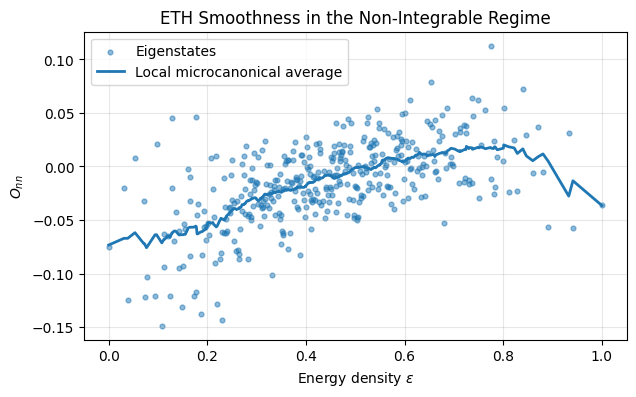

In [402]:
plt.figure(
    figsize=(7, 4)
)

plt.scatter(
    eth_chaotic["energy_density"],
    eth_chaotic["O_diagonal"],
    s=12,
    alpha=0.5,
    label="Eigenstates"
)

plt.plot(
    eth_chaotic["energy_density"],
    mean_chaotic,
    linewidth=2,
    label="Local microcanonical average"
)

plt.xlabel(
    r"Energy density $\epsilon$"
)

plt.ylabel(
    r"$O_{nn}$"
)

plt.title(
    "ETH Smoothness in the Non-Integrable Regime"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

## 10.8 Eigenstate-to-Eigenstate Fluctuations

A more quantitative ETH diagnostic is obtained by subtracting the local microcanonical average,

$$
\delta O_n
=
O_{nn}
-
\overline{O}(E_n).
$$

ETH predicts that these fluctuations become progressively smaller in chaotic systems as the Hilbert-space dimension increases.

We focus on the central spectral region,

$$
0.4
\leq
\epsilon
\leq
0.6,
$$

where spectral-edge effects are minimized.

The standard deviation

$$
\sigma_{\mathrm{ETH}}
=
\sqrt{
\left\langle
(\delta O_n)^2
\right\rangle
}
$$

provides a simple measure of eigenstate-to-eigenstate fluctuations.

In [403]:
def eth_fluctuation_scale(
    energy_density: np.ndarray,
    diagonal_values: np.ndarray,
    local_average: np.ndarray,
    epsilon_min: float = 0.4,
    epsilon_max: float = 0.6
) -> float:

    mask = (
        (energy_density >= epsilon_min)
        &
        (energy_density <= epsilon_max)
    )

    residuals = (
        diagonal_values[mask]
        -
        local_average[mask]
    )

    return np.std(
        residuals
    )

In [404]:
sigma_eth_integrable = (
    eth_fluctuation_scale(
        eth_integrable["energy_density"],
        eth_integrable["O_diagonal"],
        mean_integrable
    )
)

sigma_eth_chaotic = (
    eth_fluctuation_scale(
        eth_chaotic["energy_density"],
        eth_chaotic["O_diagonal"],
        mean_chaotic
    )
)

print(
    "ETH fluctuation scale"
)

print(
    "Integrable:",
    sigma_eth_integrable
)

print(
    "Chaotic:",
    sigma_eth_chaotic
)

ETH fluctuation scale
Integrable: 0.053887443715031354
Chaotic: 0.024441305281720994


## 10.9 Off-Diagonal Matrix Elements

ETH also makes a prediction for the off-diagonal matrix elements,

$$
O_{mn},
\qquad
m\neq n.
$$

In chaotic systems, these elements behave statistically like random variables modulated by a smooth envelope,

$$
O_{mn}
\sim
e^{-S(E)/2}
f(E,\omega)
R_{mn}.
$$

The off-diagonal elements control temporal fluctuations because

$$
\langle O(t)\rangle
=
\sum_n
|c_n|^2 O_{nn}
+
\sum_{m\neq n}
c_m^*c_n
e^{i(E_m-E_n)t}
O_{mn}.
$$

The first term determines the long-time diagonal contribution, while the second generates time-dependent fluctuations.

The reduced long-time fluctuations observed previously in the chaotic regime are therefore closely related to the structure of these off-diagonal matrix elements.

In [405]:
def bulk_offdiagonal_elements(
    eth_data: dict,
    epsilon_min: float = 0.4,
    epsilon_max: float = 0.6
) -> np.ndarray:

    energy_density = (
        eth_data[
            "energy_density"
        ]
    )

    indices = np.where(
        (
            energy_density >= epsilon_min
        )
        &
        (
            energy_density <= epsilon_max
        )
    )[0]

    O_bulk = eth_data[
        "O_energy_basis"
    ][
        np.ix_(
            indices,
            indices
        )
    ]

    mask = ~np.eye(
        len(indices),
        dtype=bool
    )

    return np.real(
        O_bulk[mask]
    )

In [408]:
offdiag_integrable = (
    bulk_offdiagonal_elements(
        eth_integrable
    )
)

offdiag_chaotic = (
    bulk_offdiagonal_elements(
        eth_chaotic
    )
)

print(
    "Off-diagonal standard deviations"
)

print(
    "Integrable:",
    np.std(
        offdiag_integrable
    )
)

print(
    "Chaotic:",
    np.std(
        offdiag_chaotic
    )
)

Off-diagonal standard deviations
Integrable: 0.014203836235723901
Chaotic: 0.014199384425596227


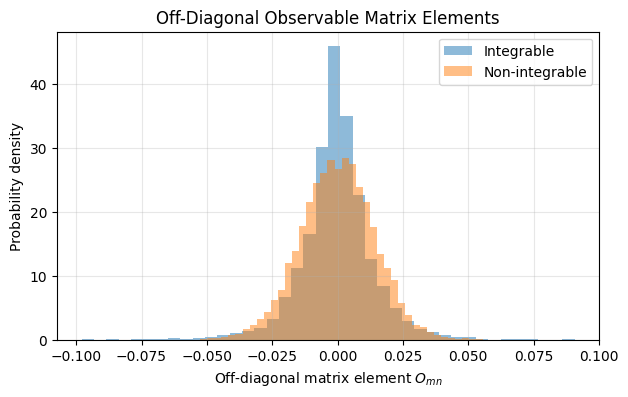

In [407]:
plt.figure(
    figsize=(7, 4)
)

plt.hist(
    offdiag_integrable,
    bins=40,
    density=True,
    alpha=0.5,
    label="Integrable"
)

plt.hist(
    offdiag_chaotic,
    bins=40,
    density=True,
    alpha=0.5,
    label="Non-integrable"
)

plt.xlabel(
    r"Off-diagonal matrix element $O_{mn}$"
)

plt.ylabel(
    "Probability density"
)

plt.title(
    "Off-Diagonal Observable Matrix Elements"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()

## 10.10 Connection with Long-Time Quantum Dynamics

For a non-degenerate spectrum, the infinite-time average of an observable is determined by its diagonal matrix elements.

Given

$$
|\psi(0)\rangle
=
\sum_n c_n|E_n\rangle,
$$

the long-time average is

$$
\overline{O}
=
\sum_n
|c_n|^2
O_{nn}.
$$

This expression defines the diagonal ensemble.

If ETH is valid and the initial state has a sufficiently narrow energy distribution, the diagonal matrix elements within the relevant energy window satisfy

$$
O_{nn}
\approx
\overline{O}(E_0).
$$

Consequently,

$$
\overline{O}
\approx
O_{\mathrm{microcanonical}}(E_0).
$$

This provides the microscopic connection between ETH and thermalization.

Unitary dynamics never becomes genuinely dissipative.

Instead, dephasing suppresses the contribution of off-diagonal terms, while ETH ensures that the remaining diagonal contribution is approximately thermal.

## 10.11 Physical Interpretation

The ETH analysis provides a microscopic interpretation of several observations made earlier in this project.

The spectral analysis showed that the non-integrable system approaches GOE statistics.

The real-time dynamics displayed stronger dephasing and smaller long-time fluctuations.

The entanglement entropy reached a larger and more stable plateau.

These phenomena can now be connected to the structure of the many-body eigenstates.

In the chaotic regime, nearby eigenstates are expected to give very similar expectation values for local observables,

$$
O_{nn}
\approx
\overline{O}(E_n).
$$

A state involving many eigenstates inside a narrow energy window therefore cannot distinguish strongly between them through local measurements.

After the off-diagonal phases dephase, local observables approach values determined primarily by the energy of the initial state.

The integrable system behaves differently because additional conserved quantities retain information not contained in the energy alone.

Energy is therefore insufficient to characterize its long-time state.

This explains why integrable systems generally require a description involving additional conserved quantities, whereas chaotic systems can often be described by conventional statistical ensembles.

## 10.12 Summary of the ETH Analysis

The Eigenstate Thermalization Hypothesis has been introduced to connect quantum chaos with the emergence of thermal behaviour in isolated many-body systems.

For a local observable $\hat O$, ETH predicts the structure

$$
O_{mn}
=
\overline{O}(E)\delta_{mn}
+
e^{-S(E)/2}
f(E,\omega)
R_{mn}.
$$

The diagonal matrix elements,

$$
O_{nn}
=
\langle E_n|\hat O|E_n\rangle,
$$

were studied using the central nearest-neighbour correlation

$$
\hat O
=
S_{L/2-1}^z
S_{L/2}^z.
$$

Because the analysis must be performed within a single symmetry sector, both the Hamiltonian and the observable were projected into a fixed magnetization and reflection-parity sector.

The diagonal ETH prediction states that, in a chaotic system,

$$
O_{nn}
$$

should form a smooth function of energy with small eigenstate-to-eigenstate fluctuations.

The integrable and non-integrable regimes can therefore be compared through the residual fluctuations

$$
\delta O_n
=
O_{nn}
-
\overline{O}(E_n).
$$

The off-diagonal elements

$$
O_{mn},
\qquad
m\neq n,
$$

were also introduced as the quantities responsible for temporal fluctuations around long-time expectation values.

Finally, the diagonal ensemble,

$$
\overline{O}
=
\sum_n
|c_n|^2O_{nn},
$$

provides the connection between eigenstate properties and non-equilibrium dynamics.

When ETH holds and the initial state occupies a sufficiently narrow energy window,

$$
\overline{O}
\approx
O_{\mathrm{microcanonical}}(E_0).
$$

The sequence developed throughout the project can therefore be extended to

$$
\boxed{
\text{integrability breaking}
\rightarrow
\text{GOE statistics}
\rightarrow
\text{chaotic eigenstates}
\rightarrow
\text{ETH}
\rightarrow
\text{thermalization}.
}
$$

This provides a microscopic connection between spectral quantum chaos and the apparent relaxation of isolated quantum many-body systems.

# 11. Conclusions and Outlook

## 11.1 Overview of the Project

This project investigated the emergence of quantum chaos in an interacting spin-$1/2$ XXZ chain using exact diagonalization.

The model considered was

$$
H(\lambda)
=
H_{\mathrm{NN}}
+
\lambda H_{\mathrm{NNN}},
$$

with

$$
H_{\mathrm{NN}}
=
J
\sum_{i=0}^{L-2}
\left(
S_i^xS_{i+1}^x
+
S_i^yS_{i+1}^y
+
\Delta S_i^zS_{i+1}^z
\right),
$$

and

$$
H_{\mathrm{NNN}}
=
J
\sum_{i=0}^{L-3}
\left(
S_i^xS_{i+2}^x
+
S_i^yS_{i+2}^y
+
\Delta S_i^zS_{i+2}^z
\right).
$$

The nearest-neighbour model,

$$
\lambda=0,
$$

provides an integrable reference point, whereas a finite next-nearest-neighbour coupling generically breaks integrability.

The objective was not only to identify quantum chaos through spectral statistics, but also to investigate its consequences for real-time dynamics, entanglement generation, and eigenstate thermalization.

The project therefore followed the chain

$$
\text{Hamiltonian construction}
\rightarrow
\text{symmetry resolution}
\rightarrow
\text{spectral statistics}
\rightarrow
\text{quantum dynamics}
\rightarrow
\text{entanglement}
\rightarrow
\text{ETH}.
$$

## 11.2 Numerical Framework

The numerical analysis was developed progressively from the full many-body Hilbert space to symmetry-resolved sparse representations.

For a chain of $L$ spin-$1/2$ degrees of freedom, the complete Hilbert-space dimension is

$$
\dim\mathcal H
=
2^L.
$$

Conservation of total magnetization,

$$
[H,S_{\mathrm{tot}}^z]=0,
$$

allows the Hamiltonian to be restricted to sectors with fixed particle number,

$$
D
=
\binom{L}{N_\uparrow}.
$$

The computational basis was represented using binary integers, with

$$
0\equiv\uparrow,
\qquad
1\equiv\downarrow.
$$

This representation allowed the Hamiltonian to be constructed directly through bit operations rather than repeated Kronecker products.

Because the XXZ Hamiltonian is local, the matrix is sparse.

A sparse COO representation was therefore used during construction and subsequently converted to CSR format for matrix-vector operations and Krylov-based calculations.

Spatial reflection symmetry was also resolved,

$$
[H,P]=0,
$$

allowing the fixed-magnetization sector to be decomposed into parity sectors

$$
p=\pm1.
$$

This symmetry resolution was essential for the spectral-statistics analysis because mixing statistically independent symmetry sectors can artificially destroy level repulsion.

Multiple independent consistency checks were implemented throughout the project, including Hermiticity, symmetry commutators, spectrum reconstruction from parity sectors, wave-function normalization, magnetization conservation, and entanglement identities.

## 11.3 Spectral Signatures of Quantum Chaos

The first signatures of quantum chaos were obtained from the energy spectrum.

For ordered eigenvalues

$$
E_1<E_2<\cdots,
$$

the neighbouring spacings were defined as

$$
s_n
=
E_{n+1}-E_n,
$$

and the adjacent-gap ratio as

$$
r_n
=
\frac{
\min(s_n,s_{n+1})
}{
\max(s_n,s_{n+1})
}.
$$

This observable is particularly useful because it does not require spectral unfolding.

The two universal reference values are

$$
\langle r\rangle_{\mathrm{Poisson}}
=
2\ln2-1
\approx
0.3863,
$$

for uncorrelated integrable spectra, and approximately

$$
\langle r\rangle_{\mathrm{GOE}}
\approx
0.5307,
$$

for chaotic systems belonging to the Gaussian Orthogonal Ensemble.

For the symmetry-resolved XXZ chain with

$$
L=12,
\qquad
N_\uparrow=7,
\qquad
p=+1,
\qquad
\Delta=0.7,
$$

the integrable point produced

$$
\langle r\rangle_{\lambda=0}
\approx
0.3825,
$$

in close agreement with the Poisson prediction.

When integrability was broken, the level statistics moved toward the GOE regime.

Finite-size scans showed that the agreement with random-matrix behaviour becomes clearer as the Hilbert-space dimension increases.

For example, for $L=14$ and $\lambda=0.5$, the calculation produced

$$
\langle r\rangle
\approx
0.519,
$$

which is much closer to the GOE reference than the smaller-system results.

Independent numerical random-matrix benchmarks reproduced the expected values for both Poisson and GOE statistics, validating the implementation of the spectral diagnostics.

## 11.4 Integrability-to-Chaos Crossover

Rather than comparing only isolated parameter values, the project investigated

$$
\langle r\rangle(\lambda,L).
$$

This revealed a continuous finite-size crossover between approximately Poisson and GOE-like statistics.

The parameter

$$
\lambda
$$

therefore acts as an integrability-breaking control parameter.

At

$$
\lambda=0,
$$

the spectrum retains the characteristic weak level correlations of an integrable model.

For intermediate values of $\lambda$, level repulsion develops and the spectrum approaches the GOE universality class.

The system-size dependence was essential for interpreting this crossover.

Small Hilbert spaces exhibit substantial fluctuations, whereas larger symmetry sectors provide increasingly stable spectral statistics.

The analysis also emphasized that

$$
\text{larger }\lambda
\neq
\text{necessarily more chaotic}.
$$

When one interaction dominates strongly over the others, the effective structure of the Hamiltonian can change again.

The chaotic regime is therefore associated with competition between interactions rather than simply with the magnitude of a single coupling.

## 11.5 Dynamical Signatures of Quantum Chaos

The analysis was subsequently extended from stationary spectra to non-equilibrium quantum dynamics.

Starting from a computational-basis product state,

$$
|\psi(0)\rangle,
$$

the state was evolved according to

$$
|\psi(t)\rangle
=
e^{-iHt}
|\psi(0)\rangle.
$$

The time evolution was evaluated using Krylov-based exponential propagation, avoiding the explicit construction of the dense operator

$$
e^{-iHt}.
$$

Several observables were used to quantify relaxation.

The survival probability,

$$
P(t)
=
|\langle\psi(0)|\psi(t)\rangle|^2,
$$

measures the memory of the complete initial state.

The local magnetization,

$$
\langle S_i^z(t)\rangle,
$$

and the spin imbalance,

$$
\mathcal I(t),
$$

probe spatial memory of the initial configuration.

Both integrable and non-integrable systems undergo substantial non-equilibrium evolution.

However, the non-integrable system displayed stronger dephasing and smaller long-time fluctuations.

For the survival probability, the late-time averages were approximately

$$
\overline{P}_{\mathrm{int}}
\approx
0.0076,
$$

and

$$
\overline{P}_{\mathrm{chaos}}
\approx
0.0037.
$$

The corresponding temporal fluctuations were also significantly smaller in the chaotic regime.

These results are consistent with more efficient exploration of the many-body Hilbert space after integrability is broken.

## 11.6 Entanglement and Information Spreading

A complementary picture emerged from the bipartite entanglement entropy.

For a spatial decomposition

$$
A\cup B,
$$

the reduced density matrix was defined as

$$
\rho_A
=
\operatorname{Tr}_B
|\psi\rangle\langle\psi|,
$$

and the von Neumann entropy as

$$
S_A
=
-\operatorname{Tr}
\left(
\rho_A\log\rho_A
\right).
$$

The initial computational-basis state satisfies

$$
S_A(0)=0,
$$

but interactions rapidly generate entanglement between the two halves of the chain.

Both the integrable and non-integrable systems display an approximately linear early-time growth regime.

The fitted effective entanglement-growth rates were

$$
v_E^{\mathrm{int}}
\approx
0.465,
$$

and

$$
v_E^{\mathrm{chaos}}
\approx
0.482.
$$

The difference in the initial growth rates is relatively small.

A much stronger distinction appears in the long-time regime.

The average half-chain entropies were found to be

$$
\overline{S_A}^{\mathrm{int}}
\approx
3.012,
$$

and

$$
\overline{S_A}^{\mathrm{chaos}}
\approx
3.380.
$$

The corresponding temporal fluctuations were

$$
\sigma_S^{\mathrm{int}}
\approx
0.0552,
$$

and

$$
\sigma_S^{\mathrm{chaos}}
\approx
0.0193.
$$

Thus, the chaotic system develops a larger and substantially more stable entanglement plateau.

Conservation of total magnetization restricts the allowed Schmidt structure.

For

$$
L=12,
\qquad
N_\uparrow=7,
\qquad
L_A=L_B=6,
$$

the maximum Schmidt rank is

$$
\chi_{\max}=44,
$$

giving the symmetry-constrained entropy bound

$$
S_A
\leq
\log44
\approx
3.784.
$$

The chaotic long-time entropy therefore reaches a large fraction of the entanglement accessible inside the conserved symmetry sector.

The Schmidt spectrum further revealed that the chaotic state distributes its weight over a broader set of Schmidt modes, whereas the integrable spectrum remains more strongly hierarchical.

## 11.7 Eigenstate Thermalization

The final stage of the project investigated the Eigenstate Thermalization Hypothesis.

For a local observable $\hat O$, ETH proposes the structure

$$
O_{mn}
=
\overline O(E)\delta_{mn}
+
e^{-S(E)/2}
f(E,\omega)R_{mn}.
$$

The central reflection-symmetric correlation

$$
\hat O
=
S_5^zS_6^z
$$

was used as a local observable.

The diagonal elements

$$
O_{nn}
=
\langle E_n|\hat O|E_n\rangle
$$

displayed substantially different behaviour in the two regimes.

In the integrable system, nearby eigenstates showed large variations in local expectation values.

In the non-integrable system, the same quantities formed a significantly smoother function of energy.

After subtracting a local microcanonical average, the fluctuation scales in the central spectral region were

$$
\sigma_{\mathrm{ETH}}^{\mathrm{int}}
\approx
0.0539,
$$

and

$$
\sigma_{\mathrm{ETH}}^{\mathrm{chaos}}
\approx
0.0244.
$$

The chaotic fluctuations are therefore less than half the integrable value.

This provides direct numerical evidence for the diagonal component of ETH.

The off-diagonal matrix elements displayed comparable global variances in the two regimes,

$$
\sigma_{\mathrm{off}}^{\mathrm{int}}
\approx
0.01420,
$$

and

$$
\sigma_{\mathrm{off}}^{\mathrm{chaos}}
\approx
0.01420.
$$

Their full distributions, however, showed different structures.

A more complete analysis of the off-diagonal ETH ansatz would require resolving the matrix elements as a function of

$$
\omega
=
E_m-E_n,
$$

rather than combining all frequency differences into a single distribution.

## 11.8 Unified Physical Picture

The different diagnostics considered throughout the project describe complementary manifestations of the same underlying crossover.

In the integrable regime,

$$
\lambda=0,
$$

the system exhibits approximately Poisson spectral statistics, large eigenstate-to-eigenstate fluctuations, stronger dynamical recurrences, and a lower and more strongly fluctuating entanglement plateau.

When integrability is broken, the spectrum develops level repulsion and approaches GOE statistics.

At the same time, local eigenstate expectation values become smoother functions of energy, consistent with ETH.

Real-time dynamics displays stronger dephasing and smaller late-time fluctuations, while the bipartite entanglement entropy approaches a larger and more stable saturation value.

The numerical results therefore support the qualitative sequence

$$
\boxed{
\text{integrability breaking}
\rightarrow
\text{level repulsion}
\rightarrow
\text{GOE statistics}
\rightarrow
\text{ETH-like eigenstates}
\rightarrow
\text{enhanced dephasing}
\rightarrow
\text{strong entanglement spreading}.
}
$$

These phenomena should not be interpreted as independent signatures.

They represent different spectral, dynamical, and informational manifestations of the transition from constrained integrable dynamics to chaotic many-body behaviour.

## 11.9 Limitations

The present analysis is necessarily restricted by the exponential growth of the many-body Hilbert space.

Exact diagonalization provides numerically exact results within machine precision, but the accessible system sizes remain small compared with the thermodynamic limit.

Most detailed calculations were therefore performed for

$$
L\lesssim14.
$$

Finite-size effects remain visible in several quantities, including the adjacent-gap ratio, ETH fluctuations, entanglement saturation, and dynamical recurrences.

Consequently, the numerical results should be interpreted as finite-size evidence for quantum-chaotic behaviour rather than as direct demonstrations of asymptotic thermodynamic-limit results.

The ETH analysis was also restricted to a single local observable,

$$
S_i^zS_{i+1}^z,
$$

and primarily to one non-integrable coupling,

$$
\lambda=0.5.
$$

A stronger test would investigate several independent local observables, multiple interaction strengths, and systematic finite-size scaling of ETH fluctuations.

Similarly, the off-diagonal ETH analysis considered the global distribution of matrix elements but did not fully resolve their frequency dependence,

$$
f(E,\omega).
$$

Finally, the time evolution was studied from a particular class of product initial states.

Different initial energy densities or magnetization patterns may display quantitatively different relaxation and entanglement dynamics.

## 11.10 Future Directions

Several natural extensions follow from the present work.

A first direction is to increase the accessible system size using iterative eigensolvers and matrix-free methods.

For spectral statistics near the centre of the spectrum, shift-invert techniques could provide larger symmetry-resolved spectra without requiring complete dense diagonalization.

For real-time dynamics, Krylov propagation already allows substantially larger Hilbert spaces than full diagonalization.

A second direction is a systematic finite-size study of ETH.

One may investigate the scaling of

$$
\sigma_{\mathrm{ETH}}(L)
$$

and test whether eigenstate-to-eigenstate fluctuations decrease with increasing Hilbert-space dimension as expected for chaotic systems.

The off-diagonal ETH ansatz can also be examined more directly by calculating

$$
\overline{|O_{mn}|^2}
$$

as a function of

$$
\omega=E_m-E_n.
$$

A third extension is the introduction of disorder.

Adding random longitudinal fields produces the disordered XXZ chain,

$$
H
=
H_{\mathrm{XXZ}}
+
\sum_i h_iS_i^z,
$$

which provides a natural setting for studying the competition between thermalization and many-body localization.

This would extend the present sequence

$$
\text{integrable}
\rightarrow
\text{chaotic}
$$

to

$$
\text{integrable}
\rightarrow
\text{thermal chaotic}
\rightarrow
\text{many-body localized}.
$$

A fourth direction is the use of tensor-network methods.

The Schmidt decomposition and entanglement entropy introduced in this project provide the conceptual foundation for Matrix Product States.

Methods such as DMRG and TEBD would allow one-dimensional systems substantially larger than those accessible through exact diagonalization.

Finally, the same numerical ideas can be extended toward lattice field theories and lattice gauge theories, where symmetry reduction, sparse Hamiltonians, entanglement, and real-time dynamics remain central computational tools.

## 11.11 Final Conclusions

This project developed a complete numerical investigation of quantum chaos in an interacting XXZ spin chain.

Starting from the microscopic Hamiltonian, exact diagonalization was combined with binary basis representations, sparse matrices, conserved magnetization, and reflection symmetry.

The integrable regime was shown to exhibit approximately Poisson spectral statistics, whereas integrability breaking produced level repulsion and GOE-like correlations.

The same crossover was visible beyond the energy spectrum.

Non-integrable dynamics exhibited stronger dephasing and smaller long-time fluctuations.

Bipartite entanglement reached a larger and more stable saturation value, with Schmidt weight distributed across a broader range of modes.

Finally, local eigenstate expectation values became significantly smoother in energy, providing finite-size evidence for the Eigenstate Thermalization Hypothesis.

The different diagnostics therefore support a consistent picture in which quantum chaos manifests simultaneously through spectral correlations, eigenstate structure, real-time relaxation, and quantum-information spreading.

The central conclusion of the project is that the transition from integrability to quantum chaos is not captured by a single observable.

Instead, it emerges coherently across multiple levels of the many-body problem:

$$
\boxed{
\text{spectrum}
\longleftrightarrow
\text{eigenstates}
\longleftrightarrow
\text{dynamics}
\longleftrightarrow
\text{entanglement}.
}
$$

Exact diagonalization provides a particularly transparent framework for revealing these connections.

Although limited to finite systems, it offers a controlled environment in which the microscopic origin and numerical signatures of many-body quantum chaos can be studied directly.

# References

[1] H. Bethe,  
*Zur Theorie der Metalle. I. Eigenwerte und Eigenfunktionen der linearen Atomkette*,  
Zeitschrift für Physik **71**, 205–226 (1931).  
https://doi.org/10.1007/BF01341708

[2] M. V. Berry and M. Tabor,  
*Level clustering in the regular spectrum*,  
Proceedings of the Royal Society of London A **356**, 375–394 (1977).  
https://doi.org/10.1098/rspa.1977.0140

[3] O. Bohigas, M. J. Giannoni, and C. Schmit,  
*Characterization of Chaotic Quantum Spectra and Universality of Level Fluctuation Laws*,  
Physical Review Letters **52**, 1–4 (1984).  
https://doi.org/10.1103/PhysRevLett.52.1

[4] M. L. Mehta,  
*Random Matrices*, 3rd ed.,  
Elsevier Academic Press (2004).

[5] F. Haake, S. Gnutzmann, and M. Kuś,  
*Quantum Signatures of Chaos*, 4th ed.,  
Springer (2018).  
https://doi.org/10.1007/978-3-319-97580-1

[6] Y. Y. Atas, E. Bogomolny, O. Giraud, and G. Roux,  
*Distribution of the Ratio of Consecutive Level Spacings in Random Matrix Ensembles*,  
Physical Review Letters **110**, 084101 (2013).  
https://doi.org/10.1103/PhysRevLett.110.084101

[7] L. F. Santos and M. Rigol,  
*Onset of quantum chaos in one-dimensional bosonic and fermionic systems and its relation to thermalization*,  
Physical Review E **81**, 036206 (2010).  
https://doi.org/10.1103/PhysRevE.81.036206

[8] L. F. Santos and M. Rigol,  
*Localization and the effects of symmetries in the thermalization properties of one-dimensional quantum systems*,  
Physical Review E **82**, 031130 (2010).  
https://doi.org/10.1103/PhysRevE.82.031130

[9] J. M. Deutsch,  
*Quantum statistical mechanics in a closed system*,  
Physical Review A **43**, 2046 (1991).  
https://doi.org/10.1103/PhysRevA.43.2046

[10] M. Srednicki,  
*Chaos and quantum thermalization*,  
Physical Review E **50**, 888 (1994).  
https://doi.org/10.1103/PhysRevE.50.888

[11] M. Rigol, V. Dunjko, and M. Olshanii,  
*Thermalization and its mechanism for generic isolated quantum systems*,  
Nature **452**, 854–858 (2008).  
https://doi.org/10.1038/nature06838

[12] L. D'Alessio, Y. Kafri, A. Polkovnikov, and M. Rigol,  
*From quantum chaos and eigenstate thermalization to statistical mechanics and thermodynamics*,  
Advances in Physics **65**, 239–362 (2016).  
https://doi.org/10.1080/00018732.2016.1198134

[13] P. Calabrese and J. Cardy,  
*Evolution of Entanglement Entropy in One-Dimensional Systems*,  
Journal of Statistical Mechanics: Theory and Experiment **2005**, P04010 (2005).  
https://doi.org/10.1088/1742-5468/2005/04/P04010

[14] D. N. Page,  
*Average entropy of a subsystem*,  
Physical Review Letters **71**, 1291–1294 (1993).  
https://doi.org/10.1103/PhysRevLett.71.1291

[15] E. H. Lieb and D. W. Robinson,  
*The finite group velocity of quantum spin systems*,  
Communications in Mathematical Physics **28**, 251–257 (1972).  
https://doi.org/10.1007/BF01645779

[16] A. H. Al-Mohy and N. J. Higham,  
*Computing the Action of the Matrix Exponential, with an Application to Exponential Integrators*,  
SIAM Journal on Scientific Computing **33**, 488–511 (2011).  
https://doi.org/10.1137/100788860

[17] P. Virtanen et al.,  
*SciPy 1.0: fundamental algorithms for scientific computing in Python*,  
Nature Methods **17**, 261–272 (2020).  
https://doi.org/10.1038/s41592-019-0686-2